# Tarea 2 - Inteligencia Artificial

## Integrantes:

- Fernando Cabrera (Desarrollo Parte 3)
- Magdalena Correa (Desarrollo Parte 1)
- Martin Melo (Desarrollo Parte 2)

# Tarea 2, Pregunta 1: Regresión lineal y regresión logística

Para esta pregunta usamos el dataset *Default of Credit Card Clients* del repositorio UCI. Reúne a 30.000 clientes de un banco de Taiwán en 2005 y, para cada uno, 23 atributos con su perfil, su historial de pagos, los montos facturados y los montos pagados, además de una etiqueta que indica si cayó en impago al mes siguiente. Con más de 20.000 filas y más de 12 columnas utilizables, cumple los requisitos del enunciado.

El objetivo es resolver dos problemas sobre los mismos datos: predecir una variable continua $Y_1$ con regresión lineal y una variable binaria $Y_2$ con regresión logística. Ambos modelos usan las mismas diez variables predictoras $X_1, \dots, X_{10}$, y de cada uno entrenamos tres versiones: con las diez variables, con las cinco más relevantes y con las tres más relevantes. La selección de variables se hace solo con el conjunto de entrenamiento. Las tres versiones se comparan en entrenamiento y validación, y solo las dos mejores de cada tarea llegan al conjunto de prueba. Con eso analizamos si aparece overfitting o underfitting al cambiar la cantidad de variables.

El notebook sigue este orden:

1. Carga, limpieza y definición de las variables.
2. División en 70 % entrenamiento, 15 % validación y 15 % prueba, la misma para ambas tareas.
3. Selección de variables con *forward selection* y validación cruzada dentro del entrenamiento.
4. Entrenamiento y comparación de las tres versiones de cada modelo.
5. Evaluación en prueba de las dos mejores versiones.
6. Análisis del efecto de la cantidad de variables sobre el desempeño y la generalización.

## 1. Librerías y configuración

Fijamos una semilla al inicio para que todos los resultados del notebook sean reproducibles.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams['figure.dpi'] = 110

## 2. Carga de datos

El archivo `.xls` original trae dos filas de encabezado: la primera con los códigos `X1 ... X23, Y` y la segunda con los nombres reales de las columnas. Por eso lo leemos con `header=1`. Para abrir archivos `.xls`, pandas necesita la librería `xlrd`.

In [ ]:
RUTA_DATOS = 'Datasets/default of credit card clients.xls'

df_raw = pd.read_excel(RUTA_DATOS, header=1)
df_raw = df_raw.rename(columns={'default payment next month': 'DEFAULT'})

print('Dimensiones:', df_raw.shape)
print('Valores nulos totales:', int(df_raw.isna().sum().sum()))
print('Filas duplicadas (sin contar ID):', int(df_raw.drop(columns=['ID']).duplicated().sum()))
df_raw.head()

El dataset no tiene valores nulos. Sí aparecen 35 filas duplicadas, pero no son errores de registro: corresponden a clientes distintos, con `ID` diferente, que coinciden en todos sus atributos. Casi todos son clientes sin facturación ni pagos, con todos los montos en cero, así que es natural que se repitan. Como son clientes reales, los mantenemos.

### Descripción de las columnas

El cuadro resume el significado de cada columna según la documentación de UCI.

| Columna | Descripción |
|---|---|
| `ID` | Identificador del cliente (no se usa) |
| `LIMIT_BAL` | Monto del crédito otorgado (dólares NT), incluye crédito individual y familiar |
| `SEX` | 1 = hombre, 2 = mujer |
| `EDUCATION` | 1 = postgrado, 2 = universitaria, 3 = secundaria, 4 = otros (0, 5 y 6 no documentados) |
| `MARRIAGE` | 1 = casado, 2 = soltero, 3 = otros (0 no documentado) |
| `AGE` | Edad en años |
| `PAY_0`, `PAY_2` ... `PAY_6` | Estado de pago en septiembre, agosto, ..., abril. -1 = pagó a tiempo, 1 = un mes de atraso, 2 = dos meses, etc. (-2 y 0 indican sin consumo o pago mínimo) |
| `BILL_AMT1` ... `BILL_AMT6` | Monto facturado de septiembre a abril |
| `PAY_AMT1` ... `PAY_AMT6` | Monto pagado de septiembre a abril |
| `DEFAULT` | 1 = el cliente cae en impago el mes siguiente, 0 = no |

## 3. Definición de variables objetivo y predictoras

Como variable continua $Y_1$ elegimos `LIMIT_BAL`, el cupo de crédito que el banco le asigna a cada cliente. El problema de regresión consiste en estimar qué cupo le corresponde a un cliente a partir de su perfil y de su comportamiento reciente de facturación y pago. Es una variable continua con un rango amplio, que va desde 10.000 hasta 1.000.000.

Como variable binaria $Y_2$ usamos `DEFAULT`, que indica si el cliente cae en impago el mes siguiente. Es la etiqueta original del dataset y un problema clásico de clasificación binaria.

Las diez variables predictoras son las mismas en ambas tareas, y las elegimos para cubrir los tres tipos de información que trae el dataset:

| # | Variable | Grupo | Tratamiento |
|---|---|---|---|
| X1 | `SEX` | Perfil | Se recodifica a 0 = hombre, 1 = mujer |
| X2 | `EDUCATION` | Perfil | Los códigos 0, 5 y 6 (no documentados) se agrupan en 4 = otros. Se trata como ordinal |
| X3 | `MARRIED` | Perfil | `MARRIAGE` es nominal, se convierte en indicador 1 = casado, 0 = otro |
| X4 | `AGE` | Perfil | Sin cambios |
| X5 | `PAY_0` | Historial de pago | Estado de pago del mes más reciente |
| X6 | `PAY_2` | Historial de pago | Estado de pago del mes anterior |
| X7 | `BILL_AMT1` | Facturación | Monto facturado del mes más reciente |
| X8 | `BILL_AMT2` | Facturación | Monto facturado del mes anterior |
| X9 | `PAY_AMT1` | Pagos | Monto pagado del mes más reciente |
| X10 | `PAY_AMT2` | Pagos | Monto pagado del mes anterior |

Para llegar a esta lista seguimos cuatro criterios. Primero, de cada serie mensual (estado de pago, facturación y pagos) tomamos solo los dos meses más recientes, porque son los que reflejan el comportamiento actual del cliente y permiten quedarse en diez variables sin perder ningún tipo de información. Los meses más antiguos están muy correlacionados con los recientes y aportarían poco. Segundo, incluimos el perfil demográfico, que podría influir tanto en el cupo asignado como en el riesgo. Tercero, dejamos fuera las columnas que no pueden ser predictoras: `ID` es un identificador y `LIMIT_BAL` es $Y_1$, así que, como las variables deben ser las mismas en las dos tareas, tampoco la usamos para predecir $Y_2$. Por la misma razón `DEFAULT` no entra en la regresión. Cuarto, dejamos a propósito pares de variables correlacionadas, como `BILL_AMT1` y `BILL_AMT2`, para comprobar si la selección de variables es capaz de detectar la información redundante.

In [3]:
df = df_raw.drop(columns=['ID']).copy()

# EDUCATION: los codigos 0, 5 y 6 no estan documentados, se agrupan en 4 (otros)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# SEX: 1 = hombre, 2 = mujer  ->  0 = hombre, 1 = mujer
df['SEX'] = (df['SEX'] == 2).astype(int)

# MARRIAGE es nominal, se transforma en un indicador binario (1 = casado)
df['MARRIED'] = (df['MARRIAGE'] == 1).astype(int)

Y1 = 'LIMIT_BAL'
Y2 = 'DEFAULT'
PREDICTORAS = ['SEX', 'EDUCATION', 'MARRIED', 'AGE',
               'PAY_0', 'PAY_2',
               'BILL_AMT1', 'BILL_AMT2',
               'PAY_AMT1', 'PAY_AMT2']

data = df[PREDICTORAS + [Y1, Y2]]
print('Dimensiones del conjunto de trabajo:', data.shape)
data.describe().T

Dimensiones del conjunto de trabajo: (30000, 12)


,count,mean,std,min,25%,50%,75%,max
SEX,"30,000.0000",0.6037,0.4891,0.0000,0.0000,1.0000,1.0000,1.0000
EDUCATION,"30,000.0000",1.8423,0.7445,1.0000,1.0000,2.0000,2.0000,4.0000
MARRIED,"30,000.0000",0.4553,0.4980,0.0000,0.0000,0.0000,1.0000,1.0000
AGE,"30,000.0000",35.4855,9.2179,21.0000,28.0000,34.0000,41.0000,79.0000
PAY_0,"30,000.0000",-0.0167,1.1238,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_2,"30,000.0000",-0.1338,1.1972,-2.0000,-1.0000,0.0000,0.0000,8.0000
BILL_AMT1,"30,000.0000","51,223.3309","73,635.8606","-165,580.0000","3,558.7500","22,381.5000","67,091.0000","964,511.0000"
BILL_AMT2,"30,000.0000","49,179.0752","71,173.7688","-69,777.0000","2,984.7500","21,200.0000","64,006.2500","983,931.0000"
PAY_AMT1,"30,000.0000","5,663.5805","16,563.2804",0.0000,"1,000.0000","2,100.0000","5,006.0000","873,552.0000"
PAY_AMT2,"30,000.0000","5,921.1635","23,040.8704",0.0000,833.0000,"2,009.0000","5,000.0000","1,684,259.0000"


## 4. División en entrenamiento, validación y prueba

Hacemos una sola división, compartida por ambas tareas: 70 % entrenamiento, 15 % validación y 15 % prueba. Primero separamos el 70 % de entrenamiento y después dividimos el 30 % restante en dos mitades iguales.

La división está estratificada según `DEFAULT`, porque las clases están desbalanceadas: cerca del 22 % de los clientes cae en impago. Así los tres conjuntos mantienen la misma proporción de clases, como se ve en la tabla de abajo. La semilla queda fija para que los resultados sean reproducibles.

In [4]:
X = data[PREDICTORAS]
y1 = data[Y1]
y2 = data[Y2]

X_train, X_temp, y1_train, y1_temp, y2_train, y2_temp = train_test_split(
    X, y1, y2, test_size=0.30, stratify=y2, random_state=SEED)

X_val, X_test, y1_val, y1_test, y2_val, y2_test = train_test_split(
    X_temp, y1_temp, y2_temp, test_size=0.50, stratify=y2_temp, random_state=SEED)

resumen_split = pd.DataFrame({
    'Filas': [len(X_train), len(X_val), len(X_test)],
    'Porcentaje': [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    'Media LIMIT_BAL': [y1_train.mean(), y1_val.mean(), y1_test.mean()],
    'Tasa DEFAULT': [y2_train.mean(), y2_val.mean(), y2_test.mean()],
}, index=['Entrenamiento', 'Validacion', 'Prueba'])
resumen_split

,Filas,Porcentaje,Media LIMIT_BAL,Tasa DEFAULT
Entrenamiento,21000,0.7000,"167,499.1429",0.2212
Validacion,4500,0.1500,"166,086.6667",0.2211
Prueba,4500,0.1500,"168,812.8178",0.2213


## 5. Exploración del conjunto de entrenamiento

Exploramos solo el conjunto de entrenamiento, para que ninguna decisión posterior use información de validación o de prueba.

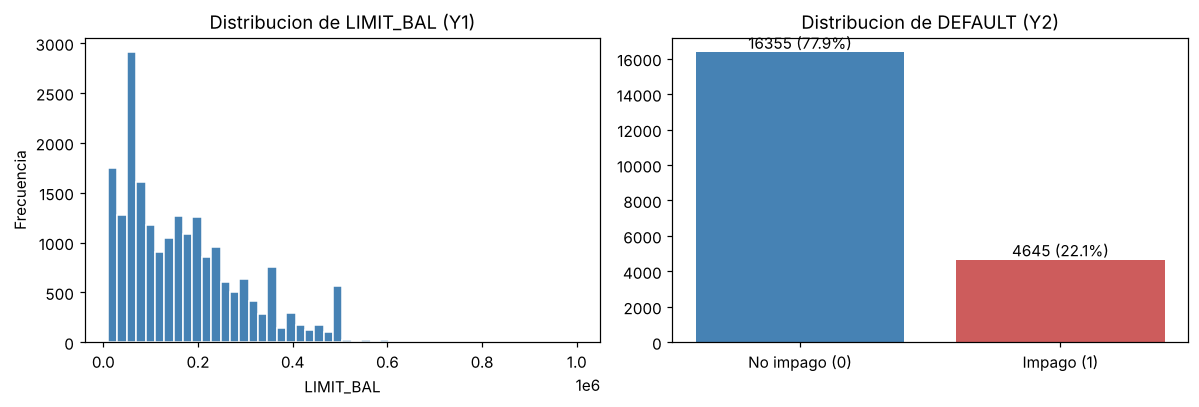

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(y1_train, bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribucion de LIMIT_BAL (Y1)')
axes[0].set_xlabel('LIMIT_BAL')
axes[0].set_ylabel('Frecuencia')

conteo = y2_train.value_counts().sort_index()
axes[1].bar(['No impago (0)', 'Impago (1)'], conteo.values, color=['steelblue', 'indianred'])
for i, v in enumerate(conteo.values):
    axes[1].text(i, v, f'{v} ({v / conteo.sum():.1%})', ha='center', va='bottom')
axes[1].set_title('Distribucion de DEFAULT (Y2)')

plt.tight_layout()
plt.show()

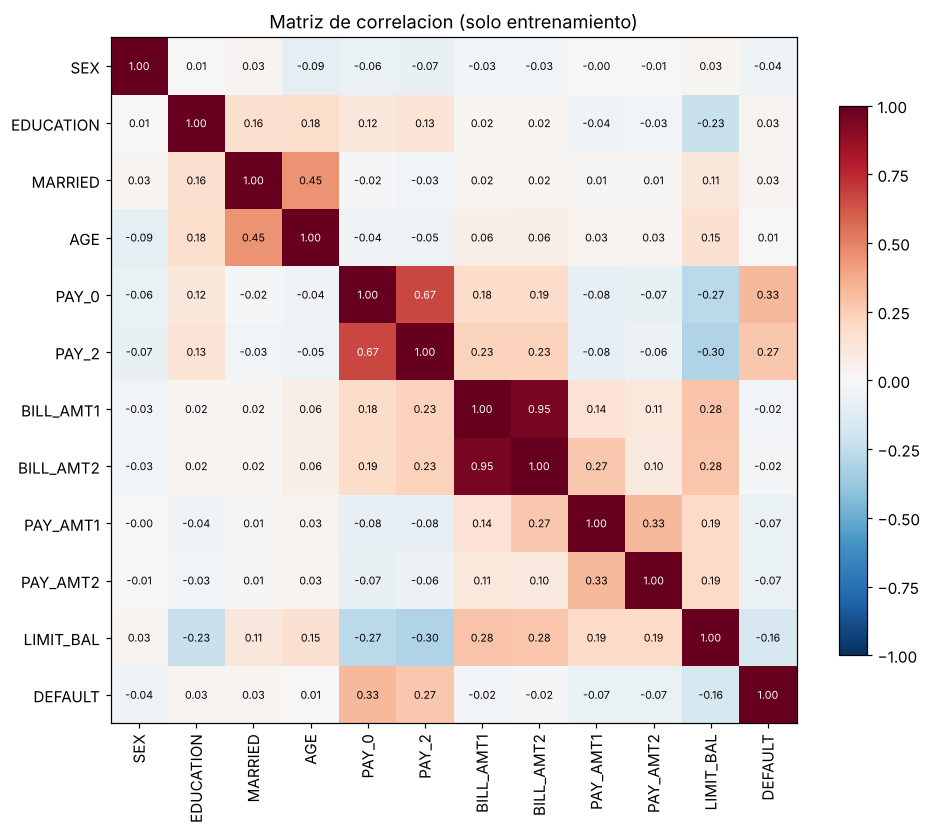

In [6]:
corr = pd.concat([X_train, y1_train, y2_train], axis=1).corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Matriz de correlacion (solo entrenamiento)')
plt.tight_layout()
plt.show()

De la matriz de correlación sacamos dos observaciones que importan para la selección de variables. La primera es que hay pares muy correlacionados entre sí, como `BILL_AMT1` con `BILL_AMT2` y `PAY_0` con `PAY_2`. Si eligiéramos las variables solo por su correlación con el objetivo, probablemente nos quedaríamos con las dos de cada par, aunque la segunda aporte poca información nueva. La segunda es que las correlaciones con $Y_1$ y con $Y_2$ son bastante distintas, así que es esperable que las variables más relevantes no sean las mismas en las dos tareas.

## 6. Método de selección de variables

Para ordenar las variables usamos selección secuencial hacia adelante (*forward selection*) con validación cruzada de 5 folds sobre el conjunto de entrenamiento. El procedimiento parte sin variables y, en cada paso, prueba agregar cada una de las que faltan y mide el desempeño promedio de la validación cruzada. La variable que más mejora la métrica se incorpora al modelo, y el proceso se repite hasta ordenar las diez. El resultado es un ranking: las tres más relevantes son las tres primeras y las cinco más relevantes son las cinco primeras, por lo que los subconjuntos quedan anidados.

Elegimos este método por tres razones:

- Usa solo datos de entrenamiento, como exige el enunciado. Validación y prueba no participan en la selección.
- A diferencia de un ranking por correlación, mide cuánto aporta cada variable dado lo que ya está en el modelo, así que tiende a evitar las variables redundantes.
- La selección se hace con el mismo tipo de modelo que después se entrena, por lo que es coherente con cada tarea.

La métrica de selección depende de la tarea. En la regresión lineal usamos $R^2$, que equivale a minimizar el error cuadrático medio, es decir, la función de costo $J(\theta)$ de la regresión lineal. En la regresión logística usamos ROC-AUC, porque no depende del umbral de decisión y es robusta al desbalance de clases. El accuracy habría sido engañoso: un modelo que siempre predice "no impago" tendría cerca de 78 % de accuracy sin haber aprendido nada.

Sobre los modelos hay que tener en cuenta tres detalles. Ambos se entrenan dentro de un *pipeline* con `StandardScaler`, que se ajusta solo con los datos de cada fold de entrenamiento, de modo que no se filtra información de los folds de validación. `LinearRegression` minimiza la misma función de costo vista en clases, pero la resuelve de forma cerrada en vez de usar gradiente descendente. `LogisticRegression` minimiza la función de costo logística (log-loss) con regularización L2 y `C = 1`, la opción por defecto, que corresponde al término de regularización visto en la clase 14. Además usamos `class_weight='balanced'` para que el modelo no ignore la clase minoritaria, que en este problema es justamente la que interesa detectar.

In [7]:
def crear_modelo_regresion():
    return make_pipeline(StandardScaler(), LinearRegression())


def crear_modelo_clasificacion():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000))


def seleccion_forward(X, y, crear_modelo, scoring, cv):
    # Ordena todas las variables agregando en cada paso la que mas mejora el score de CV
    restantes = list(X.columns)
    elegidas = []
    historial = []
    while restantes:
        puntajes = {}
        for var in restantes:
            cols = elegidas + [var]
            puntajes[var] = cross_val_score(crear_modelo(), X[cols], y,
                                            scoring=scoring, cv=cv).mean()
        mejor = max(puntajes, key=puntajes.get)
        elegidas.append(mejor)
        restantes.remove(mejor)
        historial.append({'Paso': len(elegidas),
                          'Variable agregada': mejor,
                          f'{scoring} CV (5 folds)': puntajes[mejor]})
    return elegidas, pd.DataFrame(historial).set_index('Paso')


def metricas_regresion(y_true, y_pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


def metricas_clasificacion(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'ROC_AUC': roc_auc_score(y_true, y_prob)}


def graficar_curva_seleccion(historial, titulo, etiqueta):
    col = historial.columns[-1]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(historial.index, historial[col], marker='o')
    for k in (3, 5):
        ax.axvline(k, color='gray', ls='--', lw=0.8)
        ax.text(k, ax.get_ylim()[0], f' {k} var.', color='gray', va='bottom')
    ax.set_xticks(historial.index, [f'{i}\n{v}' for i, v in historial['Variable agregada'].items()],
                  fontsize=7)
    ax.set_ylabel(etiqueta)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

---
# Tarea A: Regresión lineal para predecir `LIMIT_BAL` ($Y_1$)

## A.1 Selección de variables (solo entrenamiento)

Junto al ranking de *forward selection* calculamos la correlación absoluta de cada variable con $Y_1$. Ese segundo ranking no se usa para elegir nada; sirve solo como referencia para ver en qué se diferencian ambos criterios.

In [8]:
orden_reg, hist_reg = seleccion_forward(X_train, y1_train, crear_modelo_regresion,
                                        scoring='r2', cv=cv_reg)

# Ranking por correlacion absoluta con Y1, solo como referencia para comparar
corr_y1 = X_train.corrwith(y1_train).abs().sort_values(ascending=False)

hist_reg['|corr| con Y1 de la variable'] = hist_reg['Variable agregada'].map(corr_y1)
hist_reg['Ranking por |corr|'] = hist_reg['Variable agregada'].map(
    {v: i + 1 for i, v in enumerate(corr_y1.index)})

print('Top 5 por forward selection:', orden_reg[:5])
print('Top 3 por forward selection:', orden_reg[:3])
print('Top 5 por correlacion      :', list(corr_y1.index[:5]))
hist_reg

Top 5 por forward selection: ['PAY_2', 'BILL_AMT1', 'EDUCATION', 'AGE', 'PAY_AMT2']
Top 3 por forward selection: ['PAY_2', 'BILL_AMT1', 'EDUCATION']
Top 5 por correlacion      : ['PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_0', 'EDUCATION']


,Variable agregada,r2 CV (5 folds),|corr| con Y1 de la variable,Ranking por |corr|
Paso,,,,
1,PAY_2,0.0898,0.3005,1
2,BILL_AMT1,0.2229,0.2848,2
3,EDUCATION,0.2566,0.2258,5
4,AGE,0.2783,0.1507,8
5,PAY_AMT2,0.2891,0.1940,6
6,PAY_0,0.2975,0.2687,4
7,MARRIED,0.3016,0.1098,9
8,PAY_AMT1,0.3031,0.1928,7
9,SEX,0.3036,0.0300,10


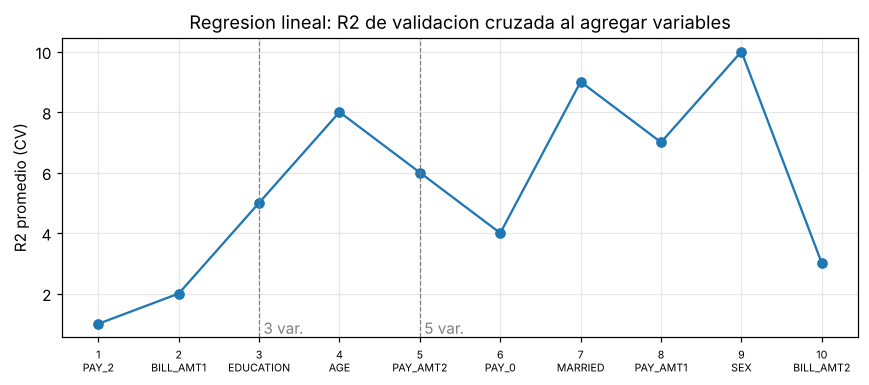

In [9]:
graficar_curva_seleccion(hist_reg, 'Regresion lineal: R2 de validacion cruzada al agregar variables',
                         'R2 promedio (CV)')

La tabla muestra el orden en que entraron las variables y el $R^2$ promedio de validación cruzada alcanzado en cada paso. La columna "Ranking por |corr|" permite compararlo con una selección ingenua por correlación, y la diferencia más clara está en `BILL_AMT2`. Es la tercera variable más correlacionada con $Y_1$, pero *forward selection* la deja en el último lugar: una vez que `BILL_AMT1` está en el modelo, su pareja casi no agrega información, e incluso al incorporarla el $R^2$ de validación cruzada baja levemente, de 0,3036 a 0,3033.

La curva también muestra que la mejora se concentra en las primeras variables. Con tres se llega a un $R^2$ de 0,26 y con cinco a 0,29, mientras que las últimas cinco suman apenas 0,014.

## A.2 Entrenamiento de las tres versiones y comparación en entrenamiento y validación

Entrenamos las tres versiones con el conjunto de entrenamiento completo y las medimos en entrenamiento y validación con RMSE, MAE y $R^2$. La última columna muestra la brecha de $R^2$ entre ambos conjuntos, que es la señal que usamos para detectar overfitting.

In [10]:
versiones_reg = {
    '10 variables': PREDICTORAS,
    '5 variables': orden_reg[:5],
    '3 variables': orden_reg[:3],
}

modelos_reg = {}
filas = []
for nombre, cols in versiones_reg.items():
    modelo = crear_modelo_regresion().fit(X_train[cols], y1_train)
    modelos_reg[nombre] = modelo
    for conjunto, Xc, yc in [('Entrenamiento', X_train, y1_train), ('Validacion', X_val, y1_val)]:
        filas.append({'Version': nombre, 'Conjunto': conjunto,
                      **metricas_regresion(yc, modelo.predict(Xc[cols]))})

res_reg = pd.DataFrame(filas)
tabla_reg = res_reg.pivot(index='Version', columns='Conjunto', values=['RMSE', 'MAE', 'R2'])
tabla_reg = tabla_reg.loc[list(versiones_reg)]
tabla_reg[('R2', 'Brecha (train - val)')] = tabla_reg[('R2', 'Entrenamiento')] - tabla_reg[('R2', 'Validacion')]

for nombre, cols in versiones_reg.items():
    print(f'{nombre}: {cols}')
tabla_reg

10 variables: ['SEX', 'EDUCATION', 'MARRIED', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
5 variables: ['PAY_2', 'BILL_AMT1', 'EDUCATION', 'AGE', 'PAY_AMT2']
3 variables: ['PAY_2', 'BILL_AMT1', 'EDUCATION']


RMSE                        MAE              \
Conjunto     Entrenamiento   Validacion Entrenamiento  Validacion   
Version                                                             
10 variables  107,682.4873 107,252.5034   82,877.9693 82,908.0408   
5 variables   109,018.8681 109,062.1151   84,160.0120 84,416.3110   
3 variables   111,847.4706 111,275.7528   86,616.4477 86,691.1485   

                        R2                                  
Conjunto     Entrenamiento Validacion Brecha (train - val)  
Version                                                     
10 variables        0.3114     0.3025               0.0089  
5 variables         0.2942     0.2788               0.0154  
3 variables         0.2571     0.2492               0.0079

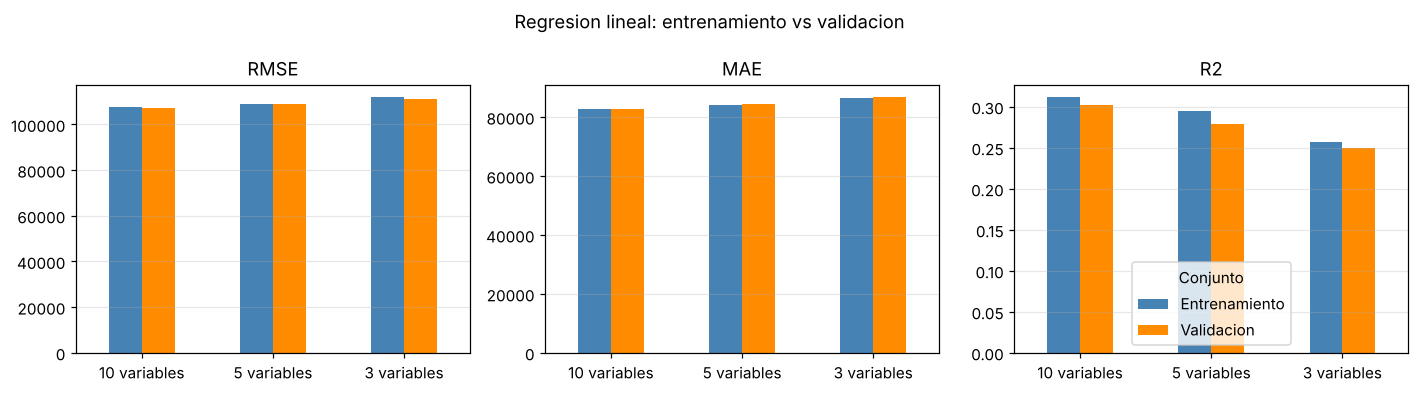

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, met in zip(axes, ['RMSE', 'MAE', 'R2']):
    piv = res_reg.pivot(index='Version', columns='Conjunto', values=met).loc[list(versiones_reg)]
    piv.plot(kind='bar', ax=ax, rot=0, color=['steelblue', 'darkorange'], legend=(met == 'R2'))
    ax.set_title(met)
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=0.3)
plt.suptitle('Regresion lineal: entrenamiento vs validacion')
plt.tight_layout()
plt.show()

In [12]:
coef_reg = pd.DataFrame({
    nombre: pd.Series(modelo[-1].coef_, index=versiones_reg[nombre])
    for nombre, modelo in modelos_reg.items()
}).loc[PREDICTORAS]
print('Coeficientes estandarizados (cambio en LIMIT_BAL por una desviacion estandar de cada variable):')
coef_reg

Coeficientes estandarizados (cambio en LIMIT_BAL por una desviacion estandar de cada variable):


,10 variables,5 variables,3 variables
SEX,"3,325.1729",NaN,NaN
EDUCATION,"-27,583.3785","-27,331.9586","-24,059.2502"
MARRIED,"9,142.5839",NaN,NaN
AGE,"15,264.2362","19,189.7708",NaN
PAY_0,"-15,629.7576",NaN,NaN
PAY_2,"-32,385.0007","-43,806.0198","-47,029.0555"
BILL_AMT1,"43,076.7452","44,910.2394","48,431.5761"
BILL_AMT2,"1,338.0757",NaN,NaN
PAY_AMT1,"8,667.9373",NaN,NaN
PAY_AMT2,"13,036.3769","16,265.6797",NaN


## A.3 Evaluación en prueba de las dos mejores versiones

Elegimos las dos mejores versiones según el $R^2$ de validación, lo que equivale a elegir las de menor RMSE. El conjunto de prueba se usa solo en este paso.

In [13]:
val_reg = res_reg[res_reg['Conjunto'] == 'Validacion'].set_index('Version')
mejores_reg = val_reg.sort_values('R2', ascending=False).index[:2].tolist()
print('Dos mejores versiones en validacion:', mejores_reg)

filas = []
for nombre in mejores_reg:
    cols = versiones_reg[nombre]
    filas.append({'Version': nombre,
                  **metricas_regresion(y1_test, modelos_reg[nombre].predict(X_test[cols]))})
test_reg = pd.DataFrame(filas).set_index('Version')
test_reg

Dos mejores versiones en validacion: ['10 variables', '5 variables']


,RMSE,MAE,R2
Version,,,
10 variables,"109,059.2766","84,281.1953",0.3065
5 variables,"111,187.5954","85,740.8201",0.2791


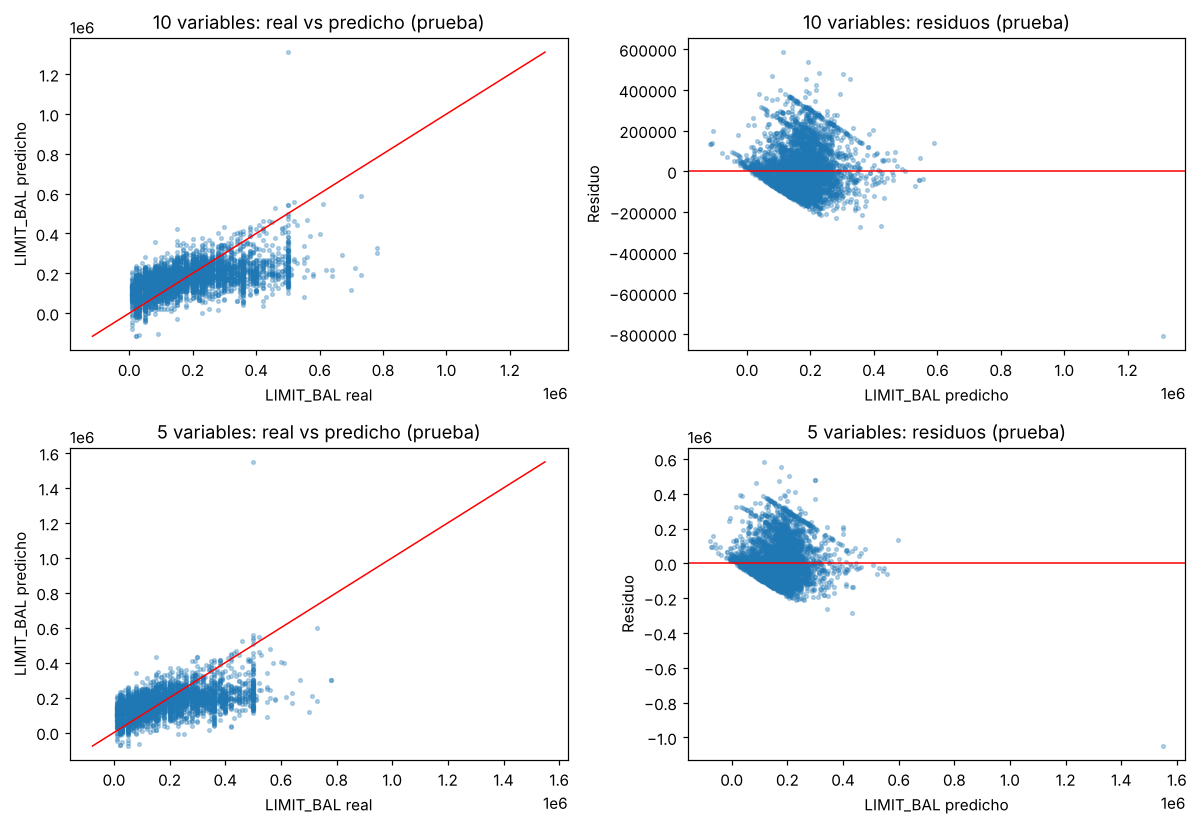

In [14]:
fig, axes = plt.subplots(len(mejores_reg), 2, figsize=(11, 3.8 * len(mejores_reg)))
for fila, nombre in zip(np.atleast_2d(axes), mejores_reg):
    cols = versiones_reg[nombre]
    pred = modelos_reg[nombre].predict(X_test[cols])
    res = y1_test - pred

    fila[0].scatter(y1_test, pred, s=6, alpha=0.3)
    lim = [min(y1_test.min(), pred.min()), max(y1_test.max(), pred.max())]
    fila[0].plot(lim, lim, color='red', lw=1)
    fila[0].set_xlabel('LIMIT_BAL real')
    fila[0].set_ylabel('LIMIT_BAL predicho')
    fila[0].set_title(f'{nombre}: real vs predicho (prueba)')

    fila[1].scatter(pred, res, s=6, alpha=0.3)
    fila[1].axhline(0, color='red', lw=1)
    fila[1].set_xlabel('LIMIT_BAL predicho')
    fila[1].set_ylabel('Residuo')
    fila[1].set_title(f'{nombre}: residuos (prueba)')
plt.tight_layout()
plt.show()

---
# Tarea B: Regresión logística para predecir `DEFAULT` ($Y_2$)

## B.1 Selección de variables (solo entrenamiento)

Repetimos el mismo procedimiento, ahora con ROC-AUC como métrica y con folds estratificados, para que cada uno mantenga la proporción de impagos.

In [15]:
orden_clf, hist_clf = seleccion_forward(X_train, y2_train, crear_modelo_clasificacion,
                                        scoring='roc_auc', cv=cv_clf)

corr_y2 = X_train.corrwith(y2_train).abs().sort_values(ascending=False)
hist_clf['|corr| con Y2 de la variable'] = hist_clf['Variable agregada'].map(corr_y2)
hist_clf['Ranking por |corr|'] = hist_clf['Variable agregada'].map(
    {v: i + 1 for i, v in enumerate(corr_y2.index)})

print('Top 5 por forward selection:', orden_clf[:5])
print('Top 3 por forward selection:', orden_clf[:3])
print('Top 5 por correlacion      :', list(corr_y2.index[:5]))
hist_clf

Top 5 por forward selection: ['PAY_0', 'PAY_AMT2', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1']
Top 3 por forward selection: ['PAY_0', 'PAY_AMT2', 'PAY_2']
Top 5 por correlacion      : ['PAY_0', 'PAY_2', 'PAY_AMT1', 'PAY_AMT2', 'SEX']


,Variable agregada,roc_auc CV (5 folds),|corr| con Y2 de la variable,Ranking por |corr|
Paso,,,,
1,PAY_0,0.6925,0.3274,1
2,PAY_AMT2,0.7110,0.0666,4
3,PAY_2,0.7146,0.2678,2
4,BILL_AMT1,0.7180,0.0249,8
5,PAY_AMT1,0.7186,0.0701,3
6,BILL_AMT2,0.7199,0.0198,9
7,SEX,0.7198,0.0426,5
8,MARRIED,0.7201,0.0256,7
9,AGE,0.7198,0.0074,10


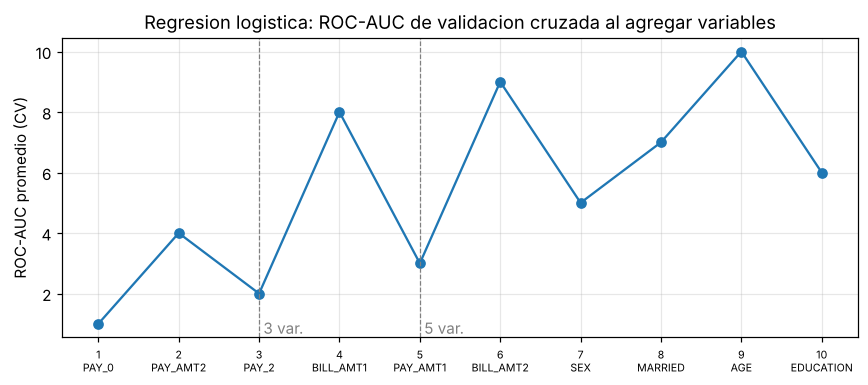

In [16]:
graficar_curva_seleccion(hist_clf, 'Regresion logistica: ROC-AUC de validacion cruzada al agregar variables',
                         'ROC-AUC promedio (CV)')

## B.2 Entrenamiento de las tres versiones y comparación en entrenamiento y validación

En clasificación reportamos varias métricas, porque cada una mide algo distinto:

| Métrica | Qué mide |
|---|---|
| Accuracy | Proporción de aciertos. Es poco informativa con clases desbalanceadas |
| Precision | De los clientes que el modelo marca como impago, qué fracción realmente cae en impago |
| Recall | De los clientes que realmente caen en impago, qué fracción detecta el modelo |
| F1 | Media armónica entre precision y recall |
| ROC-AUC | Capacidad de ordenar a los clientes por riesgo, sin depender del umbral |

El ROC-AUC es la métrica principal para comparar versiones. Las predicciones de clase usan un umbral de 0,5 sobre la probabilidad estimada.

In [17]:
versiones_clf = {
    '10 variables': PREDICTORAS,
    '5 variables': orden_clf[:5],
    '3 variables': orden_clf[:3],
}

modelos_clf = {}
filas = []
for nombre, cols in versiones_clf.items():
    modelo = crear_modelo_clasificacion().fit(X_train[cols], y2_train)
    modelos_clf[nombre] = modelo
    for conjunto, Xc, yc in [('Entrenamiento', X_train, y2_train), ('Validacion', X_val, y2_val)]:
        prob = modelo.predict_proba(Xc[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)
        filas.append({'Version': nombre, 'Conjunto': conjunto,
                      **metricas_clasificacion(yc, pred, prob)})

res_clf = pd.DataFrame(filas)
metricas_c = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
tabla_clf = res_clf.pivot(index='Version', columns='Conjunto', values=metricas_c)
tabla_clf = tabla_clf.loc[list(versiones_clf)]
tabla_clf[('ROC_AUC', 'Brecha (train - val)')] = (tabla_clf[('ROC_AUC', 'Entrenamiento')]
                                                  - tabla_clf[('ROC_AUC', 'Validacion')])

for nombre, cols in versiones_clf.items():
    print(f'{nombre}: {cols}')
tabla_clf

10 variables: ['SEX', 'EDUCATION', 'MARRIED', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
5 variables: ['PAY_0', 'PAY_AMT2', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1']
3 variables: ['PAY_0', 'PAY_AMT2', 'PAY_2']


Accuracy                Precision                   Recall  \
Conjunto     Entrenamiento Validacion Entrenamiento Validacion Entrenamiento   
Version                                                                        
10 variables        0.7167     0.7062        0.4055     0.3914        0.6026   
5 variables         0.7163     0.7078        0.4057     0.3920        0.6073   
3 variables         0.7837     0.7820        0.5108     0.5073        0.5197   

                                   F1                  ROC_AUC             \
Conjunto     Validacion Entrenamiento Validacion Entrenamiento Validacion   
Version                                                                     
10 variables     0.5920        0.4848     0.4712        0.7200     0.7072   
5 variables      0.5839        0.4864     0.4691        0.7188     0.7077   
3 variables      0.4894        0.5152     0.4982        0.7148     0.7043   

                                   
Conjunto     Brecha (train - val)  
Version                            
10 variables               0.0128  
5 variables                0.0111  
3 variables                0.0105

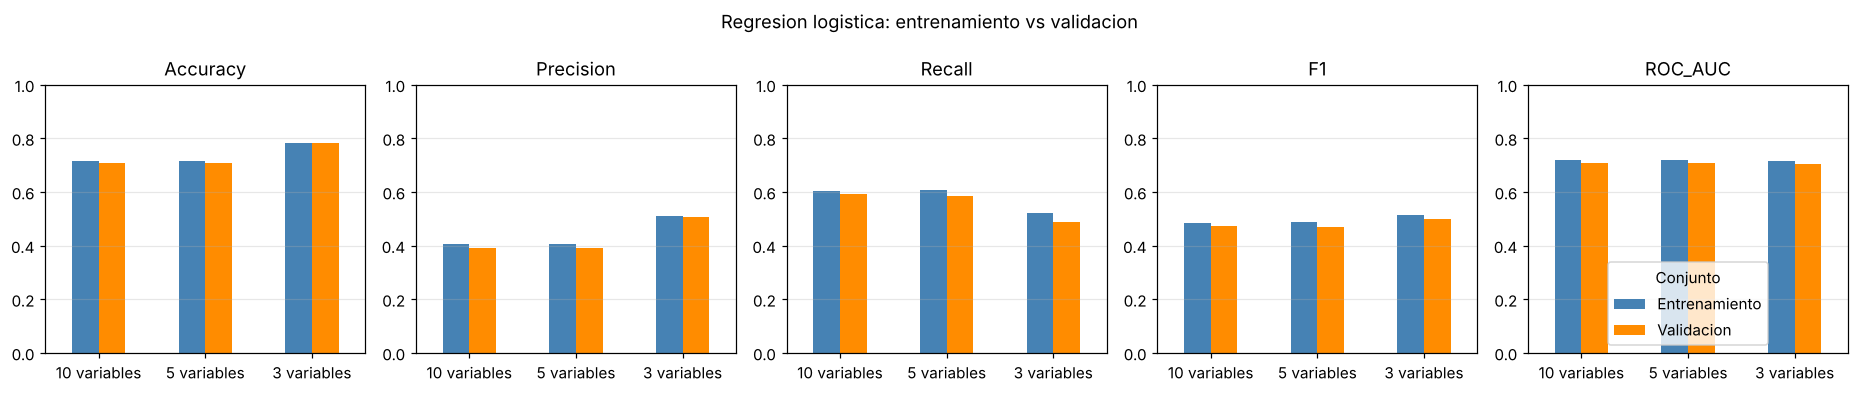

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, met in zip(axes, metricas_c):
    piv = res_clf.pivot(index='Version', columns='Conjunto', values=met).loc[list(versiones_clf)]
    piv.plot(kind='bar', ax=ax, rot=0, color=['steelblue', 'darkorange'], legend=(met == 'ROC_AUC'))
    ax.set_title(met)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
plt.suptitle('Regresion logistica: entrenamiento vs validacion')
plt.tight_layout()
plt.show()

In [19]:
coef_clf = pd.DataFrame({
    nombre: pd.Series(modelo[-1].coef_[0], index=versiones_clf[nombre])
    for nombre, modelo in modelos_clf.items()
}).loc[PREDICTORAS]
print('Coeficientes estandarizados (cambio en el log-odds de impago por una desviacion estandar):')
coef_clf

Coeficientes estandarizados (cambio en el log-odds de impago por una desviacion estandar):


,10 variables,5 variables,3 variables
SEX,-0.0614,NaN,NaN
EDUCATION,-0.0586,NaN,NaN
MARRIED,0.0847,NaN,NaN
AGE,0.0378,NaN,NaN
PAY_0,0.6146,0.6157,0.6006
PAY_2,0.2303,0.2256,0.1985
BILL_AMT1,-0.4194,-0.1970,NaN
BILL_AMT2,0.2285,NaN,NaN
PAY_AMT1,-0.1696,-0.1248,NaN
PAY_AMT2,-0.2457,-0.2452,-0.3970


## B.3 Evaluación en prueba de las dos mejores versiones

Elegimos las dos mejores versiones según el ROC-AUC de validación y, en caso de empate, desempatamos por F1. Igual que en la regresión, el conjunto de prueba se usa solo en este paso.

In [20]:
val_clf = res_clf[res_clf['Conjunto'] == 'Validacion'].set_index('Version')
mejores_clf = val_clf.sort_values(['ROC_AUC', 'F1'], ascending=False).index[:2].tolist()
print('Dos mejores versiones en validacion:', mejores_clf)

filas = []
for nombre in mejores_clf:
    cols = versiones_clf[nombre]
    prob = modelos_clf[nombre].predict_proba(X_test[cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    filas.append({'Version': nombre, **metricas_clasificacion(y2_test, pred, prob)})
test_clf = pd.DataFrame(filas).set_index('Version')
test_clf

Dos mejores versiones en validacion: ['5 variables', '10 variables']


,Accuracy,Precision,Recall,F1,ROC_AUC
Version,,,,,
5 variables,0.7102,0.3964,0.5914,0.4746,0.7080
10 variables,0.7093,0.3967,0.6014,0.4781,0.7148


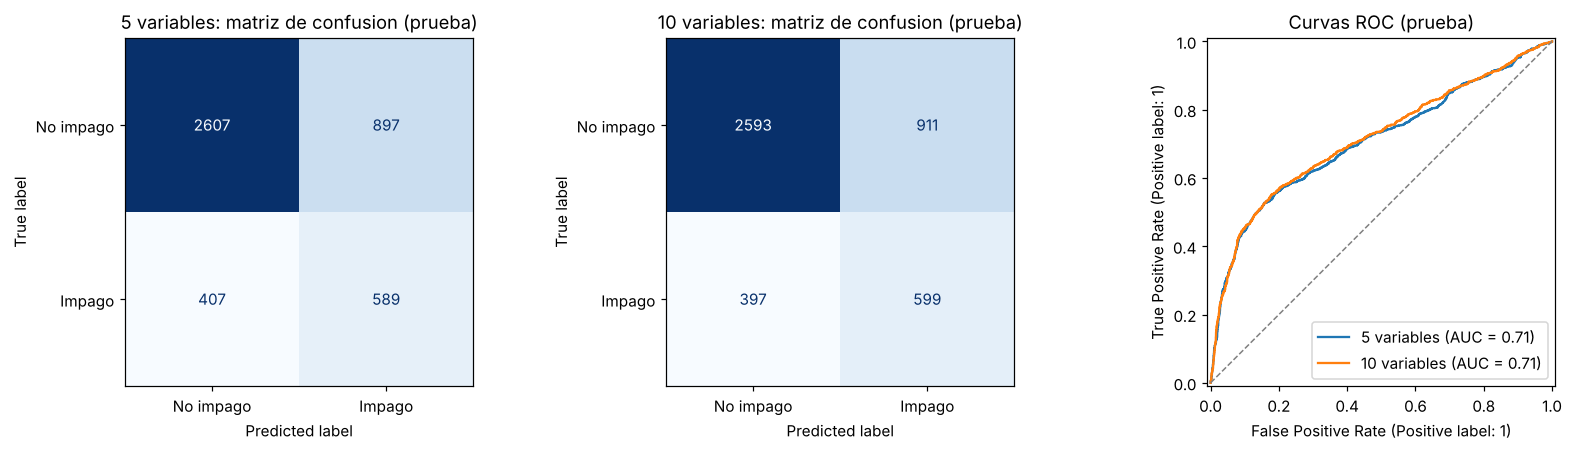

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, nombre in zip(axes[:2], mejores_clf):
    cols = versiones_clf[nombre]
    pred = modelos_clf[nombre].predict(X_test[cols])
    ConfusionMatrixDisplay(confusion_matrix(y2_test, pred),
                           display_labels=['No impago', 'Impago']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{nombre}: matriz de confusion (prueba)')

for nombre in mejores_clf:
    cols = versiones_clf[nombre]
    RocCurveDisplay.from_estimator(modelos_clf[nombre], X_test[cols], y2_test, ax=axes[2], name=nombre)
axes[2].plot([0, 1], [0, 1], ls='--', color='gray', lw=1)
axes[2].set_title('Curvas ROC (prueba)')
plt.tight_layout()
plt.show()

---
# Análisis: efecto de la cantidad de variables

Las versiones de 3, 5 y 10 variables son solo tres puntos de una curva más completa. Para ver esa curva, entrenamos un modelo para cada tamaño $k = 1, \dots, 10$ siguiendo el orden de *forward selection*, y lo medimos en entrenamiento y validación. Este análisis tampoco usa el conjunto de prueba.

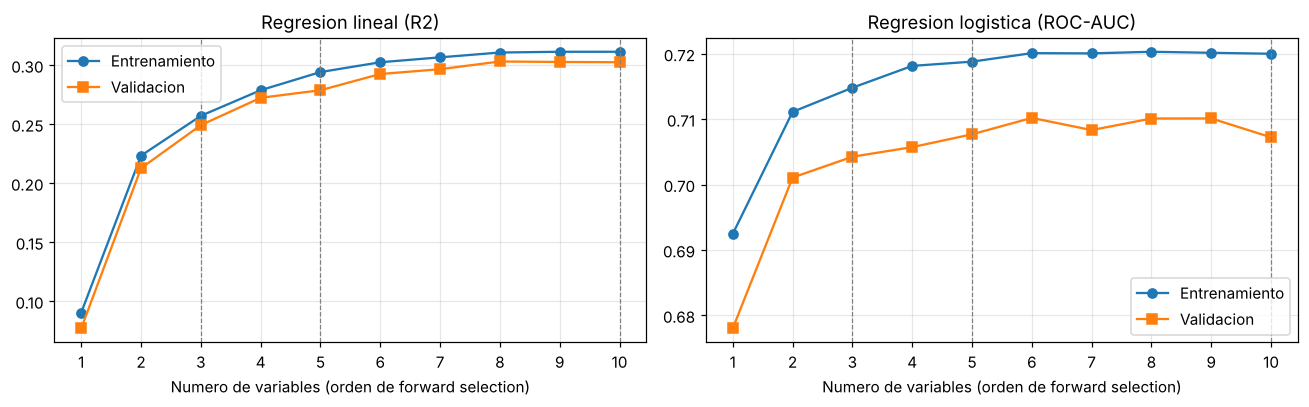

,R2 train,R2 val,AUC train,AUC val
k,,,,
1,0.0903,0.0769,0.6924,0.6780
2,0.2233,0.2127,0.7111,0.7011
3,0.2571,0.2492,0.7148,0.7043
4,0.2788,0.2723,0.7181,0.7057
5,0.2942,0.2788,0.7188,0.7077
6,0.3025,0.2925,0.7201,0.7102
7,0.3066,0.2966,0.7201,0.7083
8,0.3107,0.3031,0.7203,0.7101
9,0.3114,0.3027,0.7201,0.7101


In [22]:
curvas = []
for k in range(1, len(PREDICTORAS) + 1):
    cols_r = orden_reg[:k]
    m_r = crear_modelo_regresion().fit(X_train[cols_r], y1_train)
    cols_c = orden_clf[:k]
    m_c = crear_modelo_clasificacion().fit(X_train[cols_c], y2_train)
    curvas.append({
        'k': k,
        'R2 train': r2_score(y1_train, m_r.predict(X_train[cols_r])),
        'R2 val': r2_score(y1_val, m_r.predict(X_val[cols_r])),
        'AUC train': roc_auc_score(y2_train, m_c.predict_proba(X_train[cols_c])[:, 1]),
        'AUC val': roc_auc_score(y2_val, m_c.predict_proba(X_val[cols_c])[:, 1]),
    })
curvas = pd.DataFrame(curvas).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (tr, va, titulo) in zip(axes, [('R2 train', 'R2 val', 'Regresion lineal (R2)'),
                                        ('AUC train', 'AUC val', 'Regresion logistica (ROC-AUC)')]):
    ax.plot(curvas.index, curvas[tr], marker='o', label='Entrenamiento')
    ax.plot(curvas.index, curvas[va], marker='s', label='Validacion')
    for k in (3, 5, 10):
        ax.axvline(k, color='gray', ls='--', lw=0.8)
    ax.set_xticks(curvas.index)
    ax.set_xlabel('Numero de variables (orden de forward selection)')
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
curvas

## Resumen de resultados

La siguiente celda reúne en un solo lugar las cifras que se discuten más abajo: el $R^2$ y el ROC-AUC de cada versión en entrenamiento y validación, y el resultado en prueba de las dos mejores versiones de cada tarea.

In [23]:
def fila_resumen(tabla, metrica):
    return tabla[[(metrica, 'Entrenamiento'), (metrica, 'Validacion'), (metrica, 'Brecha (train - val)')]]

print('REGRESION LINEAL (Y1 = LIMIT_BAL)')
print(fila_resumen(tabla_reg, 'R2').round(4).to_string())
print('Mejores en validacion:', mejores_reg)
print(test_reg.round(4).to_string())
print()
print('REGRESION LOGISTICA (Y2 = DEFAULT)')
print(fila_resumen(tabla_clf, 'ROC_AUC').round(4).to_string())
print('Mejores en validacion:', mejores_clf)
print(test_clf.round(4).to_string())

REGRESION LINEAL (Y1 = LIMIT_BAL)
                        R2                                
Conjunto     Entrenamiento Validacion Brecha (train - val)
Version                                                   
10 variables        0.3114     0.3025               0.0089
5 variables         0.2942     0.2788               0.0154
3 variables         0.2571     0.2492               0.0079
Mejores en validacion: ['10 variables', '5 variables']
                     RMSE         MAE     R2
Version                                     
10 variables 109,059.2766 84,281.1953 0.3065
5 variables  111,187.5954 85,740.8201 0.2791

REGRESION LOGISTICA (Y2 = DEFAULT)
                   ROC_AUC                                
Conjunto     Entrenamiento Validacion Brecha (train - val)
Version                                                   
10 variables        0.7200     0.7072               0.0128
5 variables         0.7188     0.7077               0.0111
3 variables         0.7148     0.7043         

## Discusión

### Regresión lineal ($Y_1$ = `LIMIT_BAL`)

El $R^2$ es bajo en las tres versiones: 0,30 en validación con diez variables, 0,28 con cinco y 0,25 con tres. El modelo explica menos de un tercio de la variabilidad del cupo, lo que indica underfitting: un modelo lineal con estas variables no alcanza a capturar cómo el banco asigna los cupos.

Los gráficos de prueba lo confirman. La nube de puntos es más plana que la diagonal, es decir, el modelo comprime sus predicciones hacia el centro. Para el 10 % de clientes con mayor cupo predice en promedio cerca de 230.000, cuando el valor real promedio es cercano a 430.000, y en el otro extremo sobrestima los cupos bajos. Además predice cupos negativos para 37 clientes de prueba, algo imposible en la realidad, y genera unas pocas predicciones extremas, sobre 1.000.000, para clientes con montos de pago atípicos. Las franjas diagonales que aparecen en los residuos no son un error del modelo: se deben a que `LIMIT_BAL` toma valores redondos, múltiplos de 10.000.

La mejor versión en validación es la de diez variables, seguida de la de cinco, y esas dos son las que evaluamos en prueba. Pasar de diez a cinco variables cuesta 0,024 de $R^2$, y pasar de cinco a tres cuesta 0,030 más: con tres variables el modelo pierde información útil y el underfitting se acentúa. La selección sí detectó la redundancia que habíamos dejado a propósito. `BILL_AMT2` quedó en el último lugar del ranking y su coeficiente en el modelo de diez variables es prácticamente cero (1.338, frente a 43.077 de `BILL_AMT1`), lo que confirma que, una vez incluida `BILL_AMT1`, no agrega información.

No hay overfitting. La brecha entre entrenamiento y validación es de 0,01 a 0,02 puntos de $R^2$ en todas las versiones, y en prueba el $R^2$ es prácticamente igual al de validación (0,31 con diez variables y 0,28 con cinco). Esto era esperable: con 21.000 ejemplos de entrenamiento y a lo más 11 parámetros, un modelo lineal tiene muy poca capacidad para memorizar los datos.

### Regresión logística ($Y_2$ = `DEFAULT`)

El estado de pago más reciente, `PAY_0`, es por lejos la variable más relevante: por sí sola alcanza un ROC-AUC de 0,69 en validación cruzada, frente a 0,72 con todas las variables. Las que entran después aportan mejoras pequeñas, y las últimas no mejoran o incluso empeoran levemente el resultado. Por eso las tres versiones tienen un ROC-AUC muy parecido en validación, entre 0,704 y 0,708.

La mejor versión en validación fue la de cinco variables, seguida muy de cerca por la de diez, con una diferencia de 0,0005. En prueba el orden se invierte: 0,715 con diez variables y 0,708 con cinco. Esto merece una explicación, porque podría leerse como que la selección se equivocó. Lo que muestra en realidad es que la diferencia entre ambas versiones es menor que la variación propia de evaluar sobre muestras de 4.500 clientes. En la práctica rinden igual, y la de cinco variables es preferible por ser más simple.

Sobre overfitting hay solo una señal muy débil. En la curva de la sección anterior, el ROC-AUC de entrenamiento se mantiene estable al pasar de ocho a diez variables, mientras que el de validación baja un poco. La brecha entre entrenamiento y validación también crece levemente con el número de variables, de 0,011 con tres y cinco variables a 0,013 con diez. Esto sugiere que las últimas variables empiezan a ajustarse a particularidades del entrenamiento más que a información útil, pero la diferencia es demasiado pequeña para hablar de un overfitting relevante.

Las métricas que dependen del umbral cuentan una historia algo distinta, y conviene entender por qué. Como el modelo usa `class_weight='balanced'`, prioriza detectar impagos: el recall, cercano a 0,6, es mayor que la precision, cercana a 0,4. Es decir, detecta alrededor del 60 % de los clientes que caen en impago a costa de bastantes falsas alarmas. Por lo mismo, el accuracy de las versiones de cinco y diez variables (0,71) queda por debajo del 78 % que lograría el clasificador trivial, lo que muestra por qué no es una buena métrica en este problema.

La versión de tres variables, en cambio, tiene el mejor accuracy (0,78) y el mejor F1 (0,50) en validación, pese a tener el menor ROC-AUC. Sus probabilidades se distribuyen de otra forma, y el umbral fijo de 0,5 la deja en otro punto del compromiso entre precision y recall: marca a menos clientes como impago, gana precision y pierde recall. Por eso comparamos las versiones con ROC-AUC, que mide la capacidad de ordenar a los clientes por riesgo. El umbral se puede ajustar después según el costo de cada tipo de error.

En el modelo de diez variables, `BILL_AMT1` y `BILL_AMT2` tienen coeficientes de signo opuesto (-0,42 y 0,23). Es un efecto típico de la multicolinealidad: como las dos variables se mueven casi juntas, el modelo reparte su efecto entre ambas y los coeficientes individuales dejan de ser interpretables por separado.

Igual que en la regresión, la limitación principal es el underfitting. Una frontera de decisión lineal no captura bien relaciones como el efecto de `PAY_0`, cuyos valores -2, -1 y 0 representan situaciones distintas que no siguen una escala lineal.

### Conclusión sobre la cantidad de variables

Agregar variables mejora el desempeño solo mientras aportan información nueva. En ambas tareas las curvas se aplanan después de las primeras cinco o seis variables, y las restantes resultan redundantes o poco informativas.

Más variables no produjeron un overfitting relevante, porque los modelos lineales tienen poca capacidad y el conjunto de entrenamiento es grande. Solo en la regresión logística aparece una señal muy débil al agregar las últimas. La conclusión no es que el overfitting no importe, sino que en este caso no es el problema. Sería un riesgo real con modelos mucho más flexibles, por ejemplo con muchas interacciones o términos polinomiales, o con pocos datos, y ahí sí convendría una regularización más fuerte (clase 14) o una selección de variables más agresiva.

El problema dominante es el underfitting, sobre todo en la regresión. Para mejorar habría que darle más capacidad al modelo, con transformaciones como el logaritmo de los montos, codificación one-hot de `PAY_0` o interacciones, más que agregar o quitar variables.

La mejor elección depende de la tarea. En la regresión, las variables adicionales sí aportan y conviene usar las diez. En la clasificación, la versión de cinco variables rinde igual que la de diez con un modelo más simple e interpretable.

# Tarea 2, Pregunta 2: Aprendizaje supervisado y semisupervisado

En esta pregunta usamos el dataset *Letter Recognition* del repositorio UCI. Tiene 20.000 imágenes de letras mayúsculas del alfabeto inglés, generadas a partir de 20 tipografías con distorsiones aleatorias. Cada imagen viene descrita por 16 características numéricas enteras, entre 0 y 15, que resumen la posición, el tamaño y la distribución de los píxeles, y la etiqueta $Y$ es la letra, con 26 clases. El dataset cumple los requisitos del enunciado (más de 15.000 filas, más de 7 características y una etiqueta discreta con más de dos clases) y es distinto del que usamos en la pregunta 1.

La pregunta de fondo es si vale la pena aprovechar los datos que no tienen etiqueta. Para responderla comparamos el aprendizaje supervisado, que entrena solo con las muestras etiquetadas, con el aprendizaje semisupervisado, que además asigna pseudoetiquetas a los datos no etiquetados a partir de un clustering.

El experimento sigue estos pasos:

1. División en 80 % entrenamiento y 20 % prueba. El conjunto de prueba no participa en ninguna decisión.
2. Dos escenarios: solo el 10 % o solo el 30 % del entrenamiento tiene etiqueta conocida.
3. Clustering del entrenamiento con K-Means y DBSCAN, con tres configuraciones por técnica.
4. Pseudoetiquetado que busca dejar el 60 % del entrenamiento con etiqueta, real o estimada.
5. Para cada uno de los seis enfoques (regresión logística y SVM, cada una supervisada, con K-Means o con DBSCAN), selección de hiperparámetros entre tres configuraciones por validación cruzada, usando solo etiquetas reales conocidas.
6. Evaluación final en prueba con tres semillas aleatorias y análisis de los resultados.

## 1. Librerías y configuración

Aquí quedan definidos la semilla de la división, las tres semillas del experimento, los dos escenarios y el objetivo de cobertura del 60 %. Todo lo demás depende de estos valores, así que cambiarlos aquí basta para repetir el experimento con otra configuración.

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, silhouette_score

warnings.filterwarnings('ignore', category=FutureWarning)

SEED_SPLIT = 42                       # semilla fija de la division entrenamiento / prueba
SEMILLAS = [0, 1, 2]                  # semillas para repetir todo el experimento
ESCENARIOS = {'10%': 0.10, '30%': 0.30}
OBJETIVO_COBERTURA = 0.60             # fraccion del entrenamiento que se busca dejar etiquetada
N_FOLDS = 5

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams['figure.dpi'] = 110

## 2. Carga y exploración de datos

El archivo `letter-recognition.data` no trae encabezado. La primera columna es la letra y las 16 siguientes son las características, a las que les pusimos los nombres de la documentación de UCI.

In [ ]:
COLUMNAS = ['letra', 'x_box', 'y_box', 'width', 'high', 'onpix', 'x_bar', 'y_bar', 'x2bar',
            'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x_ege', 'xegvy', 'y_ege', 'yegvx']
df = pd.read_csv('Datasets/letter-recognition.data', header=None, names=COLUMNAS)

print('Dimensiones:', df.shape)
print('Clases:', df['letra'].nunique())
print('Valores nulos:', int(df.isna().sum().sum()))
print('Filas duplicadas:', int(df.duplicated().sum()))
df.head()

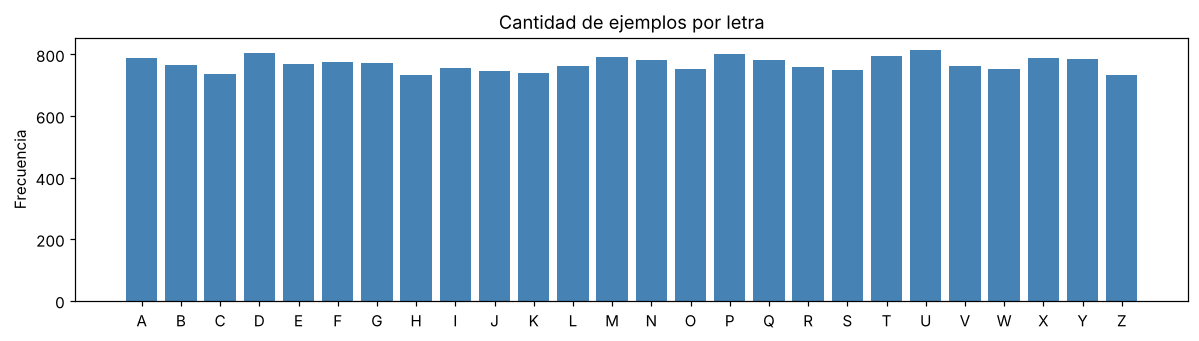

Minimo por clase: 734, maximo por clase: 813


In [ ]:
conteo = df['letra'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(conteo.index, conteo.values, color='steelblue')
ax.set_title('Cantidad de ejemplos por letra')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()
print(f'Minimo por clase: {conteo.min()}, maximo por clase: {conteo.max()}')

Las 26 clases están prácticamente balanceadas, con entre 734 y 813 ejemplos cada una, y no hay valores nulos. Las 1.332 filas duplicadas tienen una explicación simple: como las características son enteros entre 0 y 15, dos imágenes distintas pueden quedar con exactamente la misma descripción. Son observaciones válidas, así que las mantenemos.

## 3. División de datos y escenarios

Separamos el 80 % de los datos para entrenamiento y el 20 % para prueba, de forma estratificada por letra y con una semilla fija. El conjunto de prueba es el mismo en todas las repeticiones, para que los resultados se puedan comparar entre semillas.

Las características se estandarizan con la media y la desviación estándar del entrenamiento, porque K-Means, DBSCAN, la SVM y la regresión logística regularizada dependen de distancias o de la escala de los coeficientes. Esto no filtra información: el escalador no usa etiquetas, y en un problema semisupervisado las características de los datos no etiquetados sí son conocidas.

En cada escenario elegimos al azar, de forma estratificada, el 10 % o el 30 % del entrenamiento como datos etiquetados. El resto se trata como no etiquetado, y sus etiquetas reales nunca se usan para entrenar ni para tomar decisiones. Solo las usamos al final, como diagnóstico, para medir qué tan buenas resultaron las pseudoetiquetas. Como la elección de los etiquetados depende de la semilla, cada una de las tres semillas genera un experimento distinto.

In [ ]:
X = df.drop(columns='letra').values.astype(float)
y = df['letra'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED_SPLIT)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
N_TRAIN = len(y_train)


def elegir_etiquetados(frac, semilla):
    idx, _ = train_test_split(np.arange(N_TRAIN), train_size=frac,
                              stratify=y_train, random_state=semilla)
    return np.sort(idx)


filas = []
for esc, frac in ESCENARIOS.items():
    n_lab = len(elegir_etiquetados(frac, SEMILLAS[0]))
    n_obj = int(round(OBJETIVO_COBERTURA * N_TRAIN))
    filas.append({'Escenario': esc, 'Etiquetados reales': n_lab, 'No etiquetados': N_TRAIN - n_lab,
                  'Objetivo 60%': n_obj, 'Pseudoetiquetas necesarias': n_obj - n_lab,
                  'Por clase (aprox.)': n_lab / 26})
print(f'Entrenamiento: {N_TRAIN} filas, prueba: {len(y_test)} filas')
pd.DataFrame(filas).set_index('Escenario')

Entrenamiento: 16000 filas, prueba: 4000 filas


,Etiquetados reales,No etiquetados,Objetivo 60%,Pseudoetiquetas necesarias,Por clase (aprox.)
Escenario,,,,,
10%,1600,14400,9600,8000,61.5385
30%,4800,11200,9600,4800,184.6154


Para llegar al 60 % del entrenamiento hay que pseudoetiquetar 8.000 de los 14.400 datos no etiquetados en el escenario del 10 %, es decir, el 56 % de ellos, y 4.800 de los 11.200 en el escenario del 30 %, que corresponden al 43 %. El escenario del 10 % es entonces el más exigente por partida doble: hay que estimar más etiquetas y con menos información para hacerlo, ya que cada letra tiene solo unos 62 ejemplos etiquetados.

## 4. Clustering: elección de configuraciones

### 4.1 K-Means

K-Means minimiza la suma de las distancias cuadradas de cada punto a su centroide (WCSS). Antes de elegir las configuraciones revisamos el método del codo y el coeficiente de silueta para un rango de valores de $k$. La silueta se calcula sobre una muestra de 4.000 puntos, porque sobre los 16.000 su costo es alto.

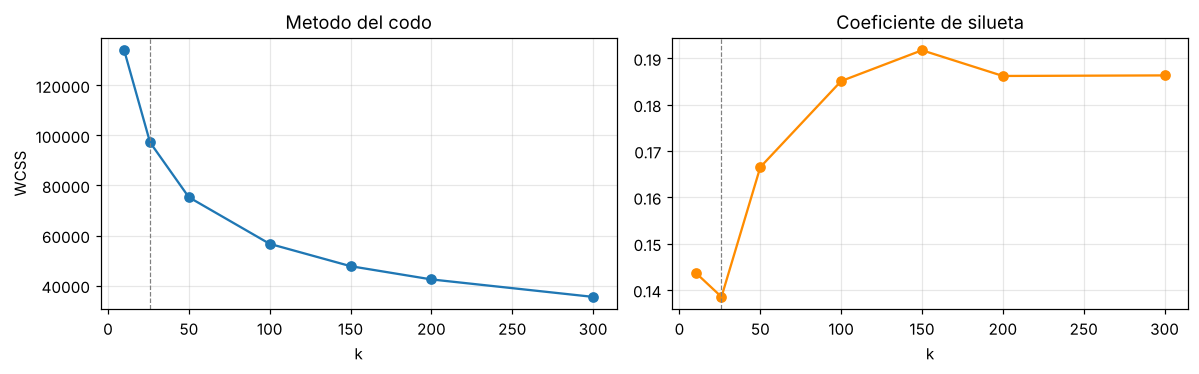

,WCSS,Silueta
k,,
10,"134,064.0513",0.1437
26,"97,246.2233",0.1385
50,"75,299.6571",0.1665
100,"56,664.2242",0.1851
150,"47,739.8740",0.1917
200,"42,442.8651",0.1862
300,"35,456.4589",0.1863


In [ ]:
rng = np.random.default_rng(0)
muestra_sil = rng.choice(N_TRAIN, 4000, replace=False)   # la silueta se calcula sobre una muestra por costo

valores_k = [10, 26, 50, 100, 150, 200, 300]
codo = []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_train)
    codo.append({'k': k, 'WCSS': km.inertia_,
                 'Silueta': silhouette_score(X_train[muestra_sil], km.labels_[muestra_sil])})
codo = pd.DataFrame(codo).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(codo.index, codo['WCSS'], marker='o')
axes[0].set_title('Metodo del codo')
axes[0].set_xlabel('k')
axes[0].set_ylabel('WCSS')
axes[1].plot(codo.index, codo['Silueta'], marker='o', color='darkorange')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('k')
for ax in axes:
    ax.axvline(26, color='gray', ls='--', lw=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
codo

La curva del codo baja de forma suave, sin un quiebre claro, y la silueta es baja para todos los valores de $k$, sin llegar nunca a 0,2. Esto indica que las letras no forman grupos naturales bien separados en este espacio: las distintas tipografías de una misma letra quedan lejos entre sí, y letras parecidas, como O y Q o H y N, se mezclan. Incluso con $k = 26$, un cluster por letra, la silueta (0,14) es más baja que con 100 o 200 clusters.

Por eso no elegimos $k$ con el codo, sino según lo que importa en esta pregunta, que es su utilidad para pseudoetiquetar. Probamos tres configuraciones:

- $k = 26$, un cluster por letra. Sería la elección natural si cada letra formara un grupo.
- $k = 100$ y $k = 200$, que corresponden a un sobreagrupamiento. Con más clusters cada uno es más pequeño y homogéneo, y tiende a contener una sola letra en una sola variante de tipografía, aunque varios clusters terminen correspondiendo a la misma letra. Esto mejora la pureza, a costa de tener menos ejemplos etiquetados por cluster para estimar su etiqueta.

### 4.2 DBSCAN

DBSCAN agrupa por densidad y usa dos parámetros: `eps`, el radio de vecindad, y `min_samples` ($n$), la cantidad mínima de puntos dentro de ese radio, contando al propio punto, para que un punto sea *core*. Los puntos que no se pueden alcanzar desde ningún *core* quedan como ruido. A diferencia de K-Means, no optimiza una función de costo.

Para elegir `eps` usamos el gráfico de distancia al $n$-ésimo vecino más cercano (*k-distance*), en el que cada punto se ordena según la distancia a su $n$-ésimo vecino.

n = 5: percentiles 25/50/75 de la distancia = [0.91 1.17 1.44]


n = 10: percentiles 25/50/75 de la distancia = [1.09 1.37 1.68]


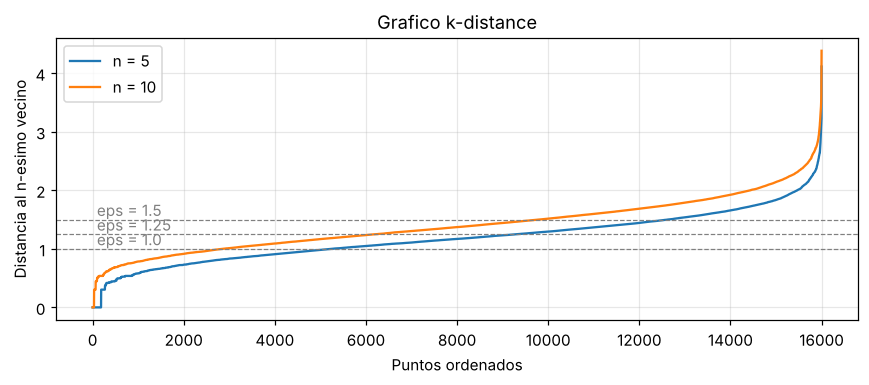

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for n_min in (5, 10):
    dist = NearestNeighbors(n_neighbors=n_min).fit(X_train).kneighbors(X_train)[0][:, -1]
    ax.plot(np.sort(dist), label=f'n = {n_min}')
    print(f'n = {n_min}: percentiles 25/50/75 de la distancia = {np.percentile(dist, [25, 50, 75]).round(2)}')
for eps in (1.0, 1.25, 1.5):
    ax.axhline(eps, color='gray', ls='--', lw=0.8)
    ax.text(0, eps, f' eps = {eps}', va='bottom', color='gray')
ax.set_xlabel('Puntos ordenados')
ax.set_ylabel('Distancia al n-esimo vecino')
ax.set_title('Grafico k-distance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La curva sube de forma gradual, sin un codo marcado, lo que muestra que la densidad cambia mucho entre regiones del espacio. Eso anticipa el problema que va a tener DBSCAN en este dataset. Con un `eps` pequeño, solo las regiones densas forman clusters y muchos puntos quedan como ruido. Con un `eps` grande, las regiones se conectan entre sí y aparece un cluster gigante que mezcla muchas letras.

Probamos tres configuraciones ubicadas alrededor de la mediana de la curva:

- `eps = 1,0` y $n = 5$: configuración conservadora, con clusters densos y puros pero mucho ruido.
- `eps = 1,25` y $n = 10$: radio intermedio, exigiendo más vecinos para ser *core*.
- `eps = 1,5` y $n = 10$: radio amplio, que conecta a la mayoría de los puntos.

In [ ]:
CONFIG_KMEANS = {'K-Means k=26': 26, 'K-Means k=100': 100, 'K-Means k=200': 200}
CONFIG_DBSCAN = {'DBSCAN eps=1.0 n=5': (1.0, 5),
                 'DBSCAN eps=1.25 n=10': (1.25, 10),
                 'DBSCAN eps=1.5 n=10': (1.5, 10)}


def ajustar_kmeans(k, semilla):
    km = KMeans(n_clusters=k, n_init=10, random_state=semilla).fit(X_train)
    clusters = km.labels_
    dist = np.linalg.norm(X_train - km.cluster_centers_[clusters], axis=1)
    # cercania: 1 para el punto mas cercano al centroide de su cluster, cercano a 0 para el mas lejano
    cercania = np.zeros(N_TRAIN)
    for c in range(k):
        m = clusters == c
        rango = dist[m].argsort().argsort()
        cercania[m] = 1 - rango / m.sum()
    return {'clusters': clusters, 'cercania': cercania, 'wcss': km.inertia_}


def ajustar_dbscan(eps, n_min):
    db = DBSCAN(eps=eps, min_samples=n_min).fit(X_train)
    clusters = db.labels_
    # cercania: 1 para puntos core, 0.5 para puntos borde, 0 para ruido
    cercania = np.where(clusters == -1, 0.0, 0.5)
    cercania[db.core_sample_indices_] = 1.0
    return {'clusters': clusters, 'cercania': cercania, 'wcss': np.nan}


def describir_clustering(nombre, info):
    c = info['clusters']
    en_cluster = c != -1
    tam = np.bincount(c[en_cluster]) if en_cluster.any() else np.array([0])
    m = muestra_sil[en_cluster[muestra_sil]]
    sil = silhouette_score(X_train[m], c[m]) if len(np.unique(c[m])) > 1 else np.nan
    return {'Configuracion': nombre, 'Clusters': int(c.max() + 1), 'Ruido (%)': 100 * (~en_cluster).mean(),
            'Cluster mas grande': int(tam.max()), 'WCSS': info['wcss'], 'Silueta': sil}


inicio = time.time()
infos_kmeans = {s: {nombre: ajustar_kmeans(k, s) for nombre, k in CONFIG_KMEANS.items()} for s in SEMILLAS}
infos_dbscan = {nombre: ajustar_dbscan(*p) for nombre, p in CONFIG_DBSCAN.items()}
print(f'Clustering listo en {time.time() - inicio:.1f} s')

desc = [describir_clustering(n, i) for n, i in infos_kmeans[SEMILLAS[0]].items()]
desc += [describir_clustering(n, i) for n, i in infos_dbscan.items()]
pd.DataFrame(desc).set_index('Configuracion')

Clustering listo en 18.8 s


,Clusters,Ruido (%),Cluster mas grande,WCSS,Silueta
Configuracion,,,,,
K-Means k=26,26,0.0000,1266,"97,246.2233",0.1385
K-Means k=100,100,0.0000,402,"56,664.2242",0.1851
K-Means k=200,200,0.0000,197,"42,442.8651",0.1862
DBSCAN eps=1.0 n=5,218,56.2813,474,NaN,0.1705
DBSCAN eps=1.25 n=10,71,44.5000,3350,NaN,0.0742
DBSCAN eps=1.5 n=10,50,22.2312,9335,NaN,-0.1705


K-Means se ajusta una vez por semilla, porque su resultado depende de la inicialización de los centroides. DBSCAN, en cambio, es determinista para un mismo conjunto de datos, así que basta con ajustarlo una vez. Ninguno de los dos usa etiquetas: el clustering se hace sobre los 16.000 datos de entrenamiento, etiquetados y no etiquetados.

La tabla confirma lo que anticipaba el gráfico *k-distance*. Con `eps = 1,0` más de la mitad de los datos (56 %) queda como ruido. Con `eps = 1,5` el ruido baja al 22 %, pero a cambio aparece un cluster de 9.335 puntos que agrupa a la mayoría de los datos, y la silueta pasa a ser negativa.

## 5. Estrategia de pseudoetiquetado

La idea es usar los pocos datos etiquetados para ponerle nombre a cada cluster y luego propagar ese nombre a los datos no etiquetados del mismo cluster, empezando por los más confiables. El procedimiento tiene cuatro pasos.

**Etiqueta de cada cluster.** Para cada cluster miramos los datos etiquetados que contiene. Su etiqueta es la letra mayoritaria, y su pureza es la fracción de esos etiquetados que tiene esa letra.

**Clusters confiables.** Un cluster solo se usa si tiene al menos 3 datos etiquetados, para que la mayoría no dependa de uno o dos ejemplos, y si su pureza es de al menos 50 %, es decir, si la letra mayoritaria representa como mínimo la mitad de los etiquetados. Los clusters que no cumplen estas condiciones, y los puntos de ruido de DBSCAN, no reciben pseudoetiquetas, porque no hay evidencia suficiente para asignarles una letra.

**Confianza de cada punto.** Cada dato no etiquetado de un cluster confiable recibe una confianza igual a la pureza del cluster multiplicada por su cercanía. En K-Means, la cercanía mide qué tan cerca está el punto del centroide, como un valor entre 0 y 1 según su posición dentro del cluster: los puntos del centro son los más representativos, y los de la periferia podrían pertenecer a otra letra. En DBSCAN, la cercanía vale 1 para los puntos *core* y 0,5 para los puntos borde, que están en el límite de la región densa.

**Selección.** Ordenamos los candidatos por confianza y asignamos pseudoetiquetas a los más confiables, hasta que etiquetados y pseudoetiquetados juntos lleguen al 60 % del entrenamiento. Si no hay suficientes candidatos confiables, se asignan todos los que hay y la cobertura queda bajo el 60 %.

Para elegir una configuración de clustering por técnica usamos la cantidad esperada de pseudoetiquetas correctas, que es la cantidad de pseudoetiquetas asignadas multiplicada por su precisión estimada. Este criterio equilibra cantidad y calidad: no gana una configuración que cubre mucho pero se equivoca seguido, ni tampoco una muy precisa que casi no asigna etiquetas.

La precisión estimada se calcula solo con etiquetas conocidas, mediante validación cruzada sobre los etiquetados. Escondemos una parte de ellos, nombramos los clusters con el resto y medimos cuántos de los escondidos reciben la letra correcta.

In [ ]:
TAU_PUREZA = 0.5
MIN_ETIQUETADOS = 3


def clusters_confiables(clusters, idx_lab, y_lab):
    tabla = pd.DataFrame({'cluster': clusters[idx_lab], 'y': y_lab})
    tabla = tabla[tabla['cluster'] != -1]
    resumen = tabla.groupby('cluster')['y'].agg(
        n='size',
        etiqueta=lambda v: v.value_counts().index[0],
        pureza=lambda v: v.value_counts(normalize=True).iloc[0])
    return resumen[(resumen['n'] >= MIN_ETIQUETADOS) & (resumen['pureza'] >= TAU_PUREZA)]


def pseudoetiquetar(info, idx_lab, y_lab, n_objetivo, excluir=None):
    clusters, cercania = info['clusters'], info['cercania']
    confiables = clusters_confiables(clusters, idx_lab, y_lab)
    disponible = np.ones(N_TRAIN, dtype=bool)
    disponible[idx_lab] = False
    if excluir is not None:
        disponible[excluir] = False
    candidatos = np.where(disponible & np.isin(clusters, confiables.index))[0]
    confianza = confiables['pureza'].reindex(clusters[candidatos]).values * cercania[candidatos]
    elegidos = candidatos[np.argsort(-confianza, kind='stable')][:n_objetivo]
    etiquetas = confiables['etiqueta'].reindex(clusters[elegidos]).values
    return elegidos, etiquetas, len(candidatos)


def estimar_precision_pseudo(info, idx_lab, y_lab, semilla):
    # Solo usa etiquetas conocidas: esconde un fold de etiquetados y mide si su cluster lo nombra bien
    clusters = info['clusters']
    aciertos, total = 0, 0
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
    for a, b in skf.split(idx_lab, y_lab):
        conf = clusters_confiables(clusters, idx_lab[a], y_lab[a])
        c_b = clusters[idx_lab[b]]
        cubiertos = np.isin(c_b, conf.index)
        aciertos += (conf['etiqueta'].reindex(c_b[cubiertos]).values == y_lab[b][cubiertos]).sum()
        total += cubiertos.sum()
    return aciertos / total if total else np.nan

## 6. Clasificadores, configuraciones de hiperparámetros y funciones de pérdida

| Modelo | Función de pérdida | Configuraciones evaluadas | Justificación |
|---|---|---|---|
| Regresión logística (multinomial) | Entropía cruzada (log-loss) más penalización L2 $\frac{1}{2C}\lVert\theta\rVert^2$ | `C = 0,01`, `C = 1`, `C = 100` | `C` es el inverso de la fuerza de regularización (clase 14). Recorremos tres órdenes de magnitud: regularización fuerte, la opción por defecto y regularización débil. |
| SVM | Hinge loss (margen suave) más penalización L2 $\frac{1}{2}\lVert\theta\rVert^2$, con el error ponderado por `C` | Lineal con `C = 1`, RBF con `C = 1`, RBF con `C = 10` | La versión lineal permite comparar con la regresión logística usando el mismo tipo de frontera. El kernel RBF (*kernel trick*, clase 13) permite fronteras no lineales, y `C` controla el equilibrio entre un margen amplio y los errores en entrenamiento. |

Para las 26 clases, la regresión logística usa la generalización multinomial (softmax) y `SVC` usa la estrategia uno contra uno. El kernel RBF usa `gamma='scale'`, que ajusta el ancho del kernel a la varianza de los datos.

Como métrica principal usamos el F1 macro, que promedia el F1 de cada letra y le da el mismo peso a las 26 clases. Lo preferimos porque el pseudoetiquetado puede desbalancear las clases del conjunto de entrenamiento, y una métrica que pondera todas las letras por igual detecta si el modelo empieza a descuidar alguna. También reportamos el accuracy como referencia; como el conjunto de prueba está balanceado, resulta muy parecido al F1 macro.

La selección de hiperparámetros tiene una dificultad que conviene dejar clara: no podemos validar contra datos sin etiqueta. Por eso, para cada combinación de clasificador y enfoque hacemos una validación cruzada de 5 folds solo sobre los datos con etiqueta real. En el enfoque supervisado esto es directo, porque cada fold entrena con 4/5 de los etiquetados y valida con el 1/5 restante. En los enfoques semisupervisados, en cada fold rehacemos el pseudoetiquetado usando solo las etiquetas reales de los 4/5 de entrenamiento, y los etiquetados del fold de validación quedan excluidos de recibir pseudoetiquetas. El modelo se entrena con etiquetados más pseudoetiquetados y se valida solo con las etiquetas reales del fold de validación.

Así ninguna decisión usa las etiquetas desconocidas ni el conjunto de prueba, y la validación mide el desempeño contra etiquetas verdaderas y no contra pseudoetiquetas que podrían estar equivocadas.

In [ ]:
CONFIG_CLASIFICADORES = {
    'Regresion logistica': {
        'C=0.01': LogisticRegression(C=0.01, max_iter=3000),
        'C=1': LogisticRegression(C=1, max_iter=3000),
        'C=100': LogisticRegression(C=100, max_iter=3000),
    },
    'SVM': {
        'lineal C=1': SVC(kernel='linear', C=1),
        'RBF C=1': SVC(kernel='rbf', C=1, gamma='scale'),
        'RBF C=10': SVC(kernel='rbf', C=10, gamma='scale'),
    },
}
ENFOQUES = ['Supervisado', 'K-Means', 'DBSCAN']


def evaluar_fold(modelo, idx_fit, y_fit, idx_val):
    m = clone(modelo).fit(X_train[idx_fit], y_fit)
    pred = m.predict(X_train[idx_val])
    return f1_score(y_train[idx_val], pred, average='macro'), accuracy_score(y_train[idx_val], pred)


def nombre_enfoque(clasificador, enfoque):
    return f'{clasificador} (supervisado)' if enfoque == 'Supervisado' else f'{clasificador} + {enfoque}'

## 7. Experimento completo

Para cada semilla y cada escenario, la celda siguiente ejecuta el experimento en cuatro pasos:

1. Selección de los datos etiquetados.
2. Evaluación de las tres configuraciones de K-Means y de DBSCAN para pseudoetiquetar, y elección de una por técnica.
3. Validación cruzada de las tres configuraciones de hiperparámetros en los seis enfoques.
4. Entrenamiento de cada enfoque con su mejor configuración sobre todos sus datos (los etiquetados, más los pseudoetiquetados en los enfoques semisupervisados) y evaluación en prueba.

Todas las configuraciones evaluadas quedan registradas. La ejecución completa toma unos tres minutos, la mayor parte por la SVM con kernel RBF.

In [ ]:
registro_clustering, registro_cv, registro_test = [], [], []
inicio_total = time.time()

for semilla in SEMILLAS:
    for esc, frac in ESCENARIOS.items():
        t0 = time.time()
        idx_lab = elegir_etiquetados(frac, semilla)
        y_lab = y_train[idx_lab]
        n_obj = int(round(OBJETIVO_COBERTURA * N_TRAIN)) - len(idx_lab)

        # 1) Configuracion de clustering para cada tecnica
        info_elegida, pseudo_final = {}, {}
        for tecnica, infos in [('K-Means', infos_kmeans[semilla]), ('DBSCAN', infos_dbscan)]:
            mejor, mejor_valor = None, -1
            for nombre, info in infos.items():
                sel, etq, n_cand = pseudoetiquetar(info, idx_lab, y_lab, n_obj)
                est = estimar_precision_pseudo(info, idx_lab, y_lab, semilla)
                esperadas = len(sel) * est
                registro_clustering.append({
                    'Semilla': semilla, 'Escenario': esc, 'Tecnica': tecnica, 'Configuracion': nombre,
                    'Candidatos': n_cand, 'Pseudoetiquetas': len(sel),
                    'Cobertura total': (len(idx_lab) + len(sel)) / N_TRAIN,
                    'Precision estimada': est, 'Correctas esperadas': esperadas,
                    'Precision real (diagnostico)': (etq == y_train[sel]).mean() if len(sel) else np.nan})
                if esperadas > mejor_valor:
                    mejor, mejor_valor = nombre, esperadas
                    info_elegida[tecnica] = info
                    pseudo_final[tecnica] = (sel, etq)
            for fila in registro_clustering[-len(infos):]:
                fila['Elegida'] = fila['Configuracion'] == mejor

        # 2) Folds de validacion cruzada (solo etiquetas reales para validar)
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
        folds = {e: [] for e in ENFOQUES}
        for a, b in skf.split(idx_lab, y_lab):
            tr, va = idx_lab[a], idx_lab[b]
            folds['Supervisado'].append((tr, y_train[tr], va))
            for tecnica in ('K-Means', 'DBSCAN'):
                sel, etq, _ = pseudoetiquetar(info_elegida[tecnica], tr, y_train[tr], n_obj, excluir=va)
                folds[tecnica].append((np.r_[tr, sel], np.r_[y_train[tr], etq], va))

        # Conjuntos finales de entrenamiento de cada enfoque
        finales = {'Supervisado': (idx_lab, y_lab)}
        for tecnica, (sel, etq) in pseudo_final.items():
            finales[tecnica] = (np.r_[idx_lab, sel], np.r_[y_lab, etq])

        # 3) Seleccion de hiperparametros y 4) evaluacion en prueba
        for clasificador, configs in CONFIG_CLASIFICADORES.items():
            for enfoque in ENFOQUES:
                resultados = {}
                for nombre_cfg, modelo in configs.items():
                    res = Parallel(n_jobs=-1)(delayed(evaluar_fold)(modelo, f, yf, v) for f, yf, v in folds[enfoque])
                    f1s, accs = np.array(res).T
                    resultados[nombre_cfg] = f1s.mean()
                    registro_cv.append({
                        'Semilla': semilla, 'Escenario': esc, 'Clasificador': clasificador, 'Enfoque': enfoque,
                        'Nombre': nombre_enfoque(clasificador, enfoque), 'Hiperparametros': nombre_cfg,
                        'F1 macro CV': f1s.mean(), 'F1 macro CV (std)': f1s.std(), 'Accuracy CV': accs.mean()})
                mejor_cfg = max(resultados, key=resultados.get)
                for fila in registro_cv[-len(configs):]:
                    fila['Elegida'] = fila['Hiperparametros'] == mejor_cfg

                idx_fit, y_fit = finales[enfoque]
                modelo = clone(configs[mejor_cfg]).fit(X_train[idx_fit], y_fit)
                pred = modelo.predict(X_test)
                registro_test.append({
                    'Semilla': semilla, 'Escenario': esc, 'Clasificador': clasificador, 'Enfoque': enfoque,
                    'Nombre': nombre_enfoque(clasificador, enfoque), 'Hiperparametros': mejor_cfg,
                    'Datos de entrenamiento': len(idx_fit),
                    'F1 macro test': f1_score(y_test, pred, average='macro'),
                    'Accuracy test': accuracy_score(y_test, pred)})
        print(f'Semilla {semilla}, escenario {esc}: {time.time() - t0:.0f} s')

df_clu = pd.DataFrame(registro_clustering)
df_cv = pd.DataFrame(registro_cv)
df_test = pd.DataFrame(registro_test)
print(f'Tiempo total: {(time.time() - inicio_total) / 60:.1f} min')

Semilla 0, escenario 10%: 22 s


Semilla 0, escenario 30%: 33 s


Semilla 1, escenario 10%: 22 s


Semilla 1, escenario 30%: 33 s


Semilla 2, escenario 10%: 21 s


Semilla 2, escenario 30%: 33 s
Tiempo total: 2.7 min


## 8. Resultados del pseudoetiquetado

La tabla resume cada configuración de clustering con el promedio de las tres semillas. La columna de precisión real usa las etiquetas ocultas, así que la mostramos solo como diagnóstico, para evaluar qué tan buena fue la estimación. No se usó para elegir nada.

In [ ]:
resumen_clu = (df_clu.groupby(['Escenario', 'Tecnica', 'Configuracion'], sort=False)
               .agg(Pseudoetiquetas=('Pseudoetiquetas', 'mean'),
                    Cobertura_total=('Cobertura total', 'mean'),
                    Precision_estimada=('Precision estimada', 'mean'),
                    Precision_real=('Precision real (diagnostico)', 'mean'),
                    Correctas_esperadas=('Correctas esperadas', 'mean'),
                    Veces_elegida=('Elegida', 'sum')))
resumen_clu

Pseudoetiquetas  Cobertura_total  \
Escenario Tecnica Configuracion                                            
10%       K-Means K-Means k=26               2,272.0000           0.2420   
                  K-Means k=100              7,281.3333           0.5551   
                  K-Means k=200              8,000.0000           0.6000   
          DBSCAN  DBSCAN eps=1.0 n=5         4,457.3333           0.3786   
                  DBSCAN eps=1.25 n=10       4,034.0000           0.3521   
                  DBSCAN eps=1.5 n=10        2,101.6667           0.2314   
30%       K-Means K-Means k=26               1,549.6667           0.3969   
                  K-Means k=100              4,800.0000           0.6000   
                  K-Means k=200              4,800.0000           0.6000   
          DBSCAN  DBSCAN eps=1.0 n=5         3,920.3333           0.5450   
                  DBSCAN eps=1.25 n=10       3,521.0000           0.5201   
                  DBSCAN eps=1.5 n=10        1,827.6667           0.4142   

                                        Precision_estimada  Precision_real  \
Escenario Tecnica Configuracion                                              
10%       K-Means K-Means k=26                      0.6318          0.6654   
                  K-Means k=100                     0.7349          0.7420   
                  K-Means k=200                     0.7410          0.7938   
          DBSCAN  DBSCAN eps=1.0 n=5                0.8191          0.8447   
                  DBSCAN eps=1.25 n=10              0.8656          0.8885   
                  DBSCAN eps=1.5 n=10               0.9839          0.9814   
30%       K-Means K-Means k=26                      0.6910          0.7099   
                  K-Means k=100                     0.7807          0.8004   
                  K-Means k=200                     0.8002          0.8809   
          DBSCAN  DBSCAN eps=1.0 n=5                0.8659          0.8784   
                  DBSCAN eps=1.25 n=10              0.8717          0.8738   
                  DBSCAN eps=1.5 n=10               0.9707          0.9732   

                                        Correctas_esperadas  Veces_elegida  
Escenario Tecnica Configuracion                                             
10%       K-Means K-Means k=26                   1,432.5179              0  
                  K-Means k=100                  5,344.7827              0  
                  K-Means k=200                  5,927.9612              3  
          DBSCAN  DBSCAN eps=1.0 n=5             3,655.4517              3  
                  DBSCAN eps=1.25 n=10           3,477.2386              0  
                  DBSCAN eps=1.5 n=10            2,067.7304              0  
30%       K-Means K-Means k=26                   1,069.8083              0  
                  K-Means k=100                  3,747.4395              0  
                  K-Means k=200                  3,840.8787              3  
          DBSCAN  DBSCAN eps=1.0 n=5             3,393.0619              3  
                  DBSCAN eps=1.25 n=10           3,069.2195              0  
                  DBSCAN eps=1.5 n=10            1,773.9849              0

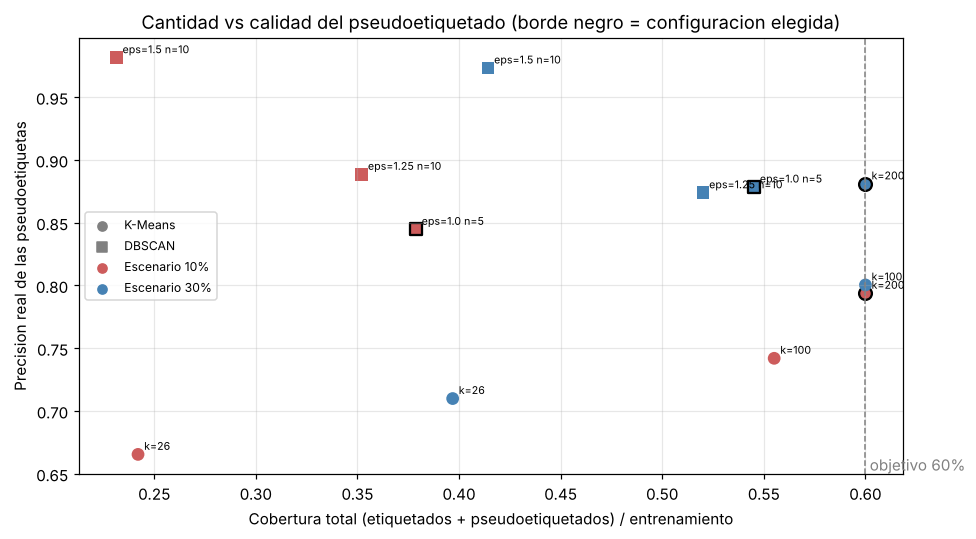

In [ ]:
marcas = {'K-Means': 'o', 'DBSCAN': 's'}
colores = {'10%': 'indianred', '30%': 'steelblue'}
fig, ax = plt.subplots(figsize=(9, 5))
for (esc, tec, conf), fila in resumen_clu.iterrows():
    ax.scatter(fila['Cobertura_total'], fila['Precision_real'], marker=marcas[tec], color=colores[esc],
               s=70, edgecolor='black' if fila['Veces_elegida'] > 0 else 'none', linewidth=1.5)
    ax.annotate(conf.replace('K-Means ', '').replace('DBSCAN ', ''),
                (fila['Cobertura_total'], fila['Precision_real']), fontsize=7,
                xytext=(4, 3), textcoords='offset points')
ax.axvline(OBJETIVO_COBERTURA, color='gray', ls='--', lw=1)
ax.text(OBJETIVO_COBERTURA, ax.get_ylim()[0], ' objetivo 60%', color='gray', va='bottom')
for tec, mk in marcas.items():
    ax.scatter([], [], marker=mk, color='gray', label=tec)
for esc, col in colores.items():
    ax.scatter([], [], marker='o', color=col, label=f'Escenario {esc}')
ax.set_xlabel('Cobertura total (etiquetados + pseudoetiquetados) / entrenamiento')
ax.set_ylabel('Precision real de las pseudoetiquetas')
ax.set_title('Cantidad vs calidad del pseudoetiquetado (borde negro = configuracion elegida)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis del pseudoetiquetado

K-Means con $k = 26$ es la peor opción. Cubre solo el 24 % del entrenamiento en el escenario del 10 % y el 40 % en el del 30 %, con una precisión de entre 67 % y 71 %. Como cada cluster mezcla varias letras, pocos superan el filtro de pureza, y los que lo superan siguen estando bastante mezclados.

El sobreagrupamiento mejora la cantidad y la calidad al mismo tiempo. Con $k = 200$ se alcanza el 60 % en ambos escenarios, con una precisión de 79 % en el escenario del 10 % y de 88 % en el del 30 %. Fue la configuración elegida en las tres semillas de ambos escenarios.

DBSCAN, en cambio, no logra el 60 % en ningún caso. Su mejor configuración, `eps = 1,0`, llega al 38 % en el escenario del 10 % y al 55 % en el del 30 %. Esta es la limitación que impide cumplir el objetivo, y se explica por cómo funciona el algoritmo con este dataset. Con un `eps` pequeño, más de la mitad de los puntos queda como ruido, y como el ruido no pertenece a ningún cluster, no hay una forma justificada de asignarle una letra. Con un `eps` grande, las regiones se conectan y aparece un cluster gigante, de más de 9.000 puntos con `eps = 1,5`, que mezcla casi todas las letras. Su pureza no llega al 50 %, así que queda fuera, y la cobertura baja en vez de subir (23 % y 41 %), aunque las pocas pseudoetiquetas que quedan son casi perfectas, con una precisión de 97 % a 98 %.

El problema de fondo es que DBSCAN usa un único umbral de densidad para todo el espacio, y la densidad de estos datos varía mucho entre regiones, como mostró el gráfico *k-distance*. Para llegar al 60 % habría que aceptar el cluster gigante o los puntos de ruido, lo que significaría asignar miles de etiquetas con una alta probabilidad de error. Decidimos priorizar la calidad sobre la cantidad.

La precisión estimada solo con etiquetas conocidas se parece mucho a la real, así que el criterio de elección es confiable sin necesidad de mirar las etiquetas ocultas. En K-Means con $k = 200$ la estimación resulta algo pesimista (74 % frente a 79 % en el escenario del 10 %), porque los puntos elegidos son los de mayor confianza, y esos aciertan más que el promedio de su cluster.

Por último, más etiquetas reales producen mejores pseudoetiquetas. Con $k = 200$, la precisión sube de 79 % a 88 % al pasar del 10 % al 30 % de etiquetados. Hay dos razones: cada cluster tiene más etiquetados para nombrarlo bien, y como se necesitan menos pseudoetiquetas (4.800 en vez de 8.000), solo se usan las más confiables.

## 9. Selección de hiperparámetros: todas las configuraciones evaluadas

La tabla completa (`df_cv`) guarda cada configuración de cada semilla y escenario. Aquí mostramos el promedio de las tres semillas y cuántas veces fue elegida cada configuración.

In [ ]:
resumen_cv = (df_cv.groupby(['Escenario', 'Nombre', 'Hiperparametros'], sort=False)
              .agg(F1_CV=('F1 macro CV', 'mean'), F1_CV_std_folds=('F1 macro CV (std)', 'mean'),
                   Accuracy_CV=('Accuracy CV', 'mean'), Veces_elegida=('Elegida', 'sum')))
resumen_cv

F1_CV  \
Escenario Nombre                            Hiperparametros          
10%       Regresion logistica (supervisado) C=0.01          0.5489   
                                            C=1             0.7345   
                                            C=100           0.7294   
          Regresion logistica + K-Means     C=0.01          0.5885   
                                            C=1             0.6563   
                                            C=100           0.6586   
          Regresion logistica + DBSCAN      C=0.01          0.5082   
                                            C=1             0.6585   
                                            C=100           0.6788   
          SVM (supervisado)                 lineal C=1      0.7949   
                                            RBF C=1         0.7944   
                                            RBF C=10        0.8582   
          SVM + K-Means                     lineal C=1      0.6782   
                                            RBF C=1         0.6621   
                                            RBF C=10        0.7089   
          SVM + DBSCAN                      lineal C=1      0.7258   
                                            RBF C=1         0.7272   
                                            RBF C=10        0.7873   
30%       Regresion logistica (supervisado) C=0.01          0.6483   
                                            C=1             0.7517   
                                            C=100           0.7563   
          Regresion logistica + K-Means     C=0.01          0.6287   
                                            C=1             0.7336   
                                            C=100           0.7369   
          Regresion logistica + DBSCAN      C=0.01          0.6131   
                                            C=1             0.7216   
                                            C=100           0.7307   
          SVM (supervisado)                 lineal C=1      0.8303   
                                            RBF C=1         0.8792   
                                            RBF C=10        0.9300   
          SVM + K-Means                     lineal C=1      0.7950   
                                            RBF C=1         0.8186   
                                            RBF C=10        0.8665   
          SVM + DBSCAN                      lineal C=1      0.7836   
                                            RBF C=1         0.8239   
                                            RBF C=10        0.8780   

                                                             F1_CV_std_folds  \
Escenario Nombre                            Hiperparametros                    
10%       Regresion logistica (supervisado) C=0.01                    0.0219   
                                            C=1                       0.0218   
                                            C=100                     0.0209   
          Regresion logistica + K-Means     C=0.01                    0.0289   
                                            C=1                       0.0262   
                                            C=100                     0.0223   
          Regresion logistica + DBSCAN      C=0.01                    0.0207   
                                            C=1                       0.0193   
                                            C=100                     0.0233   
          SVM (supervisado)                 lineal C=1                0.0252   
                                            RBF C=1                   0.0145   
                                            RBF C=10                  0.0156   
          SVM + K-Means                     lineal C=1                0.0164   
                                            RBF C=1                   0.0227   
                                            RBF C=10                  0.0238   
          SVM + DBSCAN                  

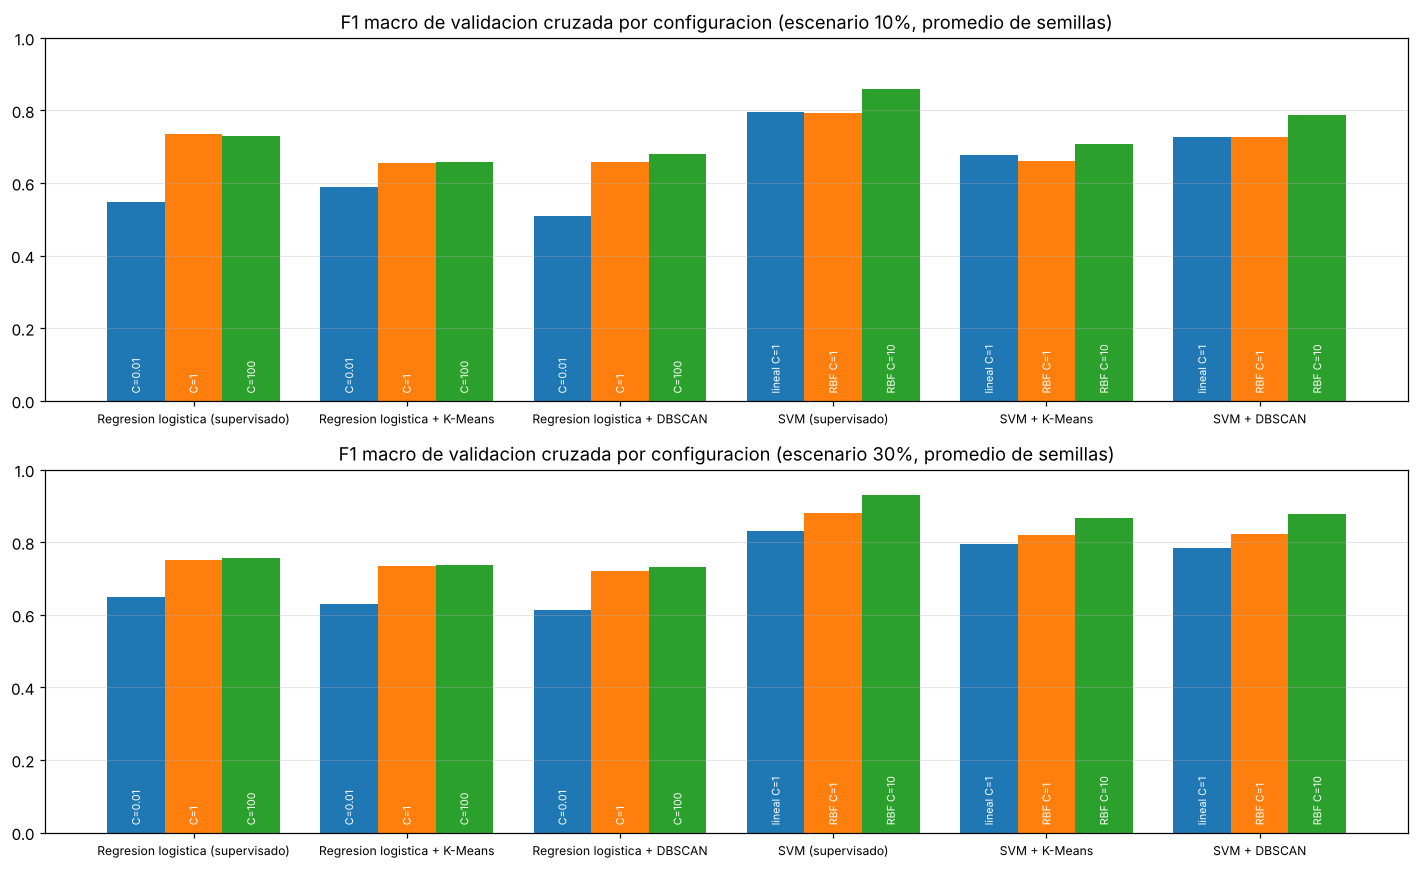

In [ ]:
nombres = df_cv['Nombre'].unique()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharey=True)
for ax, esc in zip(axes, ESCENARIOS):
    sub = resumen_cv.loc[esc].reset_index()
    ancho = 0.27
    for j, pos in enumerate(range(3)):
        vals, etiquetas = [], []
        for n in nombres:
            filas_n = sub[sub['Nombre'] == n].iloc[pos]
            vals.append(filas_n['F1_CV'])
            etiquetas.append(filas_n['Hiperparametros'])
        barras = ax.bar(np.arange(len(nombres)) + (j - 1) * ancho, vals, ancho)
        for b, et in zip(barras, etiquetas):
            ax.text(b.get_x() + b.get_width() / 2, 0.02, et, rotation=90, ha='center', va='bottom',
                    fontsize=7, color='white')
    ax.set_xticks(np.arange(len(nombres)), nombres, fontsize=8)
    ax.set_title(f'F1 macro de validacion cruzada por configuracion (escenario {esc}, promedio de semillas)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de los hiperparámetros

En la regresión logística, `C = 0,01` es claramente la peor configuración en todos los enfoques. En el escenario supervisado del 10 %, por ejemplo, obtiene un F1 de 0,55 frente a 0,73 con `C = 1`. Una regularización tan fuerte encoge demasiado los coeficientes y el modelo cae en underfitting. Entre `C = 1` y `C = 100`, en cambio, las diferencias son mínimas y quedan dentro de la variación entre folds (alrededor de 0,01 a 0,02), por lo que la elección entre ambas cambia según la semilla. Con 16 variables y miles de ejemplos la regularización casi no influye: el límite de este modelo es su frontera de decisión lineal, no el sobreajuste.

En la SVM, la configuración RBF con `C = 10` fue la mejor en las 18 combinaciones de semilla, escenario y enfoque. El kernel RBF permite fronteras no lineales, que son necesarias para separar letras parecidas, y un `C` mayor reduce la regularización para ajustarlas mejor. Con este tamaño de datos eso no produce overfitting. La SVM lineal obtiene resultados parecidos a la RBF con `C = 1` en el escenario del 10 %, pero supera a la regresión logística, que también es lineal. Una explicación posible es que `SVC` entrena un clasificador por cada par de letras, 325 en total, y en conjunto forman una frontera más flexible que un único modelo multinomial.

El orden de las configuraciones se mantiene con pseudoetiquetas: RBF con `C = 10` sigue siendo la mejor en los enfoques semisupervisados. Lo que cambia es el nivel. Con las configuraciones elegidas, el F1 de validación cruzada de los enfoques semisupervisados es siempre menor que el del supervisado. La única excepción es la regresión logística con `C = 0,01` en el escenario del 10 %, donde los datos adicionales compensan en parte el exceso de regularización, aunque esa configuración nunca es competitiva. Es decir, la validación cruzada, usando solo etiquetas reales, ya anticipaba que las pseudoetiquetas iban a empeorar el desempeño, y eso se confirmó después en el conjunto de prueba.

La decisión que más pesa no es un hiperparámetro dentro de un modelo, sino el tipo de modelo. Pasar de regresión logística a SVM con RBF mejora el F1 en más de 0,12 puntos, una diferencia mayor que la de cualquier otra decisión del experimento.

## 10. Comparación final de los seis enfoques en prueba

Cada enfoque se entrena con la mejor configuración de hiperparámetros que eligió la validación cruzada en cada semilla, y se evalúa en el conjunto de prueba. Reportamos el promedio y la desviación estándar de las tres semillas. Después comparamos cada enfoque semisupervisado con su versión supervisada, semilla por semilla, y relacionamos esa diferencia con la precisión real de las pseudoetiquetas.

In [ ]:
resumen_test = (df_test.groupby(['Escenario', 'Nombre'], sort=False)
                .agg(F1_test=('F1 macro test', 'mean'), F1_test_std=('F1 macro test', 'std'),
                     Accuracy_test=('Accuracy test', 'mean'),
                     Datos_entrenamiento=('Datos de entrenamiento', 'mean'),
                     Hiperparametros=('Hiperparametros', lambda v: ', '.join(sorted(set(v))))))
resumen_test

F1_test  F1_test_std  \
Escenario Nombre                                                    
10%       Regresion logistica (supervisado)   0.7407       0.0062   
          Regresion logistica + K-Means       0.6708       0.0070   
          Regresion logistica + DBSCAN        0.7000       0.0162   
          SVM (supervisado)                   0.8745       0.0077   
          SVM + K-Means                       0.7388       0.0088   
          SVM + DBSCAN                        0.8136       0.0150   
30%       Regresion logistica (supervisado)   0.7603       0.0071   
          Regresion logistica + K-Means       0.7544       0.0045   
          Regresion logistica + DBSCAN        0.7413       0.0100   
          SVM (supervisado)                   0.9395       0.0025   
          SVM + K-Means                       0.8940       0.0042   
          SVM + DBSCAN                        0.8923       0.0110   

                                             Accuracy_test  \
Escenario Nombre                                             
10%       Regresion logistica (supervisado)         0.7422   
          Regresion logistica + K-Means             0.6722   
          Regresion logistica + DBSCAN              0.7017   
          SVM (supervisado)                         0.8747   
          SVM + K-Means                             0.7401   
          SVM + DBSCAN                              0.8146   
30%       Regresion logistica (supervisado)         0.7623   
          Regresion logistica + K-Means             0.7565   
          Regresion logistica + DBSCAN              0.7428   
          SVM (supervisado)                         0.9397   
          SVM + K-Means                             0.8943   
          SVM + DBSCAN                              0.8927   

                                             Datos_entrenamiento  \
Escenario Nombre                                                   
10%       Regresion logistica (supervisado)           1,600.0000   
          Regresion logistica + K-Means               9,600.0000   
          Regresion logistica + DBSCAN                6,057.3333   
          SVM (supervisado)                           1,600.0000   
          SVM + K-Means                               9,600.0000   
          SVM + DBSCAN                                6,057.3333   
30%       Regresion logistica (supervisado)           4,800.0000   
          Regresion logistica + K-Means               9,600.0000   
          Regresion logistica + DBSCAN                8,720.3333   
          SVM (supervisado)                           4,800.0000   
          SVM + K-Means                               9,600.0000   
          SVM + DBSCAN                                8,720.3333   

                                            Hiperparametros  
Escenario Nombre                                             
10%       Regresion logistica (supervisado)             C=1  
          Regresion logistica + K-Means          C=1, C=100  
          Regresion logistica + DBSCAN                C=100  
          SVM (supervisado)                        RBF C=10  
          SVM + K-Means                            RBF C=10  
          SVM + DBSCAN                             RBF C=10  
30%       Regresion logistica (supervisado)           C=100  
          Regresion logistica + K-Means               C=100  
          Regresion logistica + DBSCAN                C=100  
          SVM (supervisado)                        RBF C=10  
          SVM + K-Means                            RBF C=10  
          SVM + DBSCAN                             RBF C=10

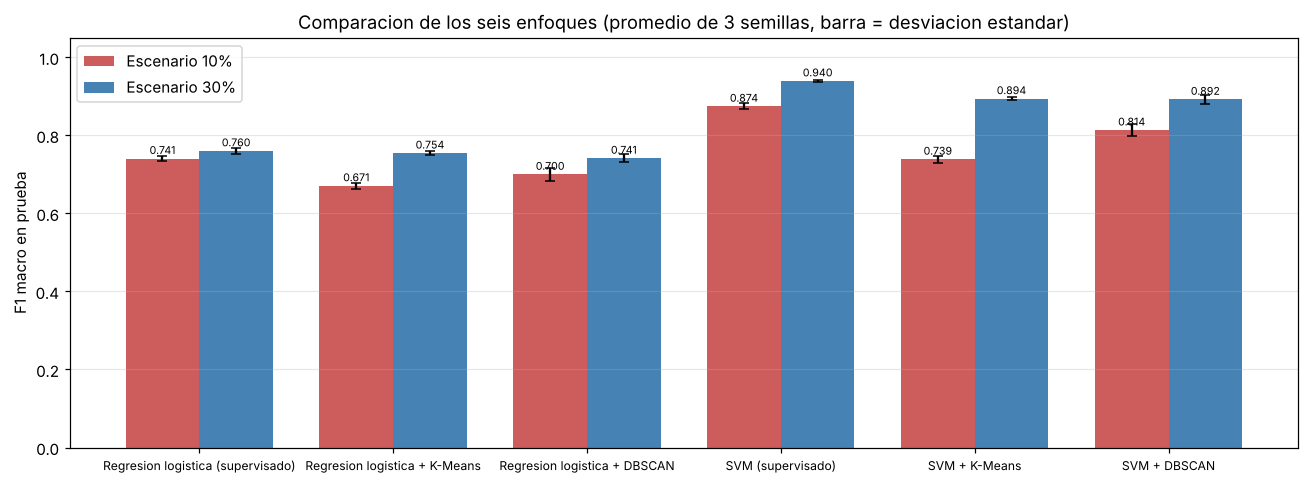

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ancho = 0.38
for j, esc in enumerate(ESCENARIOS):
    sub = resumen_test.loc[esc]
    barras = ax.bar(np.arange(len(sub)) + (j - 0.5) * ancho, sub['F1_test'], ancho,
                    yerr=sub['F1_test_std'], capsize=3, label=f'Escenario {esc}', color=colores[esc])
    for b, v in zip(barras, sub['F1_test']):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f'{v:.3f}', ha='center', fontsize=7)
ax.set_xticks(np.arange(len(sub)), sub.index, fontsize=8)
ax.set_ylabel('F1 macro en prueba')
ax.set_ylim(0, 1.05)
ax.set_title('Comparacion de los seis enfoques (promedio de 3 semillas, barra = desviacion estandar)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Diferencia de cada enfoque semisupervisado respecto de su version supervisada, por semilla
base = df_test[df_test['Enfoque'] == 'Supervisado'].set_index(['Semilla', 'Escenario', 'Clasificador'])['F1 macro test']
semi = df_test[df_test['Enfoque'] != 'Supervisado'].copy()
semi['Diferencia vs supervisado'] = semi['F1 macro test'].values - base.loc[
    list(zip(semi['Semilla'], semi['Escenario'], semi['Clasificador']))].values
calidad = df_clu[df_clu['Elegida']][['Semilla', 'Escenario', 'Tecnica', 'Precision real (diagnostico)', 'Cobertura total']]
semi = semi.merge(calidad, left_on=['Semilla', 'Escenario', 'Enfoque'], right_on=['Semilla', 'Escenario', 'Tecnica'])

tabla_dif = (semi.groupby(['Escenario', 'Nombre'], sort=False)
             .agg(Diferencia_media=('Diferencia vs supervisado', 'mean'),
                  Diferencia_min=('Diferencia vs supervisado', 'min'),
                  Diferencia_max=('Diferencia vs supervisado', 'max'),
                  Precision_pseudo=('Precision real (diagnostico)', 'mean'),
                  Cobertura=('Cobertura total', 'mean')))
tabla_dif

Diferencia_media  Diferencia_min  \
Escenario Nombre                                                            
10%       Regresion logistica + K-Means           -0.0699         -0.0780   
          Regresion logistica + DBSCAN            -0.0406         -0.0520   
          SVM + K-Means                           -0.1357         -0.1402   
          SVM + DBSCAN                            -0.0609         -0.0725   
30%       Regresion logistica + K-Means           -0.0059         -0.0085   
          Regresion logistica + DBSCAN            -0.0190         -0.0230   
          SVM + K-Means                           -0.0455         -0.0483   
          SVM + DBSCAN                            -0.0472         -0.0627   

                                         Diferencia_max  Precision_pseudo  \
Escenario Nombre                                                            
10%       Regresion logistica + K-Means         -0.0570            0.7938   
          Regresion logistica + DBSCAN          -0.0293            0.8447   
          SVM + K-Means                         -0.1312            0.7938   
          SVM + DBSCAN                          -0.0482            0.8447   
30%       Regresion logistica + K-Means         -0.0012            0.8809   
          Regresion logistica + DBSCAN          -0.0162            0.8784   
          SVM + K-Means                         -0.0436            0.8809   
          SVM + DBSCAN                          -0.0394            0.8784   

                                         Cobertura  
Escenario Nombre                                    
10%       Regresion logistica + K-Means     0.6000  
          Regresion logistica + DBSCAN      0.3786  
          SVM + K-Means                     0.6000  
          SVM + DBSCAN                      0.3786  
30%       Regresion logistica + K-Means     0.6000  
          Regresion logistica + DBSCAN      0.5450  
          SVM + K-Means                     0.6000  
          SVM + DBSCAN                      0.5450

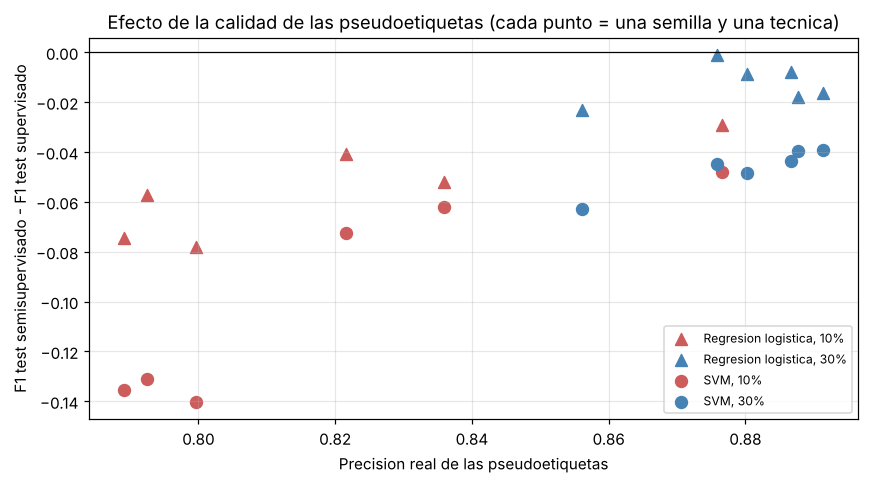

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (clf, esc), sub in semi.groupby(['Clasificador', 'Escenario']):
    ax.scatter(sub['Precision real (diagnostico)'], sub['Diferencia vs supervisado'],
               marker='o' if clf == 'SVM' else '^', color=colores[esc], s=60, label=f'{clf}, {esc}')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Precision real de las pseudoetiquetas')
ax.set_ylabel('F1 test semisupervisado - F1 test supervisado')
ax.set_title('Efecto de la calidad de las pseudoetiquetas (cada punto = una semilla y una tecnica)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Análisis de sensibilidad: cantidad frente a calidad de las pseudoetiquetas

Los resultados anteriores muestran que el pseudoetiquetado empeoró el desempeño, pero no explican en qué momento empieza a hacerlo. Para eso repetimos la validación cruzada variando cuántas pseudoetiquetas se agregan (0, 1.000, 2.000, 4.000 y 8.000), siempre tomando primero las de mayor confianza. Usamos la semilla 0, las configuraciones de clustering elegidas y un hiperparámetro fijo por clasificador: `C = 1` en la regresión logística y RBF con `C = 10` en la SVM. Cero pseudoetiquetas equivale al enfoque supervisado.

Igual que antes, el desempeño se mide solo con las etiquetas reales de los folds de validación, y la precisión real de las pseudoetiquetas se muestra solo como diagnóstico.

In [ ]:
CANTIDADES = [0, 1000, 2000, 4000, 8000]
MODELOS_SENS = {'Regresion logistica': LogisticRegression(C=1, max_iter=3000),
                'SVM': SVC(kernel='rbf', C=10, gamma='scale')}
semilla = SEMILLAS[0]
registro_sens = []
inicio = time.time()

for esc, frac in ESCENARIOS.items():
    idx_lab = elegir_etiquetados(frac, semilla)
    y_lab = y_train[idx_lab]
    particiones = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla).split(idx_lab, y_lab))
    for tecnica in ('K-Means', 'DBSCAN'):
        conf = df_clu[(df_clu['Semilla'] == semilla) & (df_clu['Escenario'] == esc)
                      & (df_clu['Tecnica'] == tecnica) & df_clu['Elegida']]['Configuracion'].iloc[0]
        info = infos_kmeans[semilla][conf] if tecnica == 'K-Means' else infos_dbscan[conf]
        for n_ps in CANTIDADES:
            folds_n, n_reales, precisiones = [], [], []
            for a, b in particiones:
                tr, va = idx_lab[a], idx_lab[b]
                sel, etq, _ = pseudoetiquetar(info, tr, y_train[tr], n_ps, excluir=va)
                folds_n.append((np.r_[tr, sel], np.r_[y_train[tr], etq], va))
                n_reales.append(len(sel))
                if len(sel):
                    precisiones.append((etq == y_train[sel]).mean())
            for clasificador, modelo in MODELOS_SENS.items():
                res = Parallel(n_jobs=-1)(delayed(evaluar_fold)(modelo, f, yf, v) for f, yf, v in folds_n)
                registro_sens.append({
                    'Escenario': esc, 'Tecnica': tecnica, 'Configuracion': conf, 'Clasificador': clasificador,
                    'Pedidas': n_ps, 'Pseudoetiquetas': np.mean(n_reales),
                    'Precision real pseudo': np.mean(precisiones) if precisiones else np.nan,
                    'F1 macro CV': np.mean([r[0] for r in res])})

df_sens = pd.DataFrame(registro_sens)
print(f'Analisis de sensibilidad listo en {time.time() - inicio:.0f} s')
tabla_sens = df_sens.pivot_table(index=['Escenario', 'Tecnica', 'Pedidas'], columns='Clasificador',
                                 values='F1 macro CV')
tabla_sens.columns = [f'F1 CV {c}' for c in tabla_sens.columns]
tabla_sens.join(df_sens.groupby(['Escenario', 'Tecnica', 'Pedidas'])[['Pseudoetiquetas', 'Precision real pseudo']].first())

Analisis de sensibilidad listo en 47 s


F1 CV Regresion logistica  F1 CV SVM  \
Escenario Tecnica Pedidas                                         
10%       DBSCAN  0                           0.7460     0.8626   
                  1000                        0.7394     0.8689   
                  2000                        0.7365     0.8694   
                  4000                        0.6741     0.8020   
                  8000                        0.6741     0.8020   
          K-Means 0                           0.7460     0.8626   
                  1000                        0.7434     0.8699   
                  2000                        0.7299     0.8369   
                  4000                        0.6979     0.7881   
                  8000                        0.6639     0.7312   
30%       DBSCAN  0                           0.7595     0.9291   
                  1000                        0.7611     0.9281   
                  2000                        0.7607     0.9281   
                  4000                        0.7311     0.8763   
                  8000                        0.7317     0.8763   
          K-Means 0                           0.7595     0.9291   
                  1000                        0.7652     0.9278   
                  2000                        0.7593     0.9212   
                  4000                        0.7448     0.8785   
                  8000                        0.7174     0.8118   

                           Pseudoetiquetas  Precision real pseudo  
Escenario Tecnica Pedidas                                          
10%       DBSCAN  0                 0.0000                    NaN  
                  1000          1,000.0000                 1.0000  
                  2000          2,000.0000                 1.0000  
                  4000          3,938.6000                 0.8650  
                  8000          3,938.6000                 0.8650  
          K-Means 0                 0.0000                    NaN  
                  1000          1,000.0000                 0.9942  
                  2000          2,000.0000                 0.9658  
                  4000          4,000.0000                 0.8871  
                  8000          8,000.0000                 0.7870  
30%       DBSCAN  0                 0.0000                    NaN  
                  1000          1,000.0000                 1.0000  
                  2000          2,000.0000                 1.0000  
                  4000          3,769.6000                 0.8803  
                  8000          3,779.8000                 0.8796  
          K-Means 0                 0.0000                    NaN  
                  1000          1,000.0000                 0.9980  
                  2000          2,000.0000                 0.9822  
                  4000          4,000.0000                 0.9041  
                  8000          7,529.4000                 0.8108

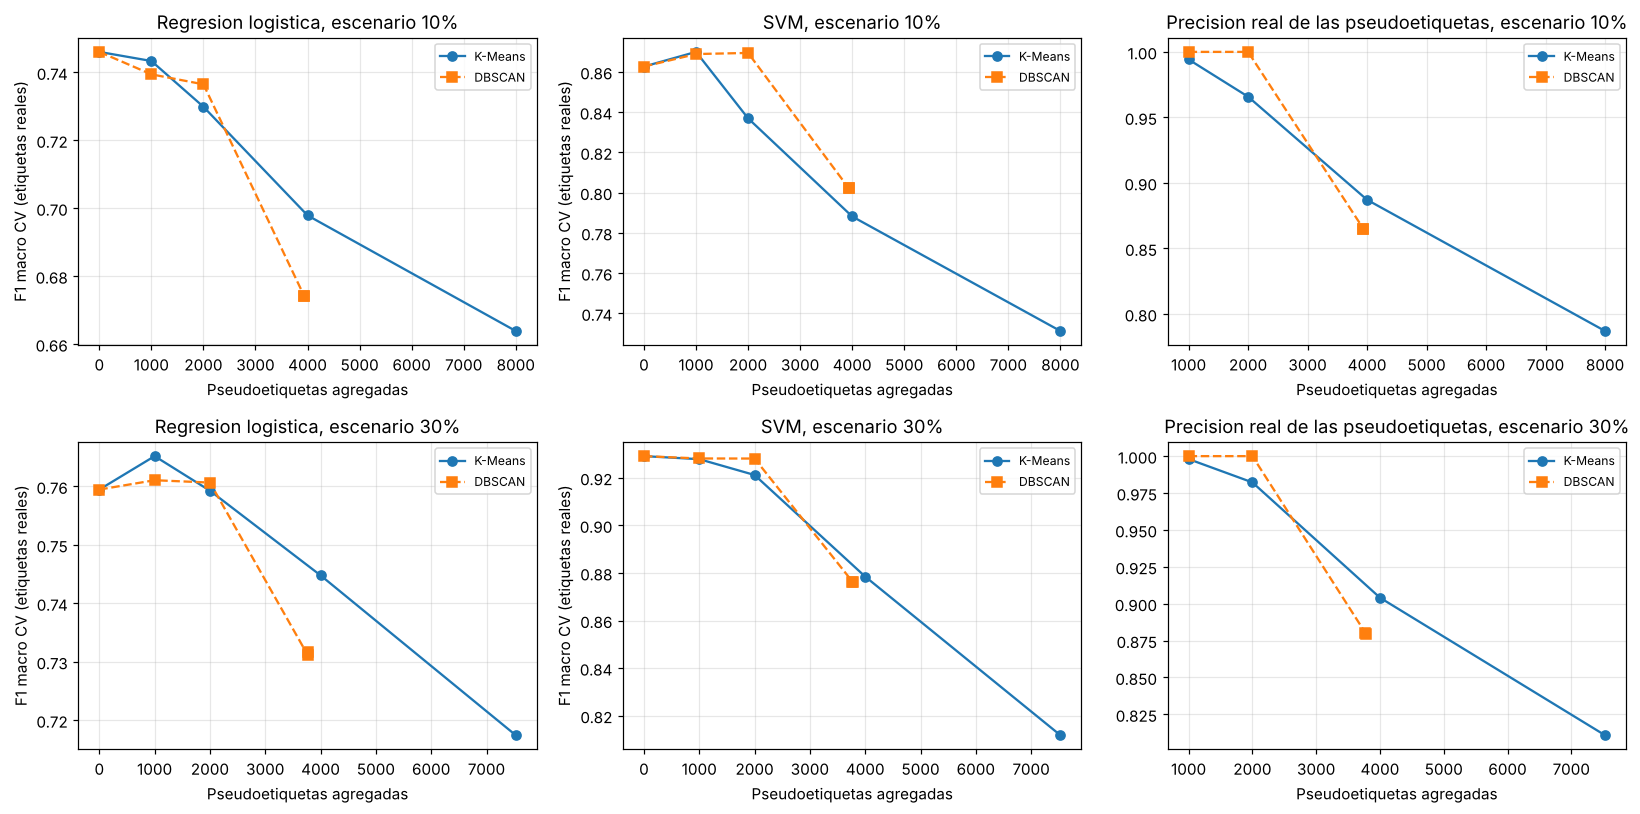

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
estilos = {'K-Means': ('o', '-'), 'DBSCAN': ('s', '--')}
for fila, esc in zip(axes, ESCENARIOS):
    for tecnica, (mk, ls) in estilos.items():
        sub = df_sens[(df_sens['Escenario'] == esc) & (df_sens['Tecnica'] == tecnica)]
        for ax, clasificador in zip(fila[:2], MODELOS_SENS):
            s = sub[sub['Clasificador'] == clasificador]
            ax.plot(s['Pseudoetiquetas'], s['F1 macro CV'], marker=mk, ls=ls, label=tecnica)
            ax.set_title(f'{clasificador}, escenario {esc}')
            ax.set_ylabel('F1 macro CV (etiquetas reales)')
        s = sub[(sub['Clasificador'] == 'SVM') & (sub['Pedidas'] > 0)]
        fila[2].plot(s['Pseudoetiquetas'], s['Precision real pseudo'], marker=mk, ls=ls, label=tecnica)
        fila[2].set_title(f'Precision real de las pseudoetiquetas, escenario {esc}')
    for ax in fila:
        ax.set_xlabel('Pseudoetiquetas agregadas')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Análisis de sensibilidad

Este experimento explica por qué el pseudoetiquetado no ayudó.

Las primeras pseudoetiquetas son casi perfectas, pero aportan poco. Las primeras 1.000 tienen una precisión de entre 99 % y 100 % y cambian el F1 en menos de 0,01, a veces hacia arriba y a veces hacia abajo. Son los puntos más cercanos al centro de clusters puros, es decir, ejemplos fáciles que el clasificador ya sabía clasificar con los datos etiquetados, así que no le entregan información nueva. Con DBSCAN la precisión se mantiene en 100 % hasta las 2.000 pseudoetiquetas y el F1 tampoco cambia.

Incluso pocos errores afectan a la SVM. Con K-Means, al llegar a 2.000 pseudoetiquetas la precisión baja a entre 96 % y 98 %, y el F1 de la SVM ya cae 0,026 puntos en el escenario del 10 %.

Al seguir agregando, la calidad cae de forma brusca. Para acercarse al 60 % hay que usar puntos de la periferia de los clusters en K-Means, o puntos borde en DBSCAN. En DBSCAN con 10 % de etiquetados, las primeras 2.000 pseudoetiquetas tienen 100 % de precisión, pero las aproximadamente 1.900 siguientes tienen solo alrededor de 73 %, lo que baja la precisión total a 86,5 %. Justo en ese tramo el F1 cae entre 0,03 y 0,07 puntos.

Además, los errores de las pseudoetiquetas no son ruido aleatorio, sino sistemáticos. Cuando un cluster mezcla dos letras parecidas, todos sus puntos mal etiquetados reciben la misma letra equivocada, y además se ubican cerca de la frontera entre ambas clases. Eso desplaza la frontera del clasificador justo donde más cuesta decidir.

La SVM es la más perjudicada, porque con sus fronteras flexibles se ajusta también a las pseudoetiquetas incorrectas. La regresión logística, más rígida, se ve menos afectada: con 8.000 pseudoetiquetas de K-Means pierde 0,08 puntos de F1 en el escenario del 10 %, mientras que la SVM pierde 0,13.

En resumen, el objetivo del 60 % obliga a incluir pseudoetiquetas de baja calidad. Hay un compromiso directo entre cantidad y calidad, y con este dataset la calidad pesa más.

## 12. Conclusiones

**El mejor enfoque es la SVM supervisada en ambos escenarios.** Obtiene un F1 macro de 0,875 con el 10 % de etiquetas y de 0,940 con el 30 %. Ningún enfoque semisupervisado superó a su versión supervisada en ninguna semilla, y como las desviaciones estándar entre semillas son pequeñas (menores a 0,02), la conclusión no depende de la semilla.

**Calidad de las pseudoetiquetas.** El pseudoetiquetado solo puede ayudar si las etiquetas que agrega son más confiables que lo que el clasificador ya predice por sí mismo. En el escenario del 10 %, la SVM supervisada se equivoca en cerca del 12 % de los casos, mientras que las pseudoetiquetas se equivocan en un 21 % con K-Means y en un 16 % con DBSCAN. Agregarlas equivale a entrenar con datos peores que el propio modelo, y por eso la SVM con K-Means pierde 0,136 puntos de F1. La regresión logística se equivoca cerca del 26 %, así que para ella las pseudoetiquetas sí son algo más precisas que el modelo, pero igual la perjudican porque sus errores son sistemáticos (sección 11). Entre técnicas, DBSCAN asignó menos pseudoetiquetas pero de mejor calidad, y por eso perdió menos que K-Means en el escenario del 10 % con ambos clasificadores.

**Cantidad de etiquetas reales.** Pasar del 10 % al 30 % de etiquetas reales mejora todo a la vez: el F1 de la SVM supervisada sube de 0,875 a 0,940, la precisión de las pseudoetiquetas de K-Means sube de 79 % a 88 % y se necesitan menos pseudoetiquetas. Por eso la pérdida de los enfoques semisupervisados se reduce mucho, y en el escenario del 30 % la regresión logística con K-Means queda prácticamente empatada con su versión supervisada, con una diferencia de 0,006. Aquí aparece una paradoja: el aprendizaje semisupervisado haría más falta cuando hay pocas etiquetas, pero es justo en ese caso cuando las pseudoetiquetas son peores.

**Hiperparámetros.** La elección del modelo y de sus hiperparámetros influye más que el uso de pseudoetiquetas. La SVM con kernel RBF supera ampliamente a la regresión logística en todos los casos, al punto de que la SVM con DBSCAN, aun perjudicada por las pseudoetiquetas, obtiene 0,814 en el escenario del 10 % y supera a la regresión logística supervisada, que obtiene 0,741. En la regresión logística, solo una regularización excesiva (`C = 0,01`) empeora claramente el resultado.

**Por qué falla el supuesto semisupervisado.** El pseudoetiquetado con clustering supone que los puntos de un mismo grupo comparten la misma clase. En este dataset ese supuesto se cumple solo en parte: la silueta es baja (menor a 0,2), K-Means con un cluster por letra tiene una pureza muy baja y DBSCAN no encuentra regiones densas que separen las letras. Las 26 letras no forman grupos naturales en el espacio de las 16 características, porque cada una aparece en 20 tipografías distintas y varias se parecen entre sí. La conclusión no es que el aprendizaje semisupervisado no sirva, sino que depende de que la estructura de los clusters coincida con la de las clases, y aquí no coincide.

**La validación cruzada fue un buen criterio.** Sin usar el conjunto de prueba ni las etiquetas desconocidas, la validación cruzada mostró que los enfoques semisupervisados rendían menos, y el conjunto de prueba lo confirmó. En una aplicación real, este procedimiento nos habría llevado a elegir el modelo supervisado.

**Posibles mejoras.** Hay algunas alternativas que podrían hacer que el pseudoetiquetado sí aporte. Una es darle menos peso a las pseudoetiquetas durante el entrenamiento. Otra es aceptar una cobertura menor al 60 % y quedarse solo con las pseudoetiquetas de alta confianza, que según el análisis de sensibilidad son las que no dañan al modelo. Una tercera es combinar el cluster con la predicción del propio clasificador y aceptar una pseudoetiqueta solo cuando ambos coinciden, en la línea del *self-training*.

# Tarea 2, Pregunta 3: Identificación no supervisada de estados meteorológicos y detección de anomalías

En esta pregunta abordamos la identificación de estados meteorológicos y la detección de eventos climáticos extremos en la zona de Santiago, trabajando en un escenario puramente no supervisado: no contamos con etiquetas ni con confirmaciones visuales de la tormenta eléctrica en la zona. El desafío consiste en descubrir la **firma matemática de la tormenta** a partir de la sola estructura de los datos.

Para eso usamos un dataset meteorológico de la API de **Open-Meteo** (Historical Weather API), con observaciones horarias de Santiago entre el 2024-10-15 y el 2026-10-15. El dataset reúne 17.544 registros y 12 variables atmosféricas (temperatura, humedad, presión, viento, precipitación, etc.). Como el ejercicio es no supervisado, descartamos cualquier variable objetivo o etiqueta.

El objetivo se desglosa en cinco tareas:

1. Reducir la dimensionalidad con una técnica espacial, justificando estadísticamente la información retenida.
2. Aplicar dos enfoques de agrupamiento: uno por partición (con centroide más cercano) y otro por densidad, aislando las zonas dispersas.
3. Evaluar la calidad geométrica de los agrupamientos con métricas de validación interna.
4. Analizar cómo la normalización y la métrica de distancia determinan la forma de los clústeres y la sensibilidad a la detección de anomalías.
5. Analizar si las anomalías detectadas ocurren de forma contigua en el tiempo, evidenciando el ciclo de vida de la tormenta (formación, clímax y disipación).


## 1. Librerías y configuración

Fijamos una semilla al inicio para que todos los resultados del notebook sean reproducibles.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla para reproducibilidad
SEMILLA = 42
np.random.seed(SEMILLA)

# Configuración para mostrar resultados de forma ordenada
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Carga y exploración de datos

El archivo descargado desde Open-Meteo no comienza directamente con la cabecera de los datos, ya que incluye 3 líneas de metadatos (coordenadas, elevación y huso horario) antes de la fila de encabezado real. Por eso lo leemos con `skiprows=3`, para quedarnos directamente con la tabla de observaciones.

In [ ]:
RUTA = "Datasets/open-meteo-33.36S70.56W906m.csv"

df = pd.read_csv(RUTA, skiprows=3)
df.head()

Revisamos la forma del dataset, el nombre de cada columna y sus tipos.

In [ ]:
print("Dimensiones:", df.shape)
print()
print("Columnas:")
print(df.columns.tolist())

Dimensiones: (17544, 13)

Columnas:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)', 'apparent_temperature (°C)', 'precipitation (mm)', 'rain (mm)', 'surface_pressure (hPa)', 'wind_speed_10m (km/h)', 'wind_direction_10m (°)', 'cloud_cover (%)', 'pressure_msl (hPa)', 'soil_temperature_0_to_7cm (°C)']


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   time                            17544 non-null  str    
 1   temperature_2m (°C)             17544 non-null  float64
 2   relative_humidity_2m (%)        17544 non-null  int64  
 3   dew_point_2m (°C)               17544 non-null  float64
 4   apparent_temperature (°C)       17544 non-null  float64
 5   precipitation (mm)              17544 non-null  float64
 6   rain (mm)                       17544 non-null  float64
 7   surface_pressure (hPa)          17544 non-null  float64
 8   wind_speed_10m (km/h)           17544 non-null  float64
 9   wind_direction_10m (°)          17544 non-null  int64  
 10  cloud_cover (%)                 17544 non-null  int64  
 11  pressure_msl (hPa)              17544 non-null  float64
 12  soil_temperature_0_to_7cm (°C)  17544 non-n

El dataset no tiene valores nulos y las 12 variables meteorológicas ya vienen en formato numérico, por lo que no hace falta imputar ni codificar nada.

### Rango temporal

In [ ]:
df["time"] = pd.to_datetime(df["time"])

print("Primera observación:", df["time"].min())
print("Última observación :", df["time"].max())
print("Total de observaciones horarias:", len(df))
print("Duración aproximada   :", df["time"].max() - df["time"].min())

Primera observación: 2024-10-15 00:00:00
Última observación : 2026-10-15 23:00:00
Total de observaciones horarias: 17544
Duración aproximada   : 730 days 23:00:00


La serie es horaria y continua: 17.544 registros en un intervalo de 730 días, con un único intervalo de muestreo de 1 hora.

In [ ]:
d = df["time"].diff().dropna()
print("Intervalos de muestreo:")
print(d.value_counts().head())
print("Timestamps duplicados:", df["time"].duplicated().sum())
print("Gaps mayores a 1 hora:", (d > pd.Timedelta(hours=1)).sum())

Intervalos de muestreo:
time
0 days 01:00:00    17543
Name: count, dtype: int64
Timestamps duplicados: 0
Gaps mayores a 1 hora: 0


### Estadísticas descriptivas

In [ ]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
time,17544,2025-10-15 11:30:00,2024-10-15 00:00:00,2025-04-15 17:45:00,2025-10-15 11:30:00,2026-04-16 05:15:00,2026-10-15 23:00:00,NaN
temperature_2m (°C),17544.0,15.603426,-2.1,11.3,15.2,19.5,32.9,5.956979
relative_humidity_2m (%),17544.0,54.061161,7.0,38.0,53.0,70.0,100.0,20.512144
dew_point_2m (°C),17544.0,5.136753,-26.1,2.8,6.2,8.8,15.8,5.361335
apparent_temperature (°C),17544.0,14.21824,-6.0,9.6,14.0,18.5,33.3,6.45218
precipitation (mm),17544.0,0.069978,0.0,0.0,0.0,0.0,8.7,0.416144
rain (mm),17544.0,0.06629,0.0,0.0,0.0,0.0,8.7,0.393157
surface_pressure (hPa),17544.0,913.60786,898.9,912.1,913.7,915.1,924.6,2.453374
wind_speed_10m (km/h),17544.0,4.571643,0.0,1.2,3.2,7.2,27.1,4.071424
wind_direction_10m (°),17544.0,174.267613,3.0,117.0,189.0,223.0,360.0,63.438452


De la tabla descriptiva se observa la heterogeneidad de escalas entre variables, la presión se mueve alrededor de 1016 hPa con una desviación de solo 3.3, mientras que la humedad relativa tiene desviación 20.5 y la temperatura 6.0. La precipitación y la lluvia están sesgadas a cero (ya que la mediana es cercana a 0).

### Distribución de las variables

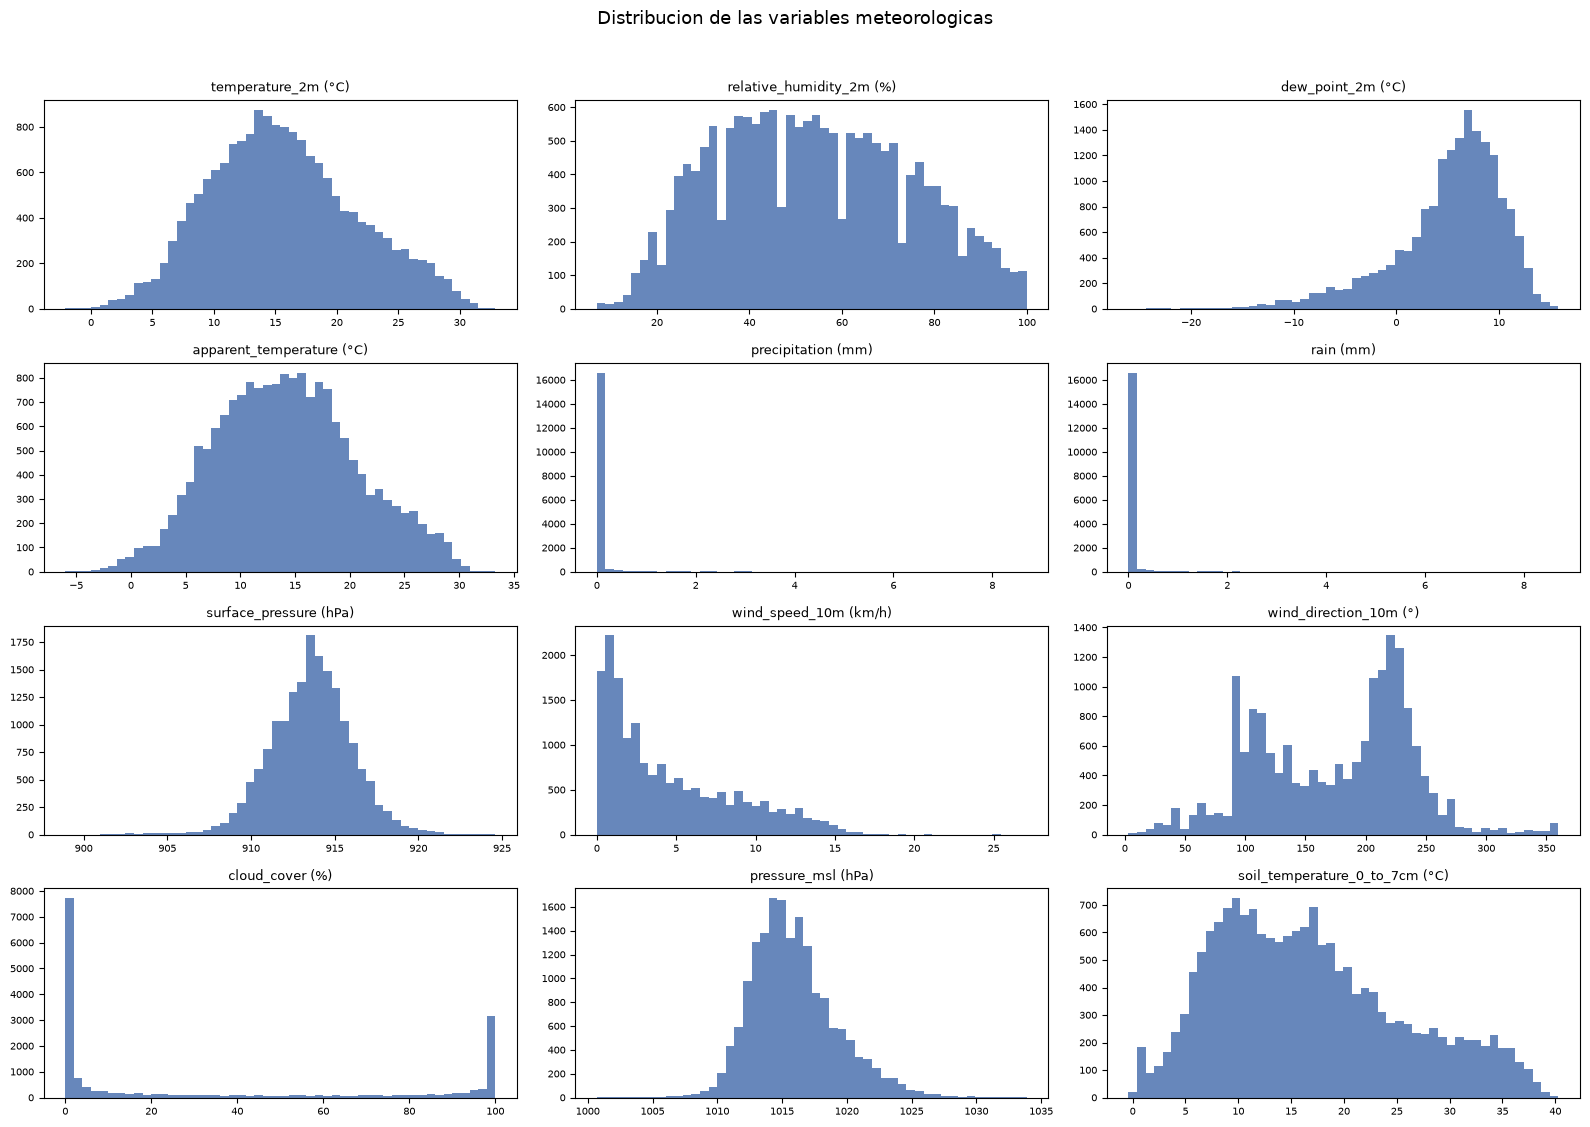

In [ ]:
num = df.drop(columns=["time"])

fig, axes = plt.subplots(4, 3, figsize=(16, 11))
axes = axes.ravel()
for ax, c in zip(axes, num.columns):
    ax.hist(num[c], bins=50, color="#4C72B0", alpha=0.85)
    ax.set_title(c, fontsize=9)
    ax.tick_params(labelsize=7)
plt.suptitle("Distribucion de las variables meteorologicas", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Los histogramas muestran tres patrones: la precipitación y la lluvia son *zero-inflated*, donde la mayoría de horas no llueve, la humedad y la cobertura de nubes son bimodales, así teniendo días despejados frente a días nublados, y las temperaturas se concentran alrededor de un valor central, con una forma de campana simétrica. La dirección del viento es angular (0° a 360°), por lo que hay que tratarla antes de usarla.

### Correlación entre variables

Dado que las variables atmosféricas suelen estar fuertemente correlacionadas, calculamos la matriz de correlación.

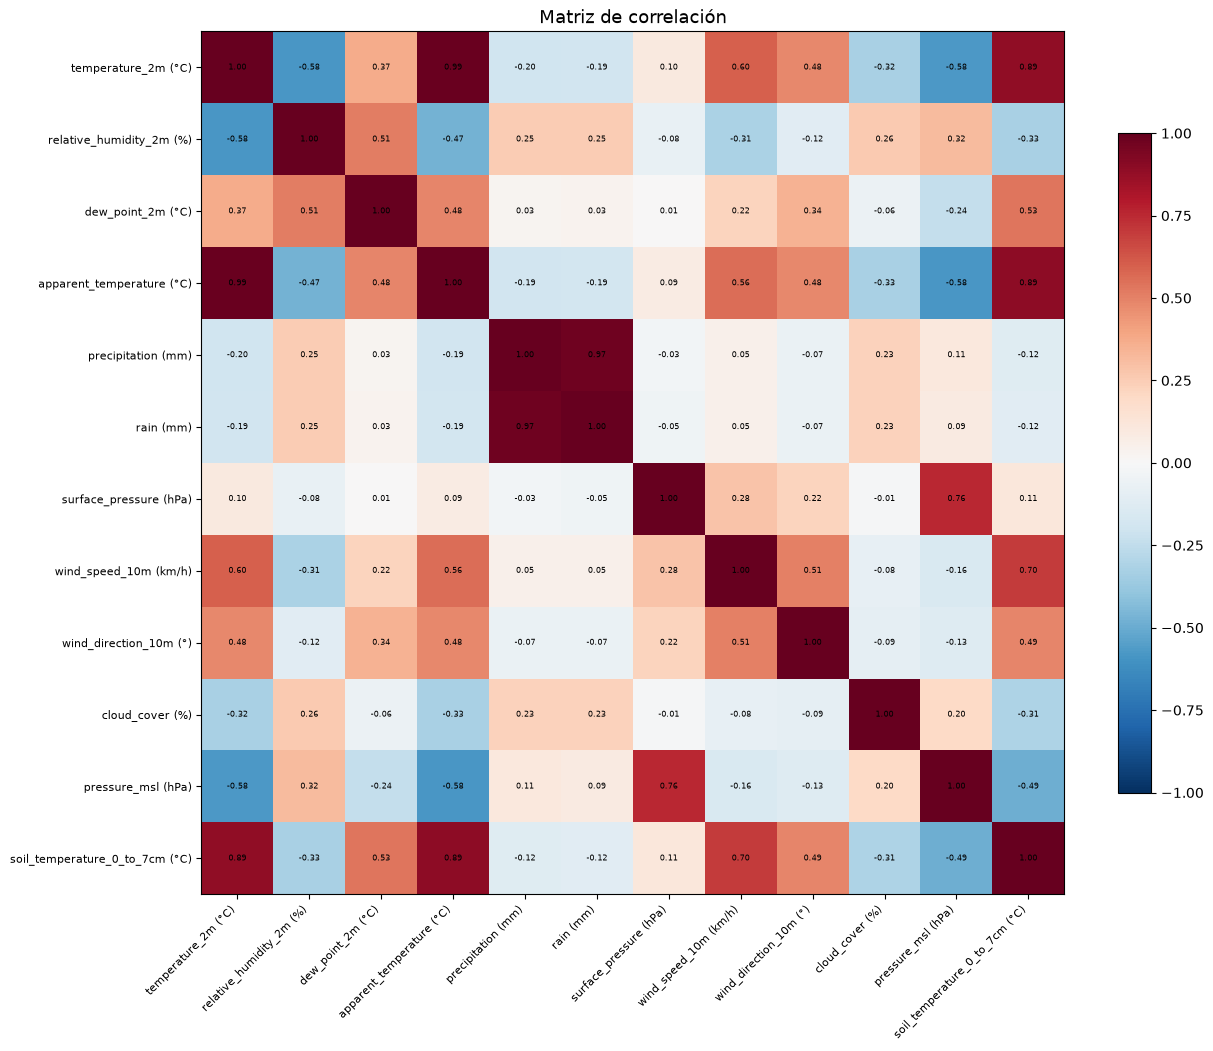

In [ ]:
corr = num.corr()

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, shrink=0.7)
plt.title("Matriz de correlación", fontsize=13)
plt.tight_layout()
plt.show()

La matriz revela **redundancias importantes** ($|r| > 0.85$): `temperature_2m` con `apparent_temperature` ($r = 0.99$), `precipitation` con `rain` ($r = 0.97$) y `temperature_2m` con `soil_temperature` ($r = 0.89$). Además `surface_pressure` y `pressure_msl` presentan $r = 0.76$ (misma magnitud física con distinta referencia). Estas variables casi duplicadas aportan poca información nueva y conviene descartarlas en el preprocesamiento.

## 3. Preprocesamiento

Antes de reducir la dimensionalidad y agrupar, aplicamos dos pasos de preprocesamiento, ambos justificados por el análisis exploratorio de la sección 2.

1. **Descarte de variables redundantes.** La matriz de correlación mostró pares casi duplicados: `rain` con `precipitation` ($r = 0.97$), `apparent_temperature` con `temperature_2m` ($r = 0.99$) y `surface_pressure` con `pressure_msl` ($r = 0.76$). Conservamos la variable físicamente más general de cada par y descartamos la otra, para no dar peso doble a la misma información.

2. **Descomposición circular de la dirección del viento.** `wind_direction_10m` es una variable angular en el rango 0–360°, donde 3° y 357° son casi la misma dirección pero numéricamente muy distantes. Como los algoritmos de agrupamiento usan distancia euclidiana, esta discontinuidad crearía artefactos en los datos, por lo que se transforma a la dirección en sus dos componentes $\sin{(\theta)}$ y $\cos{(\theta)}$, que sí varían de forma continua.

In [ ]:
# 1) Descarte de variables redundantes (alta correlacion)
df_prep = df.drop(columns=["rain (mm)", "apparent_temperature (°C)", "surface_pressure (hPa)"])

# 2) Descomposicion circular de la direccion del viento
wd_rad = np.deg2rad(df_prep["wind_direction_10m (°)"])
df_prep["wind_dir_sin"] = np.sin(wd_rad)
df_prep["wind_dir_cos"] = np.cos(wd_rad)
df_prep = df_prep.drop(columns=["wind_direction_10m (°)"])

print("Columnas finales:")
print(df_prep.columns.tolist())
print("Dimensiones:", df_prep.shape)

Columnas finales:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)', 'precipitation (mm)', 'wind_speed_10m (km/h)', 'cloud_cover (%)', 'pressure_msl (hPa)', 'soil_temperature_0_to_7cm (°C)', 'wind_dir_sin', 'wind_dir_cos']
Dimensiones: (17544, 11)


Separamos la matriz de características `X` de la columna `time`, que conservamos aparte para el análisis temporal de la sección 8.

In [ ]:
FEATURES = [c for c in df_prep.columns if c != "time"]

X = df_prep[FEATURES].copy()

print("Caracteristicas para clustering:", len(FEATURES))
print("Forma de X:", X.shape)
X.describe().T[["mean", "std", "min", "max"]].round(3)

Caracteristicas para clustering: 10
Forma de X: (17544, 10)


,mean,std,min,max
temperature_2m (°C),15.603,5.957,-2.1,32.9
relative_humidity_2m (%),54.061,20.512,7.0,100.0
dew_point_2m (°C),5.137,5.361,-26.1,15.8
precipitation (mm),0.070,0.416,0.0,8.7
wind_speed_10m (km/h),4.572,4.071,0.0,27.1
cloud_cover (%),34.383,41.838,0.0,100.0
pressure_msl (hPa),1015.922,3.345,1000.7,1033.9
soil_temperature_0_to_7cm (°C),16.718,8.830,-0.4,40.3
wind_dir_sin,0.019,0.728,-1.0,1.0
wind_dir_cos,-0.517,0.449,-1.0,1.0


Tras el preprocesamiento quedan **10 características** y **17.544 observaciones**, cumpliendo el mínimo del enunciado. La tabla descriptiva confirma que las escalas siguen siendo muy heterogéneas, es decir, compuestas por variables de magnitudes muy distintas, lo que motiva la estandarización.

## 4. Reducción de dimensionalidad (PCA)

Como las variables atmosféricas están fuertemente correlacionadas, aplicamos **Análisis de Componentes Principales (PCA)** para reducir la dimensionalidad espacial, eliminando redundancia y reteniendo la mayor parte de la varianza.

### 4.1 Estandarización previa

PCA es sensible a la escala. Como las variables tienen magnitudes muy distintas, primero las estandarizamos a media 0 y desviación 1, para que todas contribuyan por igual a la distancia.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Forma de X_scaled:", X_scaled.shape)
print("Media por columna:", X_scaled.mean(axis=0).round(6))
print("Desviacion estandar por columna:", X_scaled.std(axis=0).round(6))

Forma de X_scaled: (17544, 10)
Media por columna: [-0. -0.  0. -0.  0. -0.  0.  0. -0. -0.]
Desviacion estandar por columna: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4.2 Varianza explicada y regla de Kaiser

Ajustamos PCA sin limitar el número de componentes y observamos la varianza explicada por cada uno.

In [ ]:
pca = PCA()
pca.fit(X_scaled)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

print("Varianza explicada por componente:")
for i, (e, c) in enumerate(zip(evr, cum), 1):
    print(f"  PC{i:2d}: {e*100:6.2f}%   acumulado {c*100:6.2f}%")

Varianza explicada por componente:
  PC 1:  38.18%   acumulado  38.18%
  PC 2:  17.44%   acumulado  55.63%
  PC 3:  12.64%   acumulado  68.27%
  PC 4:   9.98%   acumulado  78.25%
  PC 5:   7.60%   acumulado  85.85%
  PC 6:   6.40%   acumulado  92.25%
  PC 7:   4.07%   acumulado  96.32%
  PC 8:   2.71%   acumulado  99.03%
  PC 9:   0.79%   acumulado  99.82%
  PC10:   0.18%   acumulado 100.00%


En datos estandarizados, el autovalor de cada componente es su varianza. La **regla de Kaiser** sugiere retener los componentes con autovalor mayor que 1, es decir, los que aportan más varianza que una variable original.

In [ ]:
ev = pca.explained_variance_
print("Autovalores:", ev.round(3).tolist())
print("Componentes con autovalor > 1:", int((ev > 1).sum()))

Autovalores: [3.819, 1.744, 1.264, 0.998, 0.76, 0.64, 0.407, 0.271, 0.079, 0.018]
Componentes con autovalor > 1: 3


### 4.3 Gráfico de codo y varianza acumulada

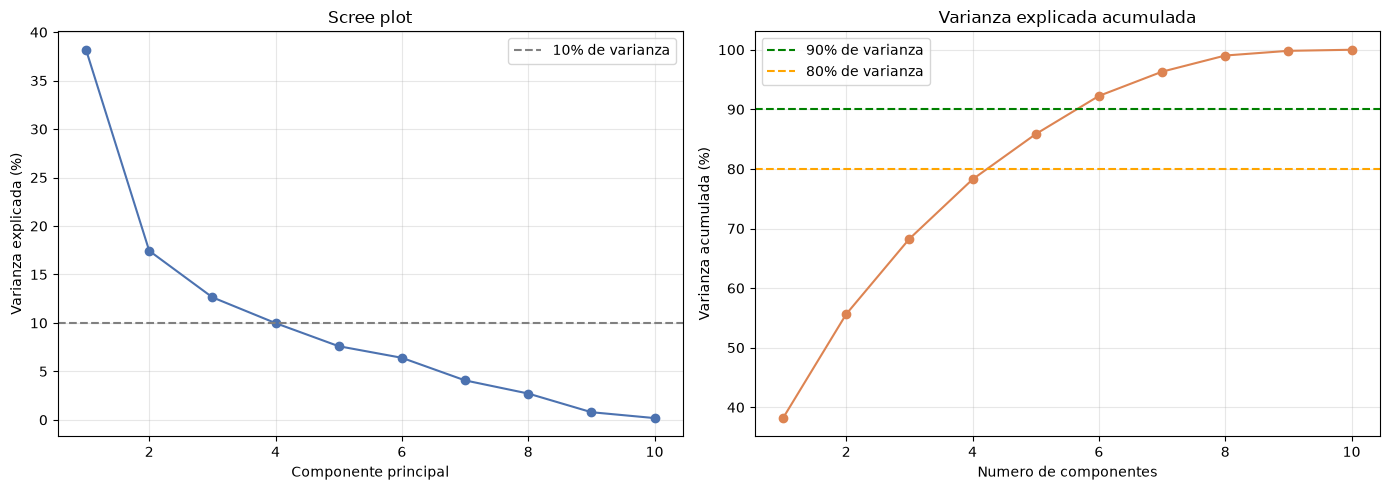

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(evr) + 1), evr * 100, "o-", color="#4C72B0")
axes[0].axhline(y=10, color="gray", linestyle="--", label="10% de varianza")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_title("Scree plot")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(cum) + 1), cum * 100, "o-", color="#DD8452")
axes[1].axhline(y=90, color="green", linestyle="--", label="90% de varianza")
axes[1].axhline(y=80, color="orange", linestyle="--", label="80% de varianza")
axes[1].set_xlabel("Numero de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title("Varianza explicada acumulada")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Justificación del número de componentes

La varianza acumulada muestra que los tres primeros componentes concentran el 68.3% de la varianza (coincide con la regla de Kaiser, que sugiere 3), pero con 6 componentes se alcanza el **92.25%**, superando el umbral habitual del 90%. Retenemos **6 componentes** por dos razones: mantener solo 3 descartaría cerca de un tercio de la información, arriesgando perder matices relevantes para detectar la tormenta; y quedarnos con más de 6 apenas suma varianza (los últimos cuatro componentes aportan menos de 8% en total y corresponden a ruido). El umbral del 90% equilibra retener información y eliminar redundancia, lo que hace el agrupamiento geométricamente más estable.

In [ ]:
K = 6
pca = PCA(n_components=K)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada con", K, "componentes:", pca.explained_variance_ratio_.sum().round(4))
print("Forma de X_pca:", X_pca.shape)

Varianza explicada con 6 componentes: 0.9225
Forma de X_pca: (17544, 6)


### 4.5 Interpretación de los componentes (loadings)

Los *loadings* indican el peso de cada variable original en cada componente, lo que permite interpretarlos físicamente.

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=FEATURES,
    columns=[f"PC{i+1}" for i in range(K)],
)
loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
temperature_2m (°C),0.48,-0.11,0.07,0.11,0.07,0.02
relative_humidity_2m (%),-0.24,0.59,0.30,-0.18,-0.05,-0.01
dew_point_2m (°C),0.22,0.53,0.45,-0.13,0.05,0.02
precipitation (mm),-0.11,0.32,-0.11,0.74,-0.45,-0.27
wind_speed_10m (km/h),0.38,0.14,-0.36,0.15,-0.15,0.21
cloud_cover (%),-0.19,0.29,-0.29,0.34,0.77,0.23
pressure_msl (hPa),-0.28,0.18,-0.42,-0.31,-0.39,0.43
soil_temperature_0_to_7cm (°C),0.48,0.08,0.10,0.07,-0.04,0.03
wind_dir_sin,-0.37,-0.22,0.20,0.12,0.04,-0.37
wind_dir_cos,-0.16,-0.25,0.50,0.37,-0.12,0.71


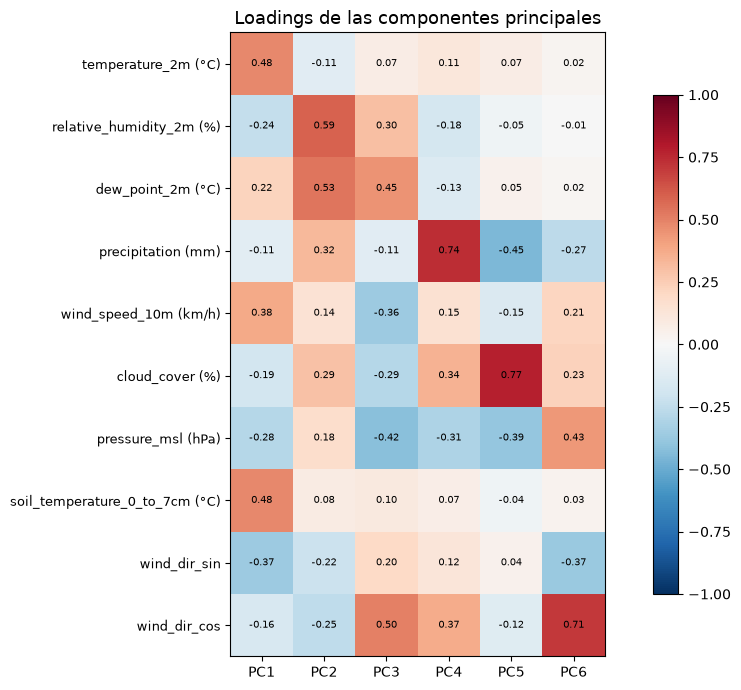

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(loadings.index, fontsize=9)
for i in range(len(FEATURES)):
    for j in range(K):
        ax.text(j, i, f"{loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=0.8)
plt.title("Loadings de las componentes principales", fontsize=13)
plt.tight_layout()
plt.show()

Los componentes principales se interpretan así:

* **Eje térmico - PC1 - 38.2%** Son las cargas positivas altas en `temperature_2m`, `soil_temperature` y `wind_speed`, y negativas en `pressure_msl` y `relative_humidity`. Separa condiciones cálidas y de baja presión de condiciones frías y de alta presión, capturando el ciclo de temperatura (diurno y estacional).

* **Eje de nubosidad - PC2 - 17.4%** Son las cargas positivas en `relative_humidity`, `dew_point`, `precipitation` y `cloud_cover`. Distingue episodios húmedos y nublados de secos y despejados.

* **Eje de viento y presión - PC3 - 12.6%** Son las cargas dominadas por `wind_dir_cos`, `pressure_msl`, `wind_speed` y `dew_point`. Captura la dirección del viento junto con los cambios de presión asociados en los frentes meteorológicos.

Los componentes restantes **PC4 - PC5 - PC6** solo aportan el 10%, 7.6% y 6.4% correspondientemente, recogiendo datos de interacción entre precipitación, nubosidad y presión que también importan de las anomalías.

## 5. Clustering

Aplicamos dos enfoques de agrupamiento sobre el espacio reducido `X_pca` (6 componentes): Primero una partición por centroides utilizando el algoritmo K-Means y luego un agrupamiento por densidad con DBSCAN.

### 5.1 K-Means 
K-Means asigna cada observación al centroide más cercano y minimiza la varianza dentro de cada clúster. Para elegir el número de clústeres $k$ combinamos el **método del codo** (inercia o WCSS) con el **coeficiente de Silhouette**, evaluando $k$ de 2 a 10.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Ks = range(2, 11)
inertias, sils = [], []
for k in Ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, labels))

for k, i, s in zip(Ks, inertias, sils):
    print(f"k={k:2d}   inercia={i:9.1f}   silhouette={s:.4f}")

k= 2   inercia= 114919.4   silhouette=0.2700
k= 3   inercia=  97033.8   silhouette=0.2516
k= 4   inercia=  83210.1   silhouette=0.2551
k= 5   inercia=  70830.5   silhouette=0.2682
k= 6   inercia=  63207.3   silhouette=0.2380
k= 7   inercia=  58058.8   silhouette=0.2499
k= 8   inercia=  54169.0   silhouette=0.2245
k= 9   inercia=  51085.8   silhouette=0.2334
k=10   inercia=  48378.0   silhouette=0.2341


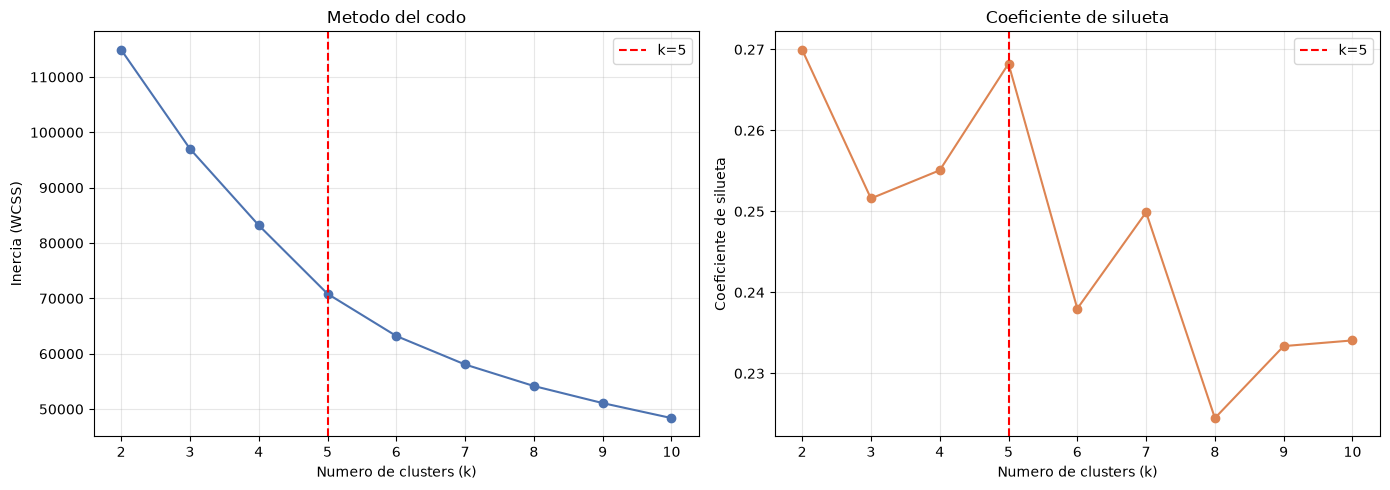

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(Ks), inertias, "o-", color="#4C72B0")
axes[0].set_xlabel("Numero de clusters (k)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Metodo del codo")
axes[0].axvline(x=5, color="red", linestyle="--", label="k=5")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(list(Ks), sils, "o-", color="#DD8452")
axes[1].set_xlabel("Numero de clusters (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Coeficiente de silueta")
axes[1].axvline(x=5, color="red", linestyle="--", label="k=5")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Elegimos $k = 5$ por dos razones. El codo de la inercia se ubica en 5: el decremento marginal se aplana claramente después de ese punto, y el Silhouette es máximo, excluyendo el caso trivial con $k = 2$, y con $k = 5$ se obtiene 0.268.

In [ ]:
km = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10)
labels_km = km.fit_predict(X_pca)

print("Tamano de cada cluster:")
for lbl in range(5):
    n = int((labels_km == lbl).sum())
    print(f"  Cluster {lbl}: {n:5d}  ({n/len(labels_km)*100:5.2f}%)")

Tamano de cada cluster:
  Cluster 0:  5204  (29.66%)
  Cluster 1:  4264  (24.30%)
  Cluster 2:  2967  (16.91%)
  Cluster 3:  4817  (27.46%)
  Cluster 4:   292  ( 1.66%)


Para interpretar el significado físico de cada estado, calculamos la media de las variables originales dentro de cada clúster.

In [ ]:
df_prep["cluster_km"] = labels_km

df_prep.groupby("cluster_km")[FEATURES].mean().round(2)

,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),precipitation (mm),wind_speed_10m (km/h),cloud_cover (%),pressure_msl (hPa),soil_temperature_0_to_7cm (°C),wind_dir_sin,wind_dir_cos
cluster_km,,,,,,,,,,
0,22.53,38.25,6.81,0.00,9.30,16.87,1014.27,26.94,-0.64,-0.70
1,15.45,63.67,8.23,0.01,1.48,10.80,1014.31,16.84,0.29,-0.26
2,10.84,38.71,-3.66,0.00,1.65,35.09,1017.22,6.81,0.76,-0.28
3,11.65,70.08,5.96,0.07,3.92,70.11,1018.22,12.08,0.00,-0.70
4,8.07,87.27,6.01,2.86,5.87,94.26,1017.79,9.88,0.48,-0.36


In [ ]:
for lbl in range(5):
    sub = df_prep[df_prep["cluster_km"] == lbl]
    print(f"Cluster {lbl}: precip_media={sub['precipitation (mm)'].mean():.3f} mm | "
          f"%horas con lluvia={(sub['precipitation (mm)'] > 0).mean()*100:.1f}% | "
          f"viento_max={sub['wind_speed_10m (km/h)'].max():.1f} km/h")

Cluster 0: precip_media=0.003 mm | %horas con lluvia=1.1% | viento_max=27.1 km/h
Cluster 1: precip_media=0.006 mm | %horas con lluvia=1.6% | viento_max=16.6 km/h
Cluster 2: precip_media=0.003 mm | %horas con lluvia=1.0% | viento_max=8.1 km/h
Cluster 3: precip_media=0.071 mm | %horas con lluvia=16.0% | viento_max=19.2 km/h
Cluster 4: precip_media=2.858 mm | %horas con lluvia=100.0% | viento_max=24.9 km/h


Los cinco estados descubiertos son:

| Cluster | % | Estado | Características |
|---|---|---|---|
| 0 | 29.7% | Cálido seco/ventoso | T = 22.5°C, HR = 38%, viento 9.3 km/h. |
| 1 | 24.3% | Templado suave | T = 15.5°C, HR = 64%, viento 1.5 km/h. |
| 2 | 16.9% | Frío seco | T = 10.8°C, punto rocío en −3.7°C con nubosidad de 35%. |
| 3 | 27.5% | Frío húmedo/nublado | T = 11.7°C, HR = 70%, lluvia 16% de horas. |
| 4 | **1.7%** | **Tormenta/lluvia intensa** | T = 8°C, HR = 87%, lluvia durante el 100% de horas, precipitación media de 2.86 mm. |

El **cluster 4** es claramente la firma de la tormenta: un estado poco frecuente (1.7% de las horas) caracterizado por humedad extrema, cobertura total de nubes y precipitación continua.

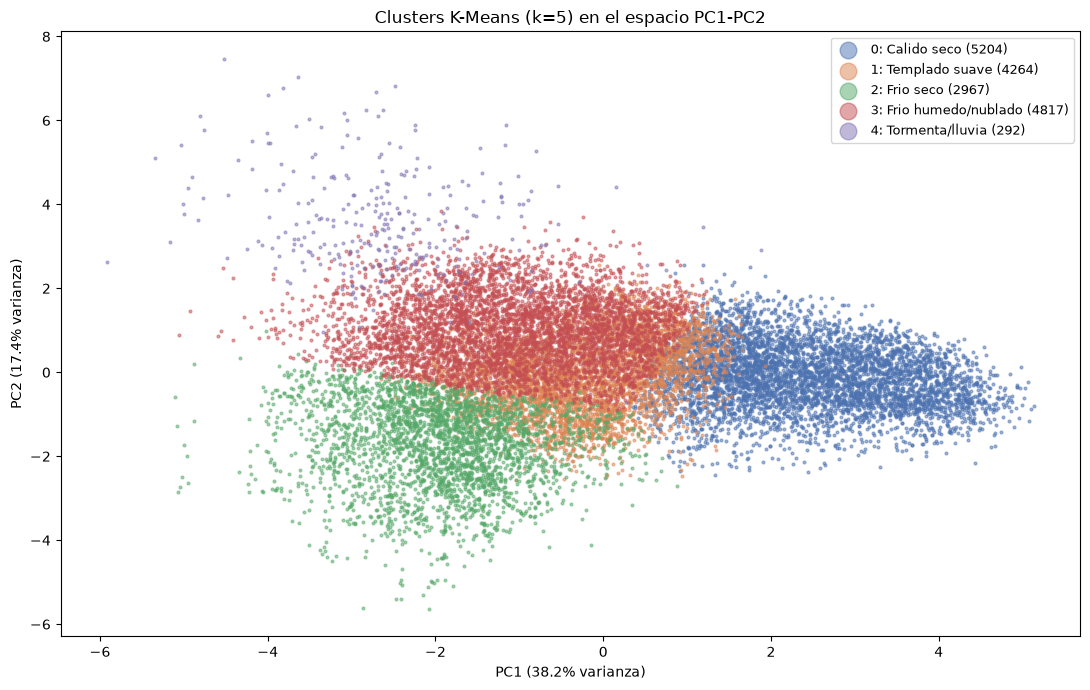

In [ ]:
nombres = {0: "Calido seco", 1: "Templado suave", 2: "Frio seco",
           3: "Frio humedo/nublado", 4: "Tormenta/lluvia"}
colores = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]

fig, ax = plt.subplots(figsize=(11, 7))
for lbl in range(5):
    m = labels_km == lbl
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=4, c=colores[lbl],
               label=f"{lbl}: {nombres[lbl]} ({m.sum()})", alpha=0.5)
ax.set_xlabel("PC1 (38.2% varianza)")
ax.set_ylabel("PC2 (17.4% varianza)")
ax.set_title("Clusters K-Means (k=5) en el espacio PC1-PC2")
ax.legend(markerscale=6, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

### 5.2 DBSCAN 

DBSCAN agrupa los datos en regiones de alta densidad y aísla las zonas dispersas como ruido (etiqueta $-1$), lo que lo hace especialmente útil para detectar anomalías sin *ground truth*. Tiene dos hiperparámetros: `eps` (radio de vecindad) y `min_samples` (mínimo de puntos para formar un núcleo denso).

In [ ]:
from sklearn.neighbors import NearestNeighbors

min_samples = 12  # 2 * numero de dimensiones (6 componentes PCA)

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_pca)
distancias, _ = nn.kneighbors(X_pca)
kdist = np.sort(distancias[:, -1])

print("Percentiles de la k-distancia:")
for p in [50, 80, 90, 95, 98, 99]:
    print(f"  percentil {p}%: {np.percentile(kdist, p):.4f}")

Percentiles de la k-distancia:
  percentil 50%: 0.5302
  percentil 80%: 0.7366
  percentil 90%: 0.8996
  percentil 95%: 1.1047
  percentil 98%: 1.4650
  percentil 99%: 1.8183


Para elegir `eps` graficamos la distancia al vecino más cercano número 12, ordenada de menor a mayor (gráfico k-distance). El codo de esta curva indica el umbral de densidad.

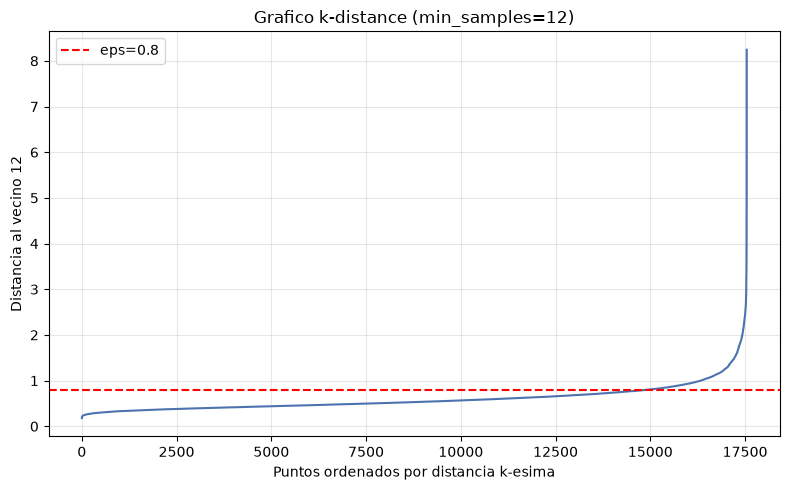

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, len(kdist) + 1), kdist, color="#4C72B0")
ax.axhline(y=0.8, color="red", linestyle="--", label="eps=0.8")
ax.set_xlabel("Puntos ordenados por distancia k-esima")
ax.set_ylabel("Distancia al vecino 12")
ax.set_title("Grafico k-distance (min_samples=12)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El codo se sitúa alrededor de `eps = 0.8`, por lo que elegimos `eps = 0.8` y `min_samples = 12`.

In [ ]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=12)
labels_db = db.fit_predict(X_pca)

import collections
print("Distribucion de etiquetas (label -1 = ruido/anomalia):")
for lbl, cnt in sorted(collections.Counter(labels_db).items()):
    print(f"  etiqueta {lbl}: {cnt}")

Distribucion de etiquetas (label -1 = ruido/anomalia):
  etiqueta -1: 1269
  etiqueta 0: 16243
  etiqueta 1: 18
  etiqueta 2: 14


Caracterizamos físicamente cada grupo igual que con K-Means.

In [ ]:
df_prep["cluster_db"] = labels_db

for lbl in sorted(np.unique(labels_db)):
    sub = df_prep[df_prep["cluster_db"] == lbl]
    if len(sub) == 0:
        continue
    print(f"Grupo {lbl} (n={len(sub)}): "
          f"T={sub['temperature_2m (°C)'].mean():.1f} | "
          f"HR={sub['relative_humidity_2m (%)'].mean():.0f} | "
          f"precip={sub['precipitation (mm)'].mean():.2f} | "
          f"%lluvia={(sub['precipitation (mm)'] > 0).mean()*100:.0f} | "
          f"viento={sub['wind_speed_10m (km/h)'].mean():.1f} | "
          f"nubosidad={sub['cloud_cover (%)'].mean():.0f}")

Grupo -1 (n=1269): T=10.6 | HR=67 | precip=0.85 | %lluvia=54 | viento=4.4 | nubosidad=72
Grupo 0 (n=16243): T=16.0 | HR=53 | precip=0.01 | %lluvia=3 | viento=4.6 | nubosidad=31
Grupo 1 (n=18): T=8.7 | HR=85 | precip=0.98 | %lluvia=100 | viento=4.1 | nubosidad=99
Grupo 2 (n=14): T=9.3 | HR=86 | precip=1.69 | %lluvia=100 | viento=4.0 | nubosidad=99


Los grupos se interpretan de la siguiente forma:

* **Cluster 0 (92.6%):** Es el estado dominante con clima seco y templado (T = 16°C, HR = 53%, solo 3% de horas con lluvia). DBSCAN lo identifica como la gran *manifold* de clima normal.

* **Ruido / label −1 (7.2%):** Son las observaciones dispersas que no alcanzan la densidad mínima, con un clima húmedo y nublado con precipitación (54% de horas con lluvia, precipitación media 0.85 mm).

* **Micro-clústeres 1 y 2 (n = 18 y n = 14):** Son los núcleos más extremos, el 100% de horas con lluvia, con humedad entre el 85–86%, la nubosidad 99% y la temperatura 9°C. Son la firma más intensa de la tormenta, tan densa que DBSCAN los aísla como clústeres propios y no como ruido.

Verificamos el solapamiento entre el clúster de tormenta de K-Means y las anomalías de DBSCAN.

In [ ]:
tormenta_km = df_prep["cluster_km"] == 4
ruido_db = df_prep["cluster_db"] == -1

print(f"Cluster de tormenta K-Means: {int(tormenta_km.sum())} horas")
print(f"De ellas, capturadas como ruido/anomalia por DBSCAN: "
      f"{int((tormenta_km & ruido_db).sum())} "
      f"({(tormenta_km & ruido_db).sum() / tormenta_km.sum() * 100:.1f}%)")

Cluster de tormenta K-Means: 292 horas
De ellas, capturadas como ruido/anomalia por DBSCAN: 278 (95.2%)


El **95.2%** de las horas de tormenta detectadas por K-Means son identificadas por DBSCAN como ruido o anomalía. Dos algoritmos de naturaleza matemática distinta convergen en señalar el mismo subconjunto extremo como la firma de la tormenta.

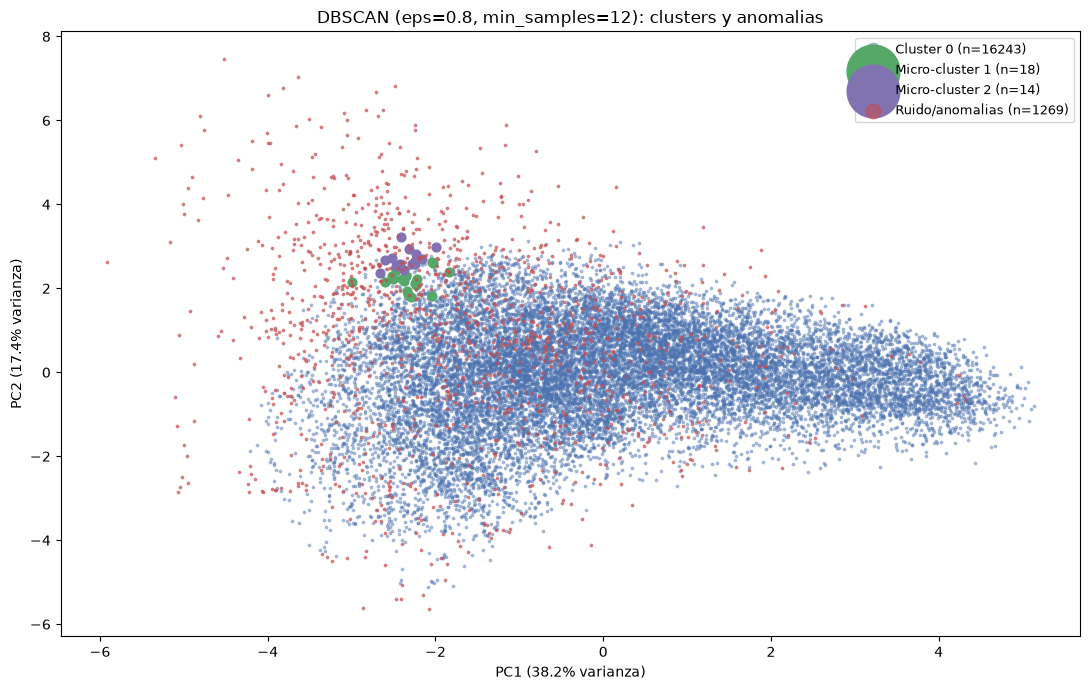

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))
m0 = labels_db == 0
ax.scatter(X_pca[m0, 0], X_pca[m0, 1], s=3, c="#4C72B0", alpha=0.4, label=f"Cluster 0 (n={m0.sum()})")
m1 = labels_db == 1
ax.scatter(X_pca[m1, 0], X_pca[m1, 1], s=40, c="#55A868", label=f"Micro-cluster 1 (n={m1.sum()})")
m2 = labels_db == 2
ax.scatter(X_pca[m2, 0], X_pca[m2, 1], s=40, c="#8172B2", label=f"Micro-cluster 2 (n={m2.sum()})")
mn = labels_db == -1
ax.scatter(X_pca[mn, 0], X_pca[mn, 1], s=3, c="#C44E52", alpha=0.6, label=f"Ruido/anomalias (n={mn.sum()})")
ax.set_xlabel("PC1 (38.2% varianza)"); ax.set_ylabel("PC2 (17.4% varianza)")
ax.set_title("DBSCAN (eps=0.8, min_samples=12): clusters y anomalias")
ax.legend(markerscale=6, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Validación interna de los agrupamientos

Como no existe *ground truth*, evaluamos la calidad de los clústeres con **métricas de validación interna**, que miden propiedades geométricas de la partición usando solo los propios datos. Usamos tres métricas complementarias.

**1. Coeficiente de Silhouette.** Para cada punto $i$, la distancia media a los puntos $a_i$ de su propio clúster y la distancia media al clúster vecino más cercano $b_i$. Se define el valor del punto como:

$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$

Y el índice global es el promedio sobre todos los puntos, $s = \frac{1}{n}\sum_i s_i$, con $s \in [-1, 1]$. Los valores cercanos a **+1** indican clústeres compactos y bien separados, los cercanos a 0 indican solapamiento entre clústeres, y los negativos representan asignaciones probablemente erróneas.

**2. Índice de Davies-Bouldin.** Para cada clúster $i$ se calcula su dispersión interna $s_i$ (distancia media al centroide) y se compara con la distancia $d_{ij}$ entre centroides:

$$DB = \frac{1}{k}\sum_{i=1}^{k} \max_{j \neq i} \left( \frac{s_i + s_j}{d_{ij}} \right).$$

A diferencia de las otras dos, aquí **valores menores indican mejor partición**: clústeres compactos (dispersión interna $s_i$ pequeña) y bien separados entre sí (distancia $d_{ij}$ grande entre sus centroides).

**3. Índice de Calinski-Harabasz.** Es el cociente entre la dispersión entre clústeres y la dispersión dentro de clústeres, normalizado por grados de libertad:

$$CH = \frac{\mathrm{tr}(B)/(k-1)}{\mathrm{tr}(W)/(n-k)},$$

Donde $B$ es la matriz de dispersión entre clústeres y $W$ la de dispersión dentro de clústeres. Si los valores son muy altos, indican clústeres más densos y mejor separados.

Para DBSCAN, las observaciones etiquetadas como ruido ($-1$) no pertenecen a ningún clúster, por lo que las métricas geométricas se calculan sobre el subconjunto con etiqueta válida, y se reporta además el porcentaje de ruido como indicador adicional propio del enfoque por densidad.

In [ ]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def metricas_internas(X, labels, nombre):
    mask = labels != -1
    Xv, lv = X[mask], labels[mask]
    sil = silhouette_score(Xv, lv)
    db = davies_bouldin_score(Xv, lv)
    ch = calinski_harabasz_score(Xv, lv)
    ruido = int((~mask).sum())
    print(f"{nombre:8s} | silhouette={sil:.4f} | davies_bouldin={db:.4f} | "
          f"calinski_harabasz={ch:.1f} | ruido={ruido} ({ruido/len(labels)*100:.2f}%)")
    return sil, db, ch, ruido

res_km = metricas_internas(X_pca, labels_km, "K-Means")
res_db = metricas_internas(X_pca, labels_db, "DBSCAN")

K-Means  | silhouette=0.2682 | davies_bouldin=1.2858 | calinski_harabasz=5633.9 | ruido=0 (0.00%)
DBSCAN   | silhouette=0.1634 | davies_bouldin=0.8400 | calinski_harabasz=38.7 | ruido=1269 (7.23%)


In [ ]:
tabla = pd.DataFrame(
    {
        "Silhouette (mayor mejor)": [res_km[0], res_db[0]],
        "Davies-Bouldin (menor mejor)": [res_km[1], res_db[1]],
        "Calinski-Harabasz (mayor mejor)": [res_km[2], res_db[2]],
        "Ruido/anomalias": [f"{res_km[3]} (0.00%)",
                           f"{res_db[3]} ({res_db[3]/len(labels_db)*100:.2f}%)"],
    },
    index=["K-Means (k=5)", "DBSCAN (eps=0.8, m=12)"],
)
tabla.round(4)

,Silhouette (mayor mejor),Davies-Bouldin (menor mejor),Calinski-Harabasz (mayor mejor),Ruido/anomalias
K-Means (k=5),0.2682,1.2858,5633.8787,0 (0.00%)
"DBSCAN (eps=0.8, m=12)",0.1634,0.8400,38.7069,1269 (7.23%)


### Interpretación de los resultados

| Métrica | K-Means (k=5) | DBSCAN | Ganador |
|---|---|---|---|
| Silhouette (mayor mejor) | **0.268** | 0.163 | K-Means |
| Davies-Bouldin (menor mejor) | 1.286 | **0.840** | DBSCAN |
| Calinski-Harabasz (mayor mejor) | **5634** | 39 | K-Means |
| Ruido aislado | 0% | **7.23%** | DBSCAN |

Las métricas no son directamente comparables entre ambos algoritmos porque optimizan objetivos distintos. **K-Means** obtiene mejor Silhouette y Calinski-Harabasz porque su objetivo es, precisamente, construir clústeres compactos y convexos minimizando la varianza interna: al forzar $k = 5$ grupos balanceados, la compacidad geométrica es alta, pero no aísla anomalías (cada punto, por raro que sea, se asigna al centroide más cercano). **DBSCAN** obtiene mejor Davies-Bouldin porque sus clústeres densos están bien separados, pero su Silhouette es menor porque su clúster dominante es una *manifold* alargada (no esférica), que la métrica penaliza. Su valor real está en la columna de ruido: identifica el 7.23% de las observaciones como dispersas, y esas son justamente las candidatas a anomalías.

La métrica adecuada depende del objetivo. Si se quiere una partición geométricamente compacta, K-Means es mejor; si se quiere **detectar anomalías aislando zonas dispersas** (el objetivo de esta tarea), DBSCAN es superior, y su menor Silhouette es el precio por no forzar cada punto a un clúster.

## 7. Discusión técnica comparativa

### 7.1 Efecto de la normalización y la métrica de distancia

Las variables atmosféricas tienen magnitudes y naturalezas muy distintas. La presión se mide en hPa, la humedad en porcentajes, la precipitación en mm y la temperatura en °C. Esta heterogeneidad de escala tiene consecuencias directas en el agrupamiento, porque tanto K-Means como DBSCAN se basan en una métrica de distancia entre puntos de los datos.

A continuación mostramos de forma empírica cómo cambian los resultados según el método de normalización y la métrica de distancia elegida.

#### Experimento 1: Normalización

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import davies_bouldin_score

print("K-Means (k=5, euclidiana) bajo distintos escalados:")
print(f"{'Escalado':20s} {'Silhouette':>11s} {'Davies-B':>9s} {'tam. min':>10s}")
for nombre, sc in [("Sin escalar", None), ("StandardScaler", StandardScaler()),
                   ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    Xs = X.values if sc is None else sc.fit_transform(X)
    Xp = PCA(n_components=6).fit_transform(Xs)
    km = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit(Xp)
    lbl = km.labels_
    sil = silhouette_score(Xp, lbl)
    db = davies_bouldin_score(Xp, lbl)
    print(f"{nombre:20s} {sil:11.4f} {db:9.4f} {min(np.bincount(lbl)):10d}")

K-Means (k=5, euclidiana) bajo distintos escalados:
Escalado              Silhouette  Davies-B   tam. min
Sin escalar               0.3850    0.8935       1589
StandardScaler            0.2682    1.2858        292
MinMaxScaler              0.3210    1.1717       2936
RobustScaler              0.2504    1.3198       2301


**Observaciones:** Al no escalar el Silhouette parece mayor con 0.385, pero es engañoso, ya que las variables de mayor rango dominan la distancia y dejan de lado a las de menor rango. El resultado es que el clúster de tormenta no emerge por lo que la señal extrema queda diluida.

Con StandardScaler, todas las variables contribuyen por igual, y el clúster extremo aparece como un grupo compacto y minoritario de 292 horas, que es la firma de la tormenta. Esta es la justificación de haber estandarizado antes del PCA y del agrupamiento.

#### Experimento 2: Efecto de la métrica de distancia en DBSCAN

In [ ]:
print("DBSCAN (eps=0.8, min_samples=12) bajo distintas metricas:")
print(f"{'Metrica':12s} {'clusters':>9s} {'ruido':>7s}")
for metrica in ["euclidean", "manhattan", "cosine"]:
    db = DBSCAN(eps=0.8, min_samples=12, metric=metrica).fit(X_pca)
    lbl = db.labels_
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nruido = int((lbl == -1).sum())
    print(f"{metrica:12s} {nc:9d} {nruido:7d}")

DBSCAN (eps=0.8, min_samples=12) bajo distintas metricas:
Metrica       clusters   ruido
euclidean            3    1269
manhattan           41   11033
cosine               1       0


**Observación clave:** El resultado es distinto según la métrica, manteniendo el mismo `eps=0.8`:

| Métrica | Clústeres | Ruido |
|---|---|---|
| Euclidiana | 3 | 1.269 (7.2%) |
| Manhattan | 41 | 11.033 (62.9%) |
| Coseno | 1 | 0 |

Podemos ver que la distancia euclidiana es la mejor opción. Tras el PCA las variables están decorrelacionadas y en unidades homogéneas, por lo que la distancia euclidiana es geométricamente significativa, la distancia Manhattan fragmenta el espacio de 41 clústeres y marca como ruido el 63% de los datos, perdiendo sentido, y la métrica coseno colapsa todo en un solo clúster, lo que elimina por completo la capacidad de detectar anomalías extremas.

#### Discusión de resultados 7.1

* **Normalización:** La estandarización es imprescindible para que las variables de baja magnitud no queden enmascaradas por las de alta magnitud. Determina la forma final de los clústeres y la sensibilidad para aislar la anomalía (el clúster de tormenta solo emerge al estandarizar).

* **Métrica de distancia:** Sobre datos decorrelacionados por PCA, la distancia euclidiana es la opción coherente y la que produce una detección de anomalías interpretable. Alternativas como distancia Manhattan o coseno anulan esa capacidad.

Luego la elección de estandarizar los datos, junto a PCA y la distancia Euclidiana logra ser la combinación que permite que la firma matemática de la tormenta emerja como una región separada y detectable.

### 7.2 Contigüidad temporal de las anomalías y ciclo de vida de la tormenta

Los algoritmos de agrupamiento evaluaron cada registro de forma independiente, sin noción del tiempo, sin embargo, las anomalías detectadas representan realmente eventos meteorológicos extremos, por lo que se podría esperar que ocurrieran de forma contigua en el tiempo, porque una tormenta es un proceso que persiste durante varias horas o días.

A continuación analizamos la distribución cronológica de las anomalías.

#### Marcado de anomalías sobre el eje temporal

Marcamos cada hora como anómala con el número $1$ o normal con el número $0$, tanto para el ruido de DBSCAN como para el clúster de tormenta de K-Means.

In [ ]:
df_prep["anom_db"] = (labels_db == -1).astype(int)
df_prep["anom_km"] = (labels_km == 4).astype(int)

print("Horas anomalas DBSCAN:", int(df_prep['anom_db'].sum()))
print("Horas anomalas K-Means:", int(df_prep['anom_km'].sum()))

Horas anomalas DBSCAN: 1269
Horas anomalas K-Means: 292


#### Detección de horas contiguas 

Identificamos tramos de horas anómalas consecutivas. Si las anomalías fueran ruido aleatorio, aparecerían aisladas, pero si son reales, formarán rachas largas de tormentas.

In [ ]:
def rachas(serie):
    runs, start = [], None
    for i, v in enumerate(serie):
        if v == 1 and start is None:
            start = i
        elif v == 0 and start is not None:
            runs.append((start, i - start)); start = None
    if start is not None:
        runs.append((start, len(serie) - start))
    return runs

for nombre, col in [("DBSCAN ruido", "anom_db"), ("KMeans cluster 4", "anom_km")]:
    r = sorted(rachas(df_prep[col].values), key=lambda x: -x[1])
    print(f"{nombre}: {int(df_prep[col].sum())} horas anomalas en {len(r)} rachas")
    print("  Rachas mas largas (inicio, duracion):")
    for inicio, largo in r[:5]:
        t = df_prep["time"].iloc[inicio]
        print(f"    {t}  ->  {largo}h ({largo/24:.1f} dias)")
    print()

DBSCAN ruido: 1269 horas anomalas en 533 rachas
  Rachas mas largas (inicio, duracion):
    2026-07-15 20:00:00  ->  65h (2.7 dias)
    2025-08-22 13:00:00  ->  34h (1.4 dias)
    2025-05-26 14:00:00  ->  23h (1.0 dias)
    2025-08-21 16:00:00  ->  19h (0.8 dias)
    2025-10-05 03:00:00  ->  17h (0.7 dias)

KMeans cluster 4: 292 horas anomalas en 103 rachas
  Rachas mas largas (inicio, duracion):
    2026-10-06 19:00:00  ->  18h (0.8 dias)
    2026-07-17 10:00:00  ->  15h (0.6 dias)
    2026-07-16 19:00:00  ->  13h (0.5 dias)
    2025-05-26 23:00:00  ->  10h (0.4 dias)
    2026-10-08 18:00:00  ->  9h (0.4 dias)



Se logra ver que las anomalías no aparecen como eventos al azar. Con DBSCAN se detecta 533 rachas contiguas, la mayor de 65 horas. K-Means detecta 103 rachas, la mayor de 18 horas. Esto indica que las observaciones extremas se agrupan en episodios temporales coherentes, consistente con la dinámica real de las tormentas.

#### Serie temporal completa de anomalías

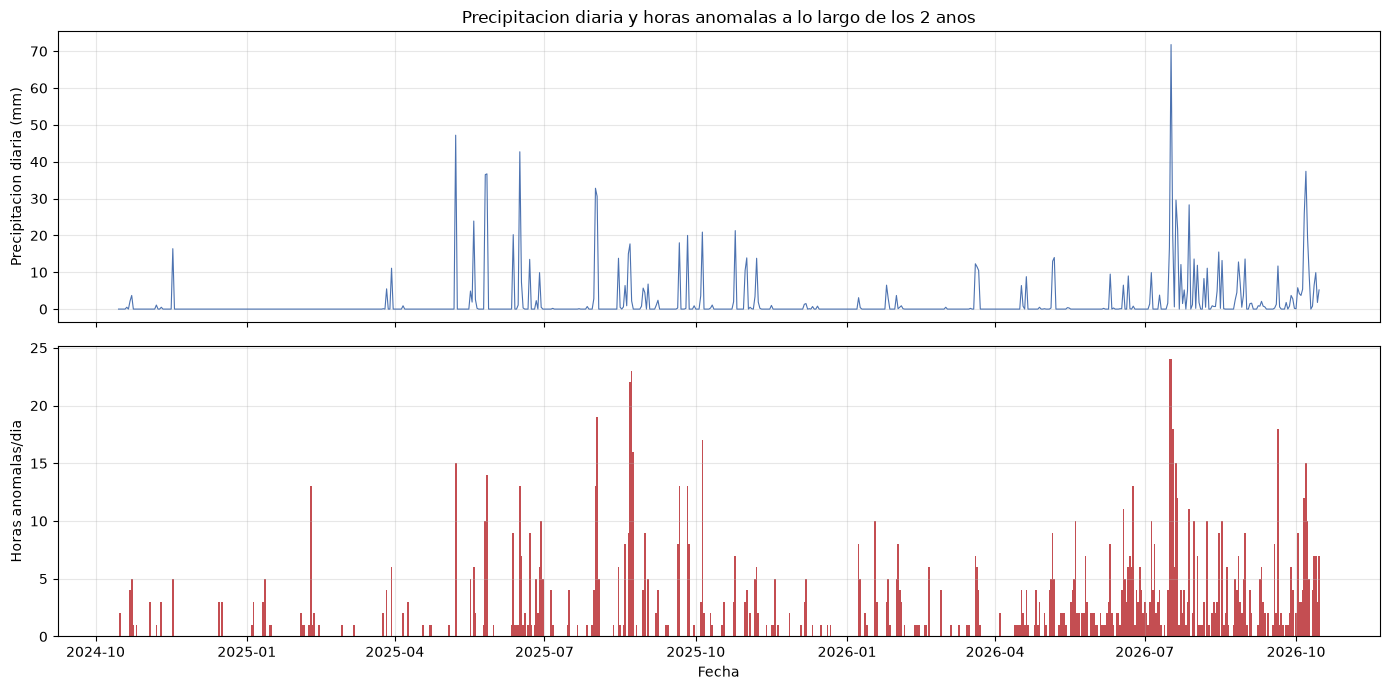

In [ ]:
df_prep["fecha"] = df_prep["time"].dt.date
diario = df_prep.groupby("fecha").agg(
    precip=("precipitation (mm)", "sum"),
    n_anom=("anom_db", "sum"),
).reset_index()
diario["fecha"] = pd.to_datetime(diario["fecha"])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(diario["fecha"], diario["precip"], color="#4C72B0", lw=0.8)
axes[0].set_ylabel("Precipitacion diaria (mm)")
axes[0].set_title("Precipitacion diaria y horas anomalas a lo largo de los 2 anos")
axes[0].grid(alpha=0.3)
axes[1].bar(diario["fecha"], diario["n_anom"], width=1.0, color="#C44E52")
axes[1].set_ylabel("Horas anomalas/dia")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Ciclo de vida de la tormenta principal

Aislamos la racha más larga desde 2026-07-15 hasta 2026-07-18 y analizamos la evolución de presión, precipitación, viento y humedad para evidenciar matemáticamente las tres etapas del ciclo de vida.

In [ ]:
t0 = pd.to_datetime("2026-07-15 12:00")
t1 = pd.to_datetime("2026-07-19 12:00")
vent = df_prep[(df_prep["time"] >= t0) & (df_prep["time"] <= t1)].reset_index(drop=True)

p = vent["pressure_msl (hPa)"].values
idx_min = int(np.argmin(p))

print("=== Evidencia matematica del ciclo de vida ===")
print(f"Presion minima (climax): {vent['time'].iloc[idx_min]}  ->  {p[idx_min]:.1f} hPa")
print(f"Fase de FORMACION: caida de presion {p[0]:.1f} -> {p[idx_min]:.1f} = {p[idx_min]-p[0]:.1f} hPa")
print(f"Fase de DISIPACION: subida {p[idx_min]:.1f} -> {p[-1]:.1f} = {p[-1]-p[idx_min]:.1f} hPa")
print(f"Pico de precipitacion: {vent['precipitation (mm)'].max():.2f} mm/h")
print(f"Pico de viento: {vent['wind_speed_10m (km/h)'].max():.1f} km/h")
print(f"Precipitacion acumulada en la ventana: {vent['precipitation (mm)'].sum():.2f} mm")
dp = np.diff(p)
print(f"Maxima caida de presion en 1h: {dp.min():.2f} hPa/h")
print(f"Maxima subida de presion en 1h: {dp.max():.2f} hPa/h")

=== Evidencia matematica del ciclo de vida ===
Presion minima (climax): 2026-07-16 10:00:00  ->  1000.7 hPa
Fase de FORMACION: caida de presion 1011.4 -> 1000.7 = -10.7 hPa
Fase de DISIPACION: subida 1000.7 -> 1011.7 = 11.0 hPa
Pico de precipitacion: 8.70 mm/h
Pico de viento: 16.6 km/h
Precipitacion acumulada en la ventana: 110.50 mm
Maxima caida de presion en 1h: -2.20 hPa/h
Maxima subida de presion en 1h: 2.20 hPa/h


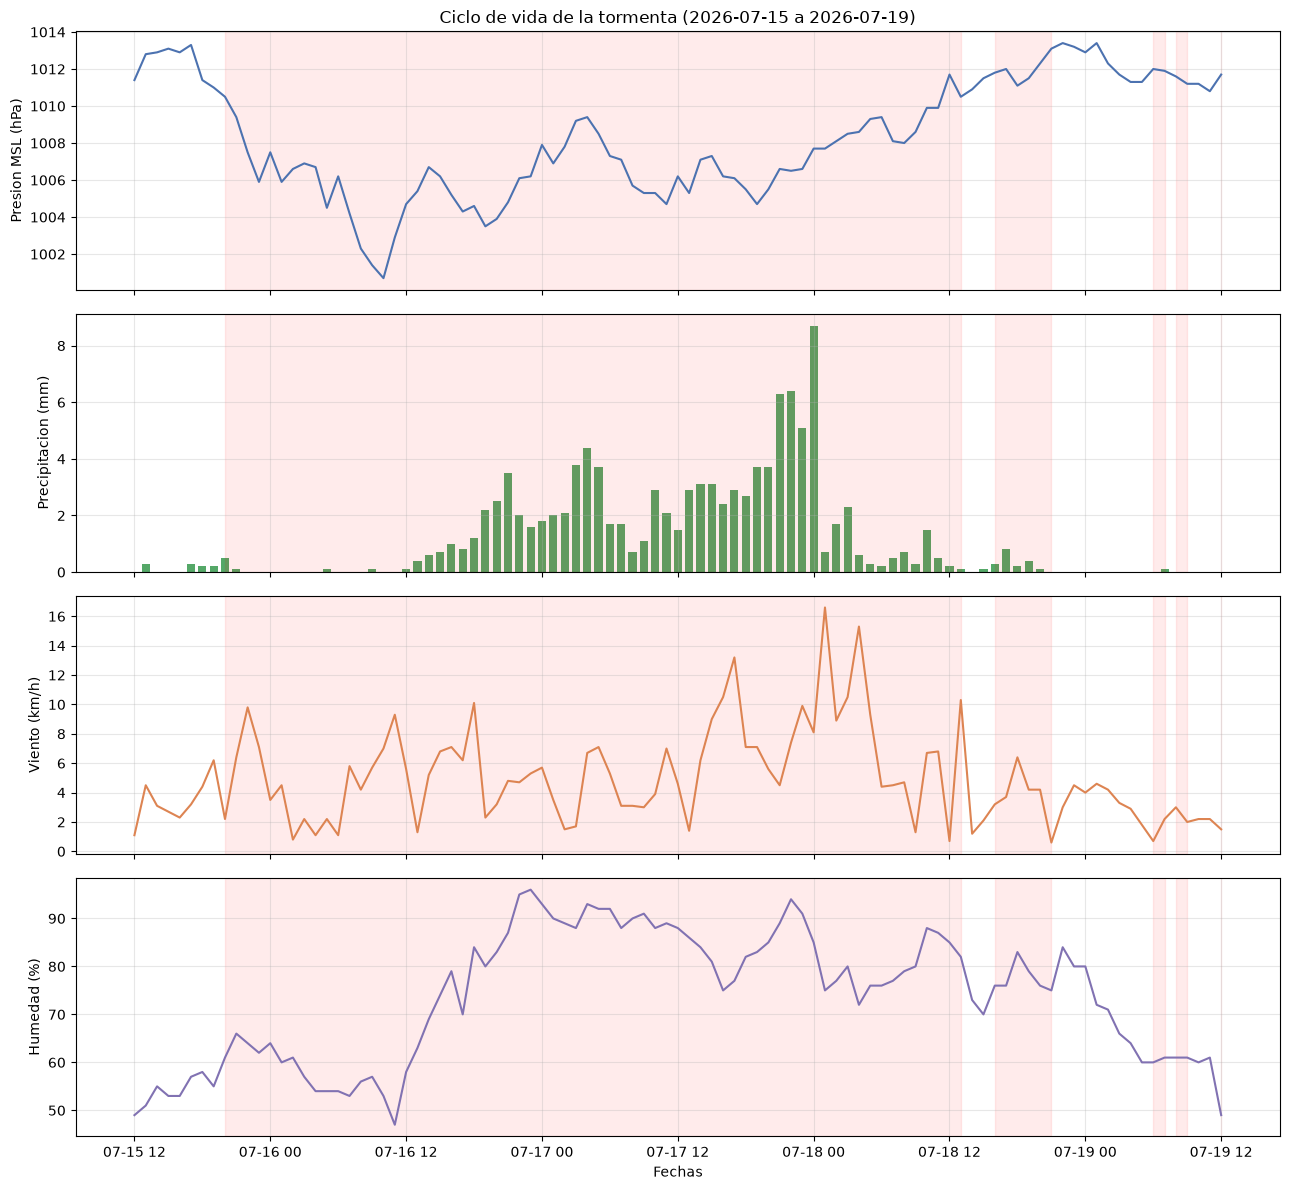

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
t = vent["time"]
axes[0].plot(t, vent["pressure_msl (hPa)"], color="#4C72B0", lw=1.5)
axes[0].set_ylabel("Presion MSL (hPa)"); axes[0].grid(alpha=0.3)
axes[1].bar(t, vent["precipitation (mm)"], width=0.03, color="#55A868")
axes[1].set_ylabel("Precipitacion (mm)"); axes[1].grid(alpha=0.3)
axes[2].plot(t, vent["wind_speed_10m (km/h)"], color="#DD8452", lw=1.5)
axes[2].set_ylabel("Viento (km/h)"); axes[2].grid(alpha=0.3)
axes[3].plot(t, vent["relative_humidity_2m (%)"], color="#8172B2", lw=1.5)
axes[3].set_ylabel("Humedad (%)"); axes[3].set_xlabel("Fechas"); axes[3].grid(alpha=0.3)

anom = vent["anom_db"].values
start = None
for i, v in enumerate(anom):
    if v == 1 and start is None:
        start = i
    elif v == 0 and start is not None:
        for ax in axes:
            ax.axvspan(t.iloc[start], t.iloc[i], color="red", alpha=0.08)
        start = None
if start is not None:
    for ax in axes:
        ax.axvspan(t.iloc[start], t.iloc[-1], color="red", alpha=0.08)

axes[0].set_title("Ciclo de vida de la tormenta (2026-07-15 a 2026-07-19)", fontsize=12)
plt.tight_layout()
plt.show()

A partir de los gráficos, la evidencia confirma las tres etapas del ciclo de vida de una tormenta:

1. **Formación:** Desde 2026-07-15 a las 20:00 hasta 2026-07-16 a las 10:00. La caída sostenida de la presión atmosférica de 10.7 hPa en 22 horas, con un gradiente máximo de −2.2 hPa/h. El descenso de presión es la firma clásica de la aproximación de un sistema de baja presión.

2. **Clímax:** 2026-07-16 a las 10:00. La presión alcanza su mínimo de 1000.7 hPa, coincidiendo con el pico de precipitación de 8.7 mm/h y un viento intenso de velocidad 16.6 km/h. En toda la ventana de una hora se acumulan 110.5 mm de lluvia, un evento extremo para Santiago.

3. **Disipación:** Desde 2026-07-16 a las 10:00 hasta 2026-07-18 a las 00:00. La presión se recupera con +11.0 hPa, la precipitación cesa y las variables vuelven a valores normales.

La zona sombreada en rojo, las anomalías de DBSCAN, coinciden con el período de baja presión y precipitación intensa, validando que el agrupamiento no supervisado recuperó un evento meteorológico real y coherente, pese a no haber usado jamás la información temporal en el modelo.

## 8. Conclusión general

En esta parte abordamos el descubrimiento de la firma matemática de la tormenta eléctrica de Santiago desde un escenario no supervisado, sin *ground truth* ni confirmación visual. Los principales hallazgos son:

1. **Datos y reducción de dimensionalidad:** Trabajamos con un dataset meteorológico de Open-Meteo con 17.544 observaciones horarias y 10 características usadas. Dada la fuerte correlación entre variables atmosféricas, aplicamos **PCA**, reteniendo 6 componentes principales que explican el **92.25%** de la varianza, con una interpretación física clara.

2. **Agrupamiento de datos con K-Means y DBSCAN:** Primero se identificó los 5 estados latentes del clima, aislando un clúster minoritario con un 1.66% de las horas, caracterizado por lluvia en el 100% de las observaciones, humedad extrema y cobertura total con la firma de la tormenta. Luego se detectó el **7.23%** de las observaciones como zonas dispersas (anomalías) y dos micro-clústeres extremos. La validación cruzada mostró que ambos métodos convergen, donde el **95.2%** de las horas de tormenta de K-Means fueron capturadas como anomalías por DBSCAN.

3. **Validación interna:** Definimos y aplicamos Silhouette, Davies-Bouldin y Calinski-Harabasz. Esto para que en K-Means obtuviera una mejor compacidad global, mientras que DBSCAN destacó en su capacidad de aislar dispersión, evidenciando que cada métrica refleja el objetivo geométrico de cada algoritmo.

4. **Rol del preprocesamiento y la distancia:** Demostramos empíricamente que la estandarización es imprescindible, sin ella el clúster de tormenta no logra emerger entre los modelos, y que la distancia Euclidiana sobre datos decorrelacionados por PCA es la única forma de producir una detección de anomalías.

5. **Ciclo de vida de la tormenta:** Aunque los algoritmos ignoraron el tiempo, las anomalías resultaron **contiguas cronológicamente**. La tormenta principal mostró las tres etapas esperadas, la formación, el clímax y la disipación. Esto valida que el enfoque no supervisado recuperó un evento meteorológico real y coherente.

En conjunto, el trabajo demuestra que es posible identificar estados climáticos y eventos extremos sin etiquetas, combinando reducción de dimensionalidad, dos paradigmas de agrupamiento y validación interna, siempre que el preprocesamiento y la métrica de distancia se elijan con criterio físico y estadístico.

# Uso de herramientas generativas

Uso de Claude para poder dejar listo la inicialización del repositorio, además de la creación del entorno virtual junto con las librerías correspondientes para el desarrollo de la tarea. También se utilizó para crear el "README.md" y lograr explicar de mejor forma la ejecución de la tarea. 